# Operator 3GPP IoT-NTN vs IoT-only LoRaWAN NTN: LEO simulator (v1.6.0, frozen version used in the paper)

**What it compares.** The same IoT scenarios served by hypothetical architectures representing two business models (infrastructure scale, spectrum and technology are confounded in the main stacks; the control stacks and sensitivity analysis separate them):

* **Operator-led 3GPP IoT-NTN**: NB-IoT / LTE-M NTN with the operator's 800 MHz (B20) spectrum reused from large direct-to-device arrays, or via an MSS partner in L-band.
* **IoT-only / non-operator LoRaWAN NTN**: LR-FHSS or LoRa on small LEO satellites, in ISM 868 MHz (licence-exempt devices, non-protected satellite assignments) or licensed S-band.
* **Same-band control**: NB-IoT, LR-FHSS and LoRa on the same satellite, band and transmit power, so only the air interface differs.

**Comparison dimensions.** Path loss, itemised link budget, link margin, coverage probability, cell and service radius, time coverage at the site, interference (ISM noise rise, co-channel terrestrial UEs), per-device throughput, goodput versus load, capacity per cell and per km², delivery within deadline, latency, energy per message and battery life, plus a sensitivity analysis.

**Two delivery metrics.** `pdr_deadline` is uplink reception at the satellite (transparent payload: at the gateway); for 3GPP stacks the random-access response, every uplink grant and the final message are downlink messages that gate it. `pdr_confirmed_deadline` also requires the acknowledgement before the deadline (LoRaWAN: confirmed mode with RX1/RX2 windows, duty cycle and half-duplex gateway). Ground-segment availability is not modelled.

**Read before using results.** Satellite and constellation presets are *illustrative classes*, not a specific operator's design. ISM activity levels, Doppler tolerances, LR-FHSS SNR thresholds and device current profiles are *assumptions* exposed as parameters. NB-IoT/LTE-M Eb/N0 and floor rates are *back-solved* to the 3GPP MCL targets. TR 38.811 clutter tables are S-band values applied at sub-GHz (extrapolation). Economic prices are left empty on purpose. Nothing here is a measurement.

Run the cells top to bottom. The first cell writes the `ntnsim` package (pure Python standard library; matplotlib only for figures).

In [1]:
import os
os.makedirs('ntnsim', exist_ok=True)
open('ntnsim/__init__.py','w').close()
print('package folder ready')

package folder ready


In [2]:
%%writefile ntnsim/rng.py
"""Portable seeded random generator.

mulberry32 is used so the HTML/JavaScript port can reproduce identical draws:

    function mulberry32(a){return function(){a|=0;a=a+0x6D2B79F5|0;
      var t=Math.imul(a^a>>>15,1|a);t=t+Math.imul(t^t>>>7,61|t)^t;
      return((t^t>>>14)>>>0)/4294967296;}}

Every derived draw (normal, Poisson, exponential, Rician power) is built from
random() only, with the same algorithm in both languages.
"""
import math

_M = 0xFFFFFFFF


def _imul(a, b):
    return (a * b) & _M


class Rng:
    def __init__(self, seed=12345):
        self.s = seed & _M
        self._spare = None

    def random(self):
        self.s = (self.s + 0x6D2B79F5) & _M
        a = self.s
        t = _imul(a ^ (a >> 15), 1 | a)
        t = ((t + _imul(t ^ (t >> 7), 61 | t)) & _M) ^ t
        return ((t ^ (t >> 14)) & _M) / 4294967296.0

    def uniform(self, lo, hi):
        return lo + (hi - lo) * self.random()

    def randint(self, n):
        """Integer in [0, n)."""
        return min(int(self.random() * n), n - 1)

    def normal(self, mu=0.0, sigma=1.0):
        """Box-Muller, caching the second variate (same order in JS)."""
        if self._spare is not None:
            z, self._spare = self._spare, None
            return mu + sigma * z
        u1 = self.random()
        while u1 <= 1e-300:
            u1 = self.random()
        u2 = self.random()
        r = math.sqrt(-2.0 * math.log(u1))
        z0 = r * math.cos(2.0 * math.pi * u2)
        self._spare = r * math.sin(2.0 * math.pi * u2)
        return mu + sigma * z0

    def exponential(self, rate):
        return -math.log(1.0 - self.random()) / rate

    def poisson(self, mean):
        """Knuth below 30, rounded normal above (portable, adequate for MC)."""
        if mean <= 0:
            return 0
        if mean < 30:
            limit = math.exp(-mean)
            k, p = 0, self.random()
            while p > limit:
                k += 1
                p *= self.random()
            return k
        return max(0, int(round(self.normal(mean, math.sqrt(mean)))))

    def rician_power(self, k_db):
        """Unit-mean power of a Rician envelope with K-factor k_db (dB).
        k_db = None gives Rayleigh."""
        k = 0.0 if k_db is None else 10 ** (k_db / 10.0)
        s = math.sqrt(k / (k + 1.0))
        sig = math.sqrt(1.0 / (2.0 * (k + 1.0)))
        x = s + sig * self.normal()
        y = sig * self.normal()
        return x * x + y * y

Writing ntnsim/rng.py


In [3]:
%%writefile ntnsim/geometry.py
"""Orbit geometry: Walker constellations, site visibility, range, Doppler.

Circular two-body orbits on a spherical Earth with Earth rotation. No J2, no
drag. Adequate for pass timing, elevation statistics and Doppler magnitude over
a 24 h window; not an ephemeris tool.
"""
import math

RE_KM = 6371.0
MU = 398600.4418            # km^3/s^2
OMEGA_E = 7.2921159e-5      # rad/s
C_KMS = 299792.458
C_MS = 299792458.0


# ---------------------------------------------------------------- closed form
def slant_range_km(h_km, elev_deg):
    """3GPP TR 38.811 eq. for distance satellite-device at elevation angle."""
    e = math.radians(elev_deg)
    return math.sqrt((RE_KM * math.sin(e)) ** 2 + h_km ** 2 + 2 * h_km * RE_KM) - RE_KM * math.sin(e)


def central_angle_rad(h_km, elev_deg):
    e = math.radians(elev_deg)
    return math.acos(RE_KM * math.cos(e) / (RE_KM + h_km)) - e


def elev_from_central_angle_deg(h_km, psi_rad):
    r = RE_KM + h_km
    d = math.sqrt(RE_KM ** 2 + r ** 2 - 2 * RE_KM * r * math.cos(psi_rad))
    s = (r * math.cos(psi_rad) - RE_KM) / d
    return math.degrees(math.asin(max(-1.0, min(1.0, s))))


def off_nadir_deg(h_km, elev_deg):
    """Angle at the satellite between nadir and the device."""
    return math.degrees(math.asin(RE_KM * math.cos(math.radians(elev_deg)) / (RE_KM + h_km)))


def footprint_area_km2(h_km, elev_mask_deg):
    psi = central_angle_rad(h_km, elev_mask_deg)
    return 2 * math.pi * RE_KM ** 2 * (1 - math.cos(psi))


def orbital_period_s(h_km):
    return 2 * math.pi * math.sqrt((RE_KM + h_km) ** 3 / MU)


def orbital_speed_kms(h_km):
    return math.sqrt(MU / (RE_KM + h_km))


def max_doppler_hz(f_hz, h_km, elev_deg=0.0):
    """Upper bound for an overhead pass (Earth rotation neglected)."""
    v = orbital_speed_kms(h_km)
    return f_hz * v / C_KMS * RE_KM * math.cos(math.radians(elev_deg)) / (RE_KM + h_km)


# ---------------------------------------------------------------- propagation
def walker(n_sats, n_planes, inc_deg, h_km, phasing=1):
    """Walker-delta i:T/P/F. Returns list of dicts (raan, m0, inc, h)."""
    if n_sats % n_planes != 0:
        raise ValueError(f"Walker: {n_sats} satellites not divisible by {n_planes} planes")
    s = n_sats // n_planes
    sats = []
    for p in range(n_planes):
        raan = 2 * math.pi * p / n_planes
        for k in range(s):
            m0 = 2 * math.pi * k / s + 2 * math.pi * phasing * p / n_sats
            sats.append(dict(raan=raan, m0=m0, inc=math.radians(inc_deg), h=h_km))
    return sats


def sat_state(sat, t):
    """ECI position (km), velocity (km/s), acceleration (km/s^2)."""
    r = RE_KM + sat["h"]
    n = math.sqrt(MU / r ** 3)
    u = sat["m0"] + n * t
    cu, su = math.cos(u), math.sin(u)
    co, so = math.cos(sat["raan"]), math.sin(sat["raan"])
    ci, si = math.cos(sat["inc"]), math.sin(sat["inc"])
    pos = (r * (cu * co - su * ci * so), r * (cu * so + su * ci * co), r * su * si)
    v = r * n
    vel = (v * (-su * co - cu * ci * so), v * (-su * so + cu * ci * co), v * cu * si)
    acc = tuple(-MU * x / r ** 3 for x in pos)
    return pos, vel, acc


def site_state(lat_deg, lon_deg, t):
    la, lo = math.radians(lat_deg), math.radians(lon_deg) + OMEGA_E * t
    pos = (RE_KM * math.cos(la) * math.cos(lo), RE_KM * math.cos(la) * math.sin(lo), RE_KM * math.sin(la))
    vel = (-OMEGA_E * pos[1], OMEGA_E * pos[0], 0.0)
    acc = (-OMEGA_E ** 2 * pos[0], -OMEGA_E ** 2 * pos[1], 0.0)
    return pos, vel, acc


def _dot(a, b):
    return a[0] * b[0] + a[1] * b[1] + a[2] * b[2]


def look(sat, lat, lon, t):
    """Elevation (deg), range (km), range rate (km/s), range acceleration (km/s^2)."""
    ps, vs, as_ = sat_state(sat, t)
    pg, vg, ag = site_state(lat, lon, t)
    rho = (ps[0] - pg[0], ps[1] - pg[1], ps[2] - pg[2])
    vr = (vs[0] - vg[0], vs[1] - vg[1], vs[2] - vg[2])
    ar = (as_[0] - ag[0], as_[1] - ag[1], as_[2] - ag[2])
    d = math.sqrt(_dot(rho, rho))
    up = tuple(x / RE_KM for x in pg)
    el = math.degrees(math.asin(_dot(rho, up) / d))
    rr = _dot(rho, vr) / d
    rra = (_dot(vr, vr) + _dot(rho, ar) - rr * rr) / d
    return el, d, rr, rra


def visibility_timeline(const, lat, lon, t_end_s=172800.0, dt_s=10.0, mask_deg=10.0, serving="sticky"):
    """Serving satellite per time step over a horizon longer than the arrival
    window, so messages generated late in the day still see future contacts.

    serving = 'sticky': keep the current satellite while it stays above the mask
    (handover only on loss); 'best': highest elevation each step.
    A contact (pass) is a contiguous run of the SAME serving satellite.
    Returns parallel lists t, vis, sid, el, d_km, rr_kms, rra, n_vis, next_vis,
    pass_end (index of the last step of the current contact). No wrap-around.
    """
    n = int(t_end_s / dt_s)
    T, V, SID, EL, D, RR, RRA, NV = [], [], [], [], [], [], [], []
    cur = None
    for i in range(n):
        t = i * dt_s
        looks = {}
        for k, s in enumerate(const):
            el, d, rr, rra = look(s, lat, lon, t)
            if el >= mask_deg:
                looks[k] = (el, d, rr, rra)
        if serving == "sticky" and cur in looks:
            k = cur
        elif looks:
            k = max(looks, key=lambda q: looks[q][0])
        else:
            k = None
        cur = k
        T.append(t); NV.append(len(looks)); SID.append(k)
        if k is not None:
            el, d, rr, rra = looks[k]
            V.append(True); EL.append(el); D.append(d); RR.append(rr); RRA.append(rra)
        else:
            V.append(False); EL.append(None); D.append(None); RR.append(None); RRA.append(None)
    nxt = [None] * n
    j = None
    for i in range(n - 1, -1, -1):
        if V[i]:
            j = i
        nxt[i] = j
    pend = [None] * n
    e = None
    for i in range(n - 1, -1, -1):
        if V[i]:
            if e is None or SID[i + 1 if i + 1 < n else i] != SID[i] or not V[min(i + 1, n - 1)]:
                e = i
            pend[i] = e
        else:
            e = None
    return dict(t=T, vis=V, sid=SID, el=EL, d_km=D, rr_kms=RR, rra=RRA, n_vis=NV,
                next_vis=nxt, pass_end=pend, dt=dt_s, t_end=t_end_s, mask=mask_deg, serving=serving)


def coverage_stats(tl, window_s=86400.0, start_s=0.0):
    """Coverage over [start_s, start_s + window_s]. Gaps touching the window
    edges are reported as censored; no contact reports the whole window."""
    i0 = int(start_s / tl["dt"])
    n = min(len(tl["vis"]) - i0, int(window_s / tl["dt"]))
    vis = tl["vis"][i0:i0 + n]
    frac = sum(vis) / n
    gaps, run, start = [], 0, 0
    for i, v in enumerate(vis):
        if not v:
            if run == 0:
                start = i
            run += 1
        elif run:
            gaps.append((run * tl["dt"], start == 0)); run = 0
    if run:
        gaps.append((run * tl["dt"], True))
    closed = sorted(g for g, c in gaps if not c)
    allg = sorted(g for g, _ in gaps)
    V, S = tl["vis"][i0:i0 + n], tl["sid"][i0:i0 + n]
    handovers = sum(1 for i in range(1, n) if V[i] and V[i - 1] and S[i] != S[i - 1])
    contacts = sum(1 for i in range(n) if V[i] and (i == 0 or not V[i - 1] or S[i] != S[i - 1]))
    p = lambda q, g: g[min(len(g) - 1, int(q * len(g)))] if g else 0.0
    return dict(coverage_fraction=frac, n_gaps=len(gaps), n_censored_gaps=len(gaps) - len(closed),
                mean_gap_s=(sum(allg) / len(allg)) if allg else 0.0, p95_gap_s=p(0.95, allg),
                max_gap_s=allg[-1] if allg else 0.0, contacts_per_day=contacts * 86400.0 / window_s,
                handovers_per_day=handovers * 86400.0 / window_s,
                never_visible=(frac == 0))

Writing ntnsim/geometry.py


In [4]:
%%writefile ntnsim/antenna.py
"""Satellite antenna models.

Two pattern families:
  broad  - single nadir-pointing beam, cos^q pattern derived from boresight gain
           (patch / deployable antennas on small satellites).
  multibeam - large phased array forming narrow beams steered at the device;
           gain from aperture, Gaussian main lobe, planar-array scan loss.
Gain and beamwidth are always derived from the same aperture, so footprint and
gain cannot be set inconsistently.
"""
import math

C_MS = 299792458.0


def wavelength_m(f_hz):
    return C_MS / f_hz


def gain_from_aperture_dbi(area_m2, f_hz, eff=0.65):
    lam = wavelength_m(f_hz)
    return 10 * math.log10(eff * 4 * math.pi * area_m2 / lam ** 2)


def aperture_for_gain_m2(g_dbi, f_hz, eff=0.65):
    lam = wavelength_m(f_hz)
    return 10 ** (g_dbi / 10) * lam ** 2 / (eff * 4 * math.pi)


def beamwidth_from_aperture_deg(area_m2, f_hz):
    """-3 dB full beamwidth ~ 70 lambda / D for a uniformly illuminated aperture."""
    d = math.sqrt(4 * area_m2 / math.pi)
    return 70.0 * wavelength_m(f_hz) / d


def bessel_j1(x):
    """J1(x), Numerical Recipes rational/asymptotic approximation (portable)."""
    ax = abs(x)
    if ax < 8.0:
        y = x * x
        a1 = x * (72362614232.0 + y * (-7895059235.0 + y * (242396853.1 + y * (-2972611.439
             + y * (15704.48260 + y * (-30.16036606))))))
        a2 = 144725228442.0 + y * (2300535178.0 + y * (18583304.74 + y * (99447.43394
             + y * (376.9991397 + y))))
        return a1 / a2
    z = 8.0 / ax
    y = z * z
    xx = ax - 2.356194491
    a1 = 1.0 + y * (0.183105e-2 + y * (-0.3516396496e-4 + y * (0.2457520174e-5 + y * (-0.240337019e-6))))
    a2 = 0.04687499995 + y * (-0.2002690873e-3 + y * (0.8449199096e-5 + y * (-0.88228987e-6 + y * 0.105787412e-6)))
    ans = math.sqrt(0.636619772 / ax) * (math.cos(xx) * a1 - z * math.sin(xx) * a2)
    return ans if x > 0 else -ans


def airy_rel_db(sep_deg, bw_deg):
    """Circular-aperture pattern [2 J1(x)/x]^2, scaled so the -3 dB full width
    equals bw_deg. Physically normalised (integral of G over the sphere <= 1)."""
    if sep_deg <= 0:
        return 0.0
    x = 1.6163 * math.sin(math.radians(min(sep_deg, 90.0))) / math.sin(math.radians(bw_deg / 2))
    v = 2 * bessel_j1(x) / x
    return 10 * math.log10(max(v * v, 1e-12))


def s1528_rel_db(sep_deg, bw_deg, g0_dbi, ln_db=-20.0, lf_dbi=0.0, alpha=1.5, z=1.0):
    """ITU-R S.1528 recommends 1.2 envelope (circular beam, z = 1), relative to
    peak; main-lobe exponent alpha = 1.5 per recommends 1.2 (external review;
    pin the recommendation revision before publication). Back lobe for
    90-180 deg: L_B = max(15 + L_N + 0.25 G_m + 5 log10 z, 0) dBi (N06).
    The elliptical-beam branches (z > 1) are not implemented: scanned beams
    use the equivalent-angle ellipse of gain_direction(). An interference-
    assessment bound, not a realised pattern."""
    psib = bw_deg / 2
    a, b = 2.58, 6.32
    p = abs(sep_deg)
    if p > 90.0:
        return max(15.0 + ln_db + 0.25 * g0_dbi + 5 * math.log10(z), 0.0) - g0_dbi
    if p <= a * psib:
        g = -3 * (p / psib) ** alpha
    elif p <= b * psib:
        g = ln_db
    else:
        y = b * psib * 10 ** (0.04 * (g0_dbi + ln_db - lf_dbi))
        g = ln_db - 25 * math.log10(p / (b * psib)) if p <= y else lf_dbi - g0_dbi
    return g


def cosq_exponent(g0_dbi):
    """q such that a cos^q(theta) pattern over a hemisphere has peak gain g0."""
    return max(10 ** (g0_dbi / 10) / 2.0 - 1.0, 0.0)


def cosq_beamwidth_deg(q):
    if q <= 0:
        return 180.0
    return 2 * math.degrees(math.acos(0.5 ** (1.0 / q)))


class SatAntenna:
    def __init__(self, cfg, f_hz):
        self.cfg = cfg
        self.f = f_hz
        self.kind = cfg["pattern"]
        self.nf_db = cfg.get("nf_db", 2.0)
        self.t_ant_k = cfg.get("t_ant_k", 290.0)
        if self.kind == "multibeam":
            self.g0 = gain_from_aperture_dbi(cfg["aperture_m2"], f_hz, cfg.get("eff", 0.65))
            self.bw = beamwidth_from_aperture_deg(cfg["aperture_m2"], f_hz)
            self.scan_k = cfg.get("scan_loss_exp", 1.2)
            self.side_model = cfg.get("sidelobe_model", "airy")   # 'airy' (realised) | 's1528' (envelope)
        else:
            self.g0 = cfg["gain_dbi"]
            self.q = cosq_exponent(self.g0)
            self.bw = cosq_beamwidth_deg(self.q)

    # T_sys and G/T ---------------------------------------------------------
    def t_sys_k(self):
        return self.t_ant_k + 290.0 * (10 ** (self.nf_db / 10) - 1)

    def g_over_t(self, gain_dbi):
        return gain_dbi - 10 * math.log10(self.t_sys_k())

    # gain toward a device ----------------------------------------------------
    def gain_toward(self, off_nadir_deg, beam_offset_frac=0.0):
        """Gain (dBi) toward a device at the given off-nadir angle.

        beam_offset_frac in [0,1]: radial position inside the -3 dB contour of
        the serving beam (multibeam only). 1.0 is the beam edge (-3 dB).
        """
        if self.kind == "multibeam":
            a = math.radians(min(off_nadir_deg, 89.0))
            scan = 10 * self.scan_k * math.log10(max(math.cos(a), 1e-3))
            off = -3.0 * beam_offset_frac ** 2
            return self.g0 + scan + off
        a = math.radians(min(off_nadir_deg, 89.9))
        return self.g0 + 10 * self.q * math.log10(max(math.cos(a), 1e-6))

    def gain_direction(self, off_nadir_deg, sep_deg, az_rad=0.0, axis_scan_deg=0.0):
        """Gain toward an arbitrary emitter: element factor at the emitter's
        off-nadir angle times the array factor at its separation from the beam
        axis (multibeam); cos^q about nadir (broad).

        The scanned array beam is elliptical (N06): its width in the scan plane
        is bw / cos(scan) and bw across it. az_rad is the emitter's azimuth
        around the beam axis measured from the scan plane. The separation is
        mapped to the circular-equivalent angle before applying the pattern, so
        wanted-signal gain, footprint and interference use one scanned pattern."""
        if self.kind == "multibeam":
            a = math.radians(min(off_nadir_deg, 89.0))
            elem = 10 * self.scan_k * math.log10(max(math.cos(a), 1e-3))
            c = max(math.cos(math.radians(axis_scan_deg)), 0.05)
            s_eq = sep_deg * math.sqrt((math.cos(az_rad) * c) ** 2 + math.sin(az_rad) ** 2)
            if self.side_model == "s1528":
                # S.1528-based scanned envelope: circular (z = 1) branches on the equivalent angle,
                # back lobe selected on the PHYSICAL separation (P08); not the full elliptical S.1528
                rel = (s1528_rel_db(sep_deg, self.bw, self.g0) if sep_deg > 90.0
                       else s1528_rel_db(min(s_eq, 90.0), self.bw, self.g0))
            else:
                rel = airy_rel_db(s_eq, self.bw)
            return self.g0 + elem + rel
        return self.gain_toward(off_nadir_deg)

    def pattern_integral(self, axis_off_nadir_deg=0.0, n_s=1200, n_b=96):
        """(1/4pi) * integral of G over the sphere (Earth-facing and space-facing
        hemisphere both counted); <= 1 for a physical antenna."""
        tot = 0.0
        smax = math.pi
        for i in range(n_s):
            sp = (i + 0.5) * smax / n_s
            for j in range(n_b):
                be = (j + 0.5) * 2 * math.pi / n_b
                # direction relative to beam axis, axis tilted by axis_off_nadir from nadir
                ta = math.radians(axis_off_nadir_deg)
                ux = math.sin(sp) * math.cos(be)
                uy = math.sin(sp) * math.sin(be)
                uz = math.cos(sp)
                # rotate about y by ta: nadir is +z in this frame
                nz = -ux * math.sin(ta) + uz * math.cos(ta)
                off = math.degrees(math.acos(max(-1.0, min(1.0, nz))))
                if off >= 90.0:
                    g = -60.0 if self.kind == "broad" else self.g0 + (s1528_rel_db(math.degrees(sp), self.bw, self.g0) if self.side_model == "s1528" else -60.0)
                else:
                    g = self.gain_direction(off, math.degrees(sp), be, axis_off_nadir_deg) if self.kind == "multibeam" else self.gain_toward(off)
                tot += 10 ** (g / 10) * math.sin(sp) * (smax / n_s) * (2 * math.pi / n_b)
        return tot / (4 * math.pi)

    def beam_spot_area_km2(self, h_km, elev_deg, slant_km):
        """Ground area of one -3 dB beam spot (multibeam). The array beam
        broadens as 1/cos(scan) in the scan plane, and the spot is stretched by
        1/sin(elevation) on the ground (F10)."""
        if self.kind != "multibeam":
            return None
        RE = 6371.0
        scan = math.asin(min(1.0, RE * math.cos(math.radians(elev_deg)) / (RE + h_km)))
        r_cross = slant_km * math.tan(math.radians(self.bw / 2))
        r_along = slant_km * math.tan(math.radians(min(self.bw / (2 * max(math.cos(scan), 0.05)), 60.0)))
        return math.pi * r_cross * r_along / max(math.sin(math.radians(elev_deg)), 0.1)

    def summary(self):
        d = dict(pattern=self.kind, boresight_gain_dbi=round(self.g0, 2),
                 beamwidth_deg=round(self.bw, 2), t_sys_k=round(self.t_sys_k(), 1),
                 g_over_t_dbk=round(self.g_over_t(self.g0), 2))
        if self.kind == "multibeam":
            d["aperture_m2"] = self.cfg["aperture_m2"]
        return d

Writing ntnsim/antenna.py


In [5]:
%%writefile ntnsim/channel.py
"""Device-to-satellite channel: 3GPP TR 38.811 Sec. 6.6 path loss model.

PL = FSPL + SF + CL (+ gas, scintillation, polarisation, device-side losses).
LOS probability: TR 38.811 Table 6.6.1-1.
Shadow fading sigma and clutter loss: TR 38.811 Tables 6.6.2-1..3, S-band
columns. 38.811 tabulates S-band and Ka-band only; applying the S-band values
at 0.8-0.9 GHz is an extrapolation and is reported as such.
"""
import math

ELEVS = [10, 20, 30, 40, 50, 60, 70, 80, 90]

LOS_PROB = {   # percent
    "dense_urban": [28.2, 33.1, 39.8, 46.8, 53.7, 61.2, 73.8, 82.0, 98.1],
    "urban":       [24.6, 38.6, 49.3, 61.3, 72.6, 80.5, 91.9, 96.8, 99.2],
    "suburban":    [78.2, 86.9, 91.9, 92.9, 93.5, 94.0, 94.9, 95.2, 99.8],
    "rural":       [78.2, 86.9, 91.9, 92.9, 93.5, 94.0, 94.9, 95.2, 99.8],
}

SBAND = {   # (sigma_LOS, sigma_NLOS, CL_NLOS) in dB
    "dense_urban": ([3.5, 3.4, 2.9, 3.0, 3.1, 2.7, 2.5, 2.3, 1.2],
                    [15.5, 13.9, 12.4, 11.7, 10.6, 10.5, 10.1, 9.2, 9.2],
                    [34.3, 30.9, 29.0, 27.7, 26.8, 26.2, 25.8, 25.5, 25.5]),
    "urban":       ([4.0] * 9, [6.0] * 9,
                    [34.3, 30.9, 29.0, 27.7, 26.8, 26.2, 25.8, 25.5, 25.5]),
    "suburban":    ([1.79, 1.14, 1.14, 0.92, 1.42, 1.56, 0.85, 0.72, 0.72],
                    [8.93, 9.08, 8.78, 10.25, 10.56, 10.74, 10.17, 11.52, 11.52],
                    [19.52, 18.17, 18.42, 18.28, 18.63, 17.68, 16.50, 16.30, 16.30]),
}
SBAND["rural"] = SBAND["suburban"]


# Angle handling is passed explicitly per call (no module state, F10/N10):
# mode = 'interp' (linear between reference angles, extrapolation mode) or
# 'nearest' (TR 38.811 reference-angle reproduction).


def _interp(table, el, mode="interp"):
    el = max(10.0, min(90.0, el))
    if mode == "nearest":
        return table[min(8, int(round((el - 10) / 10.0)))]
    i = min(int((el - 10) // 10), 7)
    w = (el - ELEVS[i]) / 10.0
    return table[i] * (1 - w) + table[i + 1] * w


def fspl_db(d_km, f_hz):
    return 32.45 + 20 * math.log10(f_hz / 1e6) + 20 * math.log10(d_km)


def los_probability(env, el, mode="interp"):
    return _interp(LOS_PROB[env], el, mode) / 100.0


def sf_cl(env, el, los, mode="interp"):
    s_los, s_nlos, cl = SBAND[env]
    if los:
        return _interp(s_los, el, mode), 0.0
    return _interp(s_nlos, el, mode), _interp(cl, el, mode)


def sample_loss_db(env, el, rng, mode="interp"):
    """Random SF + CL draw. Returns (los, extra_loss_db)."""
    los = rng.random() < los_probability(env, el, mode)
    sig, cl = sf_cl(env, el, los, mode)
    return los, rng.normal(0.0, sig) + cl


def median_loss_db(env, el, los=True, mode="interp"):
    return sf_cl(env, el, los, mode)[1]


def expected_extra_loss_db(env, el, mode="interp"):
    """LOS-probability-weighted mean of CL (SF is zero-mean)."""
    p = los_probability(env, el, mode)
    return (1 - p) * sf_cl(env, el, False, mode)[1]

Writing ntnsim/channel.py


In [6]:
%%writefile ntnsim/phy.py
"""Physical-layer models for LoRa, LR-FHSS, NB-IoT NTN and LTE-M NTN.

All links are evaluated in C/N0 form so that every technology sees the same
satellite receiver (G/T) and the same interference density:

    C/N0 = EIRP_dev - PL + G/T - k                      [dB-Hz]
    SNR(B) = C/N0_eff - 10 log10(B)

Provenance of each parameter is recorded in PARAM_SOURCES and printed with the
results. 'assumed' means a modelling choice exposed for change.
"""
import math

K_DBM = -198.6   # Boltzmann, dBm/K/Hz

# ------------------------------------------------------------------ LoRa
LORA_SNR_DB = {7: -7.5, 8: -10.0, 9: -12.5, 10: -15.0, 11: -17.5, 12: -20.0}
LORAWAN_OVERHEAD_B = 13       # MHDR1 + DevAddr4 + FCtrl1 + FCnt2 + FPort1 + MIC4


def lora_toa_s(sf, payload_phy_b, bw_hz=125e3, cr=1, n_pre=8, explicit_header=True, crc=True):
    """Semtech AN1200.13 time on air."""
    tsym = (2 ** sf) / bw_hz
    de = 1 if tsym > 0.016 else 0
    ih = 0 if explicit_header else 1
    num = 8 * payload_phy_b - 4 * sf + 28 + 16 * (1 if crc else 0) - 20 * ih
    n_payload = 8 + max(math.ceil(num / (4 * (sf - 2 * de))) * (cr + 4), 0)
    return (n_pre + 4.25) * tsym + n_payload * tsym


def lora_symbol_s(sf, bw_hz=125e3):
    return (2 ** sf) / bw_hz


def lora_rate_bps(sf, bw_hz=125e3, cr=1):
    """Information bit rate; LDRO (on when Tsym > 16 ms) removes 2 bits/symbol."""
    de = 1 if lora_symbol_s(sf, bw_hz) > 0.016 else 0
    return (sf - 2 * de) * bw_hz / 2 ** sf * 4 / (4 + cr)


def lora_doppler_ok(sf, bw_hz, f_dopp_hz, f_rate_hzps, frac=0.5):
    """Static offset within +-25 % BW and drift per symbol below frac of a bin.
    Tolerances are assumptions (see PARAM_SOURCES)."""
    if abs(f_dopp_hz) > 0.25 * bw_hz:
        return False
    return abs(f_rate_hzps) * lora_symbol_s(sf, bw_hz) <= frac * bw_hz / 2 ** sf


# ------------------------------------------------------------------ LR-FHSS
LRFHSS_DR = {
    # name: OCW (Hz), OBW channels C, header replicas, coding rate
    "DR8":  dict(ocw_hz=137e3, C=280, nh=3, cr="1/3", region="EU868"),
    "DR9":  dict(ocw_hz=137e3, C=280, nh=2, cr="2/3", region="EU868"),
    "DR10": dict(ocw_hz=336e3, C=688, nh=3, cr="1/3", region="EU868"),
    "DR11": dict(ocw_hz=336e3, C=688, nh=2, cr="2/3", region="EU868"),
    "DR5":  dict(ocw_hz=1.523e6, C=3120, nh=3, cr="1/3", region="US915"),
    "DR6":  dict(ocw_hz=1.523e6, C=3120, nh=2, cr="2/3", region="US915"),
}
LRFHSS_OBW_HZ = 488.28125
LRFHSS_TH_S = 0.233472     # header replica
LRFHSS_TF_S = 0.1024       # payload fragment
LRFHSS_SNR_DB = {"1/3": 4.0, "2/3": 7.0}


LRFHSS_GRID = {"DR8": 35, "DR9": 35, "DR10": 86, "DR11": 86, "DR5": 60, "DR6": 60}   # channels per packet grid


def lrfhss_frame(dr, payload_phy_b):
    """Frame per RP002-1.0.5: coded bits = ((L+2)*8 + 6) / CR, 48 bits per hop,
    shorter final hop of (bits_last + 2) * 2.048 ms."""
    p = LRFHSS_DR[dr]
    bits = (payload_phy_b + 2) * 8 + 6
    bits = bits * 3 if p["cr"] == "1/3" else math.ceil(bits * 3 / 2)
    nf = math.ceil(bits / 48)
    last_bits = bits - (nf - 1) * 48
    t_last = (last_bits + 2) * 0.002048
    need = math.ceil(nf / 3) if p["cr"] == "1/3" else math.ceil(2 * nf / 3)
    toa = p["nh"] * LRFHSS_TH_S + (nf - 1) * LRFHSS_TF_S + t_last
    return dict(nh=p["nh"], nf=nf, need=need, C=p["C"], grid=LRFHSS_GRID[dr], toa_s=toa,
                t_last_s=t_last, snr_req_db=LRFHSS_SNR_DB[p["cr"]], ocw_hz=p["ocw_hz"])


def lrfhss_doppler_ok(f_rate_hzps, frac=0.5):
    """Drift across one header replica below frac of an OBW channel (assumed, default 0.5)."""
    return abs(f_rate_hzps) * LRFHSS_TH_S <= frac * LRFHSS_OBW_HZ


# ------------------------------------------------------------------ 3GPP IoT-NTN
CELLULAR = {
    # Eb/N0 including implementation loss; floor rate set by max repetitions;
    # cap = practical peak over NTN; b_min = smallest uplink allocation.
    # floor back-solved: MCL_ref = Ptx_ref + 174 - NF_ref - 10log10(floor) - Eb/N0
    "NBIOT": dict(ebn0_db=5.0, floor_bps=10 ** ((23.0 + 174 - 3.0 - 5.0 - 164.0) / 10), cap_bps=20e3,
                  b_min_hz=3.75e3, eta_bps_hz=1.0, carrier_ul_hz=180e3, overhead_b=25,
                  mcl_ref_db=164.0, ref_nf_db=3.0, ref_ptx_dbm=23.0),
    # LTE-M floor from the TR 36.888 Table 9.5.7.1-3 point quoted in the RAN1 NTN
    # link-budget summary: 56-bit TBS, 250 repetitions (1 ms), 2 PRBs, SNR -27 dB.
    "LTEM":  dict(ebn0_db=5.0, floor_bps=56 / 0.250, cap_bps=300e3,
                  b_min_hz=180e3, eta_bps_hz=1.0, carrier_ul_hz=1.08e6, overhead_b=25,
                  mcl_ref_db=155.7, ref_nf_db=5.0, ref_ptx_dbm=20.0),
}


def cellular_rate_bps(tech, cn0_dbhz):
    """Link-adapted information rate from C/N0, or None if below floor."""
    p = CELLULAR[tech]
    r = 10 ** ((cn0_dbhz - p["ebn0_db"]) / 10)
    if r < p["floor_bps"]:
        return None
    return min(r, p["cap_bps"])


def cellular_mcl_check(tech):
    """Back-solve: MCL implied by floor rate, Eb/N0 and the reference NF/power."""
    p = CELLULAR[tech]
    sens = -174 + p["ref_nf_db"] + 10 * math.log10(p["floor_bps"]) + p["ebn0_db"]
    return p["ref_ptx_dbm"] - sens


def cellular_resource_hz_s(tech, rate_bps, bits):
    """Tone-time consumed: occupied bandwidth x airtime (Hz*s)."""
    p = CELLULAR[tech]
    t = bits / rate_bps
    b = max(p["b_min_hz"], rate_bps / p["eta_bps_hz"])
    return b * t, t, b


# ------------------------------------------------------------------ helpers
def noise_floor_dbm(b_hz, nf_db, t_ant_k=290.0):
    t = t_ant_k + 290.0 * (10 ** (nf_db / 10) - 1)
    return K_DBM + 10 * math.log10(t) + 10 * math.log10(b_hz)


def lora_sensitivity_dbm(sf, nf_db=6.0, bw_hz=125e3):
    return -174 + nf_db + 10 * math.log10(bw_hz) + LORA_SNR_DB[sf]


PARAM_SOURCES = {
    "LoRa SNR thresholds": "Semtech SX126x/SX127x datasheets (SF7 -7.5 dB ... SF12 -20 dB)",
    "LoRa time on air": "Semtech AN1200.13",
    "LoRaWAN MAC overhead 13 B": "LoRaWAN L2 1.0.4 frame format",
    "LoRa Doppler tolerance": "assumed: offset <= 25% BW, drift/symbol <= 0.5 bin",
    "LR-FHSS DR table": "LoRaWAN RP002-1.0.4 regional parameters",
    "LR-FHSS header/fragment durations": "233.472 ms / 102.4 ms (RP002, Boquet et al. 2021)",
    "LR-FHSS frame": "RP002-1.0.5: ((L+2)*8+6)/CR coded bits, 48 bits per hop, shorter final hop; decode needs 1/3 (CR 1/3) or 2/3 (CR 2/3) of hops",
    "LR-FHSS SNR threshold": "assumed: 4 dB (CR 1/3), 7 dB (CR 2/3)",
    "LR-FHSS Doppler tolerance": "assumed: drift over one header <= 50% of 488 Hz",
    "NB-IoT (legacy continuous model) floor 316 bit/s": "only used when nbiot_model='continuous'; back-solved to 164 dB at 23 dBm / NF 3 dB",
    "LTE-M floor 224 bit/s, Eb/N0 5 dB": "TR 36.888 Table 9.5.7.1-3 point (56 b, 250 reps, 2 PRB, -27 dB) quoted in RAN1#104e NTN summary; implies Eb/N0 5.06 dB",
    "NB-IoT NPUSCH": "TS 36.213 TBS table (Rel-13, <= 1000 bits, segmentation above) and RU structure; Shannon-gap SNR with gap fitted to TBS1000/NRU10/Nrep32/-13.8 dB, which only beta = 1.0 ('link_level') reproduces; default beta = 0.5 is a hardware-inspired curve (single-tone 3.75 kHz measurements), corroborated not calibrated by RAN4 ratios; not a validated BLER model",
    "NB-IoT HARQ": "chase combining of received energy over up to 2 attempts, feedback time RTT + 12 ms (assumed); no BLER curve",
    "NB-IoT burst rate": "reported burst_rate_bps is the PHY burst rate of the selected configuration, not transaction goodput; no 20 kbit/s cap is applied in the table model",
    "NPRACH / PRACH CE configuration": "assumed values chosen from TS 36.331 allowed sets; periodicity >= repetitions x preamble duration enforced",
    "NTN rate caps": "legacy continuous model only: NB-IoT 20 kbit/s, LTE-M 300 kbit/s (assumed); LTE-M still uses the continuous model",
    "NB-IoT/LTE-M protocol overhead 25 B": "assumed (CIoT control-plane, header compression)",
}

Writing ntnsim/phy.py


In [7]:
%%writefile ntnsim/nbiot.py
"""NB-IoT NPUSCH format 1 link model built from 3GPP structures (F07).

Structures taken from the specifications:
  * TBS table (TS 36.213 Table 16.5.1.2-2), I_TBS 0..12 x N_RU {1,2,3,4,5,6,8,10};
    Rel-13 maximum 1000 bits; larger messages are segmented into transport
    blocks, each with its own HARQ process in the engine (the Rel-14 2536-bit
    TBS extension is not implemented);
  * resource-unit durations: 12 tones 1 ms, 6 tones 2 ms, 3 tones 4 ms,
    1 tone @15 kHz 8 ms, 1 tone @3.75 kHz 32 ms; 96 data REs per RU for single
    tone and 144 for multi-tone (one DMRS symbol per slot);
  * repetitions N_rep in {1,2,4,...,128}; single tone limited to I_TBS <= 10.

SNR mapping (the part not in the specifications):
    SNR_req = 10log10(2^(bits/RE) - 1) + GAP - beta * 10log10(N_rep)
GAP is calibrated to the published link-level point TBS 1000 / N_RU 10 /
N_rep 32 / 10 % BLER / -13.8 dB (Sensors 2020 Table 2, IMT-2020 164 dB case),
which assumes ideal combining (beta = 1, 'link_level' calibration).
Hardware measurements give 9.6-11.9 dB between N_rep 1 and 128 instead of the
ideal 21 dB (Electronics 2020, 9(11):1947), and the RAN4 single-tone
requirements improve 6.7 dB from 1 to 16 repetitions instead of 12 dB
(arXiv 1906.07096, Table 2): beta ~ 0.5 ('hardware' calibration, default; a
hardware-inspired sensitivity curve, not a deployment calibration).
A measured or link-level BLER table can replace the mapping (load_snr_table()).
"""
import math

TBS_REL13 = [  # rows I_TBS 0..12, columns N_RU = 1,2,3,4,5,6,8,10
    [16, 32, 56, 88, 120, 152, 208, 256],
    [24, 56, 88, 144, 176, 208, 256, 344],
    [32, 72, 144, 176, 208, 256, 328, 424],
    [40, 104, 176, 208, 256, 328, 440, 568],
    [56, 120, 208, 256, 328, 408, 552, 680],
    [72, 144, 224, 328, 424, 504, 680, 872],
    [88, 176, 256, 392, 504, 600, 808, 1000],
    [104, 224, 328, 472, 584, 712, 1000, None],
    [120, 256, 392, 536, 680, 808, None, None],
    [136, 296, 456, 616, 776, 936, None, None],
    [144, 328, 504, 680, 872, 1000, None, None],
    [176, 376, 584, 776, 1000, None, None, None],
    [208, 440, 680, 1000, None, None, None, None],
]
NRU = [1, 2, 3, 4, 5, 6, 8, 10]
NREP = [1, 2, 4, 8, 16, 32, 64, 128]
# allocation: (label, bandwidth Hz, RU duration s, data REs per RU, single-tone)
ALLOC = [("1x3.75k", 3750.0, 0.032, 96, True),
         ("1x15k", 15000.0, 0.008, 96, True),
         ("3x15k", 45000.0, 0.004, 144, False),
         ("6x15k", 90000.0, 0.002, 144, False),
         ("12x15k", 180000.0, 0.001, 144, False)]
ANCHOR = dict(tbs=1000, nru=10, nrep=32, alloc="1x15k", snr_db=-13.8)
# repetition efficiency beta. 'hardware' (0.5) is a hardware-inspired curve from
# single-tone 3.75 kHz measurements (9.6-11.9 dB for 1->128, beta 0.46-0.57),
# corroborated (not calibrated) by RAN4 ratios; it does NOT reproduce the
# anchor, which only beta = 1.0 ('link_level') does.
CALIBRATION = {"hardware": 0.5, "link_level": 1.0}
MAX_TBS = 1000      # Rel-13 only; the Rel-14 extension is not implemented
_SNR_TABLE = None


def _shannon_snr_db(bits_per_re):
    return 10 * math.log10(2 ** bits_per_re - 1)


def _gap_db():
    a = next(x for x in ALLOC if x[0] == ANCHOR["alloc"])
    bpr = (ANCHOR["tbs"] + 24) / (ANCHOR["nru"] * a[3])
    return ANCHOR["snr_db"] - (_shannon_snr_db(bpr) - 10 * math.log10(ANCHOR["nrep"]))


GAP_DB = _gap_db()


def load_snr_table(rows):
    """rows: iterable of dicts {alloc, itbs, nru, nrep, snr_db} from link-level
    or measured BLER = 10 % points; overrides the gap model where present."""
    global _SNR_TABLE
    _SNR_TABLE = {(r["alloc"], r["itbs"], r["nru"], r["nrep"]): r["snr_db"] for r in rows}


def required_snr_db(alloc, itbs, nru_i, nrep, tbs, beta=0.5):
    if _SNR_TABLE and (alloc[0], itbs, NRU[nru_i], nrep) in _SNR_TABLE:
        return _SNR_TABLE[(alloc[0], itbs, NRU[nru_i], nrep)]
    bpr = (tbs + 24) / (NRU[nru_i] * alloc[3])
    return _shannon_snr_db(bpr) + GAP_DB - beta * 10 * math.log10(nrep)


def frontier(msg_bits, max_tbs=MAX_TBS, calibration="hardware", objective="resource"):
    """Configurations able to carry msg_bits, reduced to a frontier over
    required C/N0 with a LEXICOGRAPHIC objective (M06):
      objective = 'resource': minimise bandwidth x time (cell capacity), then
                  airtime (device energy and latency) among equal resource;
      objective = 'airtime':  minimise airtime, then resource.
    Each frontier entry is the best configuration for every C/N0 at or above
    its own requirement, so select() remains a binary search.
    Messages above max_tbs are segmented into n_tb equal transport blocks sent
    with the same configuration (N11); each TB is decoded and HARQ-processed
    separately by the engine (M07). airtime_s and res_hz_s are message totals;
    tb_airtime_s is one transmission of one TB."""
    n_tb = max(1, math.ceil(msg_bits / max_tbs))
    tb_bits = math.ceil(msg_bits / n_tb)
    cands = []
    for a in ALLOC:
        for itbs, row in enumerate(TBS_REL13):
            if a[4] and itbs > 10:
                continue
            for ni, tbs in enumerate(row):
                if tbs is None or tbs < tb_bits or tbs > max_tbs:
                    continue
                for nrep in NREP:
                    snr = required_snr_db(a, itbs, ni, nrep, tbs, CALIBRATION[calibration])
                    cn0 = snr + 10 * math.log10(a[1])
                    t1 = NRU[ni] * a[2] * nrep
                    t = t1 * n_tb
                    cands.append(dict(alloc=a[0], b_hz=a[1], itbs=itbs, nru=NRU[ni], nrep=nrep, tbs=tbs, n_tb=n_tb,
                                      snr_req_db=snr, cn0_req_dbhz=cn0, airtime_s=t, tb_airtime_s=t1,
                                      res_hz_s=a[1] * t))
    keys = ("res_hz_s", "airtime_s") if objective == "resource" else ("airtime_s", "res_hz_s")
    lex = lambda c: (round(c[keys[0]], 9), round(c[keys[1]], 9))
    front, best = [], (float("inf"), float("inf"))
    for c in sorted(cands, key=lambda c: (c["cn0_req_dbhz"],) + lex(c)):
        if lex(c) < best:
            front.append(c); best = lex(c)
    return front


def select(front, cn0_dbhz):
    """Best configuration (frontier objective) whose required C/N0 is met, or None."""
    lo, hi, best = 0, len(front) - 1, None
    while lo <= hi:
        m = (lo + hi) // 2
        if front[m]["cn0_req_dbhz"] <= cn0_dbhz:
            best = front[m]; lo = m + 1
        else:
            hi = m - 1
    return best


def mcl_at_floor(msg_bits, ptx_dbm=23.0, nf_db=5.0, calibration="hardware"):
    """Coupling loss supported by the most robust configuration (terrestrial
    reference, no antenna gains, kT at 290 K)."""
    f = frontier(msg_bits, calibration=calibration)
    c = f[0]
    return ptx_dbm - (-174 + nf_db + c["cn0_req_dbhz"]), c

Writing ntnsim/nbiot.py


In [8]:
%%writefile ntnsim/interference.py
"""Aggregate uplink interference density at the satellite receiver.

Integration is done over the full sphere of solid angle around the serving
beam axis (fine near the main lobe, logarithmic out to 180 deg, so Earth
directions behind a scanned beam are included). Each direction is intersected with the Earth;
the ground area seen in dOmega is dA = d^2 dOmega / sin(el). For every area
element the gain uses the true two-dimensional angle between the beam axis and
the emitter (antenna.gain_direction), so in-beam and side-lobe emitters are
counted exactly once.

    I0 = sum  rho * EIRP_eff * G(dir) * E[1/L(el)] * dA / band_hz

EIRP_eff already includes the emitter-side polarisation and penetration losses.
Results are cached: identical inputs are integrated only once per process.
"""
import math
from . import geometry as G
from . import channel as CH

_CACHE = {}


def _mean_inv_loss(env, el, mode="interp"):
    p = CH.los_probability(env, el, mode)
    s_l, _ = CH.sf_cl(env, el, True, mode)
    s_n, cl = CH.sf_cl(env, el, False, mode)
    lg = lambda s: math.exp((s * math.log(10) / 10) ** 2 / 2)
    return p * lg(s_l) + (1 - p) * lg(s_n) * 10 ** (-cl / 10)


def _ray_earth(sz, ux, uy, uz):
    """Satellite at (0,0,sz) with sz = RE+h, direction u. Returns (d, P) or None."""
    b = sz * uz
    disc = b * b - (sz * sz - G.RE_KM ** 2)
    if disc < 0:
        return None
    t = -b - math.sqrt(disc)
    if t <= 0:
        return None
    return t, (t * ux, t * uy, sz + t * uz)


def aggregate_i0_dbm_hz(ant, h_km, f_hz, density_km2, eirp_dbm, band_hz, env,
                        extra_loss_db=0.0, el_min_deg=5.0, serving_el_deg=None,
                        n_fine=160, n_coarse=160, n_az=72, angle_mode="interp"):
    if density_km2 <= 0:
        return -999.0
    axis_el = 90.0 if (ant.kind == "broad" or serving_el_deg is None) else serving_el_deg
    # value-based key (N10): full antenna configuration and numerical state,
    # propagation mode and quadrature settings
    import json as _json
    key = (_json.dumps(ant.cfg, sort_keys=True, default=str), ant.f, ant.kind, round(ant.g0, 6), round(ant.bw, 6),
           getattr(ant, "side_model", None), h_km, f_hz, density_km2, eirp_dbm, band_hz, env, extra_loss_db,
           el_min_deg, round(axis_el, 1), n_fine, n_coarse, n_az, angle_mode)
    if key in _CACHE:
        return _CACHE[key]
    sz = G.RE_KM + h_km
    # beam axis: from satellite toward the ground point at elevation axis_el (azimuth 0)
    a0 = math.radians(G.off_nadir_deg(h_km, axis_el))
    ax = (math.sin(a0), 0.0, -math.cos(a0))              # nadir is -z
    e1 = (math.cos(a0), 0.0, math.sin(a0))               # orthonormal basis around axis
    e2 = (0.0, 1.0, 0.0)
    smax = math.radians(180.0)             # whole sphere around the axis: scanned beams see Earth behind them (N06)
    s_fine = math.radians(min(max(12 * ant.bw, 3.0), 30.0))
    edges = [s_fine * i / n_fine for i in range(n_fine + 1)]
    edges += [s_fine * (smax / s_fine) ** (i / n_coarse) for i in range(1, n_coarse + 1)]
    eirp = 10 ** ((eirp_dbm - extra_loss_db) / 10)
    total = 0.0
    db_ = 2 * math.pi / n_az
    for k in range(len(edges) - 1):
        s0, s1 = edges[k], edges[k + 1]
        sm = 0.5 * (s0 + s1)
        dom_ring = 2 * math.pi * (math.cos(s0) - math.cos(s1))
        cs, ss = math.cos(sm), math.sin(sm)
        for j in range(n_az):
            be = (j + 0.5) * db_
            cb, sb = math.cos(be), math.sin(be)
            ux = cs * ax[0] + ss * (cb * e1[0] + sb * e2[0])
            uy = cs * ax[1] + ss * (cb * e1[1] + sb * e2[1])
            uz = cs * ax[2] + ss * (cb * e1[2] + sb * e2[2])
            hit = _ray_earth(sz, ux, uy, uz)
            if hit is None:
                continue
            d, P = hit
            # elevation at the ground point
            nx, ny, nz = P[0] / G.RE_KM, P[1] / G.RE_KM, P[2] / G.RE_KM
            sin_el = (-ux * nx - uy * ny - uz * nz)
            if sin_el <= math.sin(math.radians(el_min_deg)):
                continue
            el = math.degrees(math.asin(min(1.0, sin_el)))
            off = math.degrees(math.acos(max(-1.0, min(1.0, -uz))))
            g = ant.gain_direction(off, math.degrees(sm), be, math.degrees(a0))
            dA = d * d * dom_ring / n_az / sin_el
            l = 10 ** (-CH.fspl_db(d, f_hz) / 10) * _mean_inv_loss(env, max(el, 10.0), angle_mode)
            total += density_km2 * eirp * 10 ** (g / 10) * l * dA
    val = 10 * math.log10(total / band_hz) if total > 0 else -999.0
    _CACHE[key] = val
    return val


def noise_rise_db(i0_dbm_hz, n0_dbm_hz):
    if i0_dbm_hz <= -900:
        return 0.0
    return 10 * math.log10(1 + 10 ** ((i0_dbm_hz - n0_dbm_hz) / 10))


def effective_n0(n0_dbm_hz, i0_dbm_hz):
    if i0_dbm_hz <= -900:
        return n0_dbm_hz
    return 10 * math.log10(10 ** (n0_dbm_hz / 10) + 10 ** (i0_dbm_hz / 10))


def indoor_mix_loss_db(indoor_frac, bpl_db):
    """Mean linear penetration for a population with indoor fraction."""
    return -10 * math.log10((1 - indoor_frac) + indoor_frac * 10 ** (-bpl_db / 10))

Writing ntnsim/interference.py


In [9]:
%%writefile ntnsim/access.py
"""Medium access: target-centric Monte Carlo for LoRa and LR-FHSS, and a
contention + scheduled-capacity model for NB-IoT / LTE-M NTN.

LoRa:    pure ALOHA per (channel, SF); co-SF interferers overlapping the target
         are Poisson with mean lambda_ch * 2T; success needs SNR >= threshold and
         SIR >= capture threshold against the SUM of interferers.
LR-FHSS: every header replica and payload fragment is checked separately on a
         random OBW channel, with interfering headers/fragments from other
         devices (Ullah et al. 2022 overlap counts) plus capture; decode needs
         >= 1 header and the CR-dependent fraction of fragments.
3GPP:    NPRACH preamble contention (M preambles per opportunity, retries) and
         uplink tone-time capacity per carrier; data is scheduled, so there are
         no data collisions, only queueing / blocking when demand exceeds capacity.
"""
import math


def db(x):
    return 10 * math.log10(x)


class Pool(list):
    """Interferer received powers (mW) with cached moments for large-k sums."""
    def __init__(self, vals):
        super().__init__(vals)
        n = len(vals)
        self.mean = sum(vals) / n
        self.std = math.sqrt(max(sum((v - self.mean) ** 2 for v in vals) / n, 0.0))


def interference_sum(rng, k, pool):
    """Sum of k interferer powers drawn from the pool; CLT shortcut above 200."""
    if k > 200:
        return max(k * pool.mean + math.sqrt(k) * pool.std * rng.normal(), 1e-30)
    n = len(pool)
    s = 0.0
    for _ in range(k):
        s += pool[rng.randint(n)]
    return s


def lin(x_db):
    return 10 ** (x_db / 10)


# ------------------------------------------------------------------ LoRa
def lora_attempt(rng, snr_db, snr_req_db, p_t_mw, k_mean, pool_mw, capture_db=6.0):
    """Returns (success, cause) with cause in {'ok','snr','collision'}."""
    if snr_db < snr_req_db:
        return False, "snr"
    k = rng.poisson(k_mean)
    if k == 0:
        return True, "ok"
    s = interference_sum(rng, k, pool_mw)
    if db(p_t_mw / s) >= capture_db:
        return True, "ok"
    return False, "collision"


# ------------------------------------------------------------------ LR-FHSS
LRFHSS_TH = 0.233472
def lrfhss_overlap_means(lam_pkts, frame):
    """Mean number of interfering elements on the same OBW channel overlapping
    a header and a fragment (Ullah et al. 2022, eqs. for A_h and A_f / C)."""
    th, tf = 0.233472, 0.1024
    lh, lf = frame["nh"] * lam_pkts, frame["nf"] * lam_pkts
    C = frame["C"]
    a_h = (lh * 2 * th + lf * (th + tf)) / C
    a_f = (lf * 2 * tf + lh * (th + tf)) / C
    return a_h, a_f


def _element_ok(rng, snr_db, thr, p_mw, k_mean, pool_mw, capture_db, fade_k_db):
    g = rng.rician_power(fade_k_db) if fade_k_db is not False else 1.0
    if snr_db + db(max(g, 1e-12)) < thr:
        return False, "snr"
    k = rng.poisson(k_mean)
    if k == 0:
        return True, "ok"
    s = interference_sum(rng, k, pool_mw)
    if db(p_mw * g / s) >= capture_db:
        return True, "ok"
    return False, "collision"


def lrfhss_attempt(rng, snr_db, frame, p_t_mw, a_h, a_f, pool_mw, capture_db=6.0,
                   fade_k_db=10.0):
    thr = frame["snr_req_db"]
    hdr_ok, causes = 0, {"snr": 0, "collision": 0}
    for _ in range(frame["nh"]):
        ok, c = _element_ok(rng, snr_db, thr, p_t_mw, a_h, pool_mw, capture_db, fade_k_db)
        if ok:
            hdr_ok += 1
        else:
            causes[c] += 1
    if hdr_ok == 0:
        return False, "snr" if causes["snr"] >= causes["collision"] else "collision"
    got, left = 0, frame["nf"]
    for _ in range(frame["nf"]):
        ok, c = _element_ok(rng, snr_db, thr, p_t_mw, a_f, pool_mw, capture_db, fade_k_db)
        left -= 1
        if ok:
            got += 1
        else:
            causes[c] += 1
        if got >= frame["need"]:
            return True, "ok"
        if got + left < frame["need"]:
            break
    return False, "snr" if causes["snr"] >= causes["collision"] else "collision"


def lrfhss_elements(frame):
    """Relative (start, end) times of the header replicas and payload hops."""
    th, tf = 0.233472, 0.1024
    el, t = [], 0.0
    for _ in range(frame["nh"]):
        el.append((t, t + th)); t += th
    for k in range(frame["nf"]):
        d = tf if k < frame["nf"] - 1 else frame.get("t_last_s", tf)
        el.append((t, t + d)); t += d
    return el



def faded_gain(rng, fades, t0, t1, coh_s, k_db):
    """Duration-weighted mean fading power over [t0, t1) on a channel made of
    independent Rician blocks of length coh_s (P03). fades caches one draw per
    block index, so every receiver and every retransmission sharing the same
    clock sees the same channel; zero-overlap blocks are excluded."""
    if k_db is False:
        return 1.0
    coh = max(coh_s, 1e-3)
    dur = t1 - t0
    if dur <= 0:
        b = int(t0 // coh)
        if b not in fades:
            fades[b] = rng.rician_power(k_db)
        return fades[b]
    b0, b1 = int(t0 // coh), int(t1 // coh)
    if (b1 + 1) * coh - t1 >= coh - 1e-12:      # t1 exactly on a boundary: the next block has zero overlap
        b1 -= 1
    if b1 - b0 > 255:                            # very long transmissions: 256 equally spaced blocks
        blks = [b0 + (b1 - b0) * q // 255 for q in range(256)]
        acc = 0.0
        for b in blks:
            if b not in fades:
                fades[b] = rng.rician_power(k_db)
            acc += fades[b]
        return acc / len(blks)
    acc = 0.0
    for b in range(b0, b1 + 1):
        ov = min(t1, (b + 1) * coh) - max(t0, b * coh)
        if ov > 0:
            if b not in fades:
                fades[b] = rng.rician_power(k_db)
            acc += fades[b] * ov
    return acc / dur


def lrfhss_attempt_packet(rng, snr_db, frame, p_t_mw, lam_pkts, pool_mw, capture_db=6.0,
                          fade_k_db=10.0, n_grids=8, coh_s=1.0, max_packets=200, fades=None, t_start=None):
    """Packet-level LR-FHSS reception (F14, N04, M03).

    * Interfering packets arrive as a Poisson process over the two-packet
      vulnerability window; only packets on the target's hopping grid
      (1 of n_grids) can collide.
    * Every packet (target and interferers) carries a PERSISTENT hopping
      sequence: one channel per element drawn once from frame['grid']
      channels, never repeating the previous hop.
    * For each target element, interference is the time-weighted power of
      co-channel interferer elements: sum over overlaps of P_i * overlap /
      element duration.
    * Decoding uses SIR (time-averaged) >= capture and SNR >= threshold per
      element; target fading is the duration-weighted mean over the coherence
      blocks each element spans, on a channel clock with random block phase
      (P03); passing `fades` and `t_start` shares that channel with other
      copies of the same message.
    * Above max_packets same-grid packets the interferer enumeration is
      replaced by an ELEMENT-LEVEL Poisson APPROXIMATION with the same
      per-channel element rates, exact overlap weighting and the same target
      fading. It drops packet clustering, the shared power of one interferer
      across target elements, hop persistence, and unequal fragment lengths
      (mean fragment length). Its deviation from enumeration near the switch
      is quantified in validate.py and reported as a limitation (P06). The
      third return value flags the branch.
    Returns (ok, cause, used_element_branch)."""
    el = lrfhss_elements(frame)
    T = el[-1][1]
    cg = frame["grid"]
    k = rng.poisson(lam_pkts * 2 * T / n_grids)
    big = k > max_packets
    thr = frame["snr_req_db"]
    n = len(pool_mw)

    def hop_seq():
        seq, prev = [], -1
        for _ in el:
            c = rng.randint(cg)
            if c == prev:
                c = (c + 1 + rng.randint(cg - 1)) % cg
            seq.append(c); prev = c
        return seq
    tgt = hop_seq()
    if big:   # per-channel element arrival rates (elements/s) on the target grid
        durs = [b - a for a, b in el[frame["nh"]:]]
        r_h = lam_pkts / n_grids * frame["nh"] / cg
        r_f = lam_pkts / n_grids * frame["nf"] / cg
        d_f = sum(durs) / len(durs)
        inter = None
    else:
        # interferer elements bucketed by channel: (start, end, power) in target time (same draws as before)
        # only hops that overlap the target in time are drawn (others cannot interfere); the
        # no-repeat rule is kept between consecutive drawn hops
        inter = [[] for _ in range(cg)]
        for _ in range(k):
            off, pw = rng.uniform(-T, T), pool_mw[rng.randint(n)]
            prev = -1
            for s0, e0 in el:
                if e0 + off <= 0.0:
                    continue
                if s0 + off >= T:
                    break
                c = rng.randint(cg)
                if c == prev:
                    c = (c + 1 + rng.randint(cg - 1)) % cg
                prev = c
                inter[c].append((s0 + off, e0 + off, pw))
    if fades is None:
        fades = {}
    t0 = rng.random() * max(coh_s, 1e-3) if t_start is None else t_start
    n_snr = n_col = 0
    ok_flags = []
    for idx, (a, b) in enumerate(el):
        g = faded_gain(rng, fades, t0 + a, t0 + b, coh_s, fade_k_db)
        if snr_db + db(max(g, 1e-12)) < thr:
            ok_flags.append(False); n_snr += 1; continue
        dur = b - a
        s_int = 0.0
        if big:
            for r, d in ((r_h, LRFHSS_TH), (r_f, d_f)):
                for _ in range(rng.poisson(r * (dur + d))):
                    st = a - d + rng.random() * (dur + d)
                    ov = min(b, st + d) - max(a, st)
                    if ov > 0:
                        s_int += pool_mw[rng.randint(n)] * ov / dur
        else:
            for s0, e0, pw in inter[tgt[idx]]:
                lo, hi = max(a, s0), min(b, e0)
                if hi > lo:
                    s_int += pw * (hi - lo) / dur
        good = s_int == 0.0 or db(p_t_mw * g / s_int) >= capture_db
        ok_flags.append(good)
        n_col += 0 if good else 1
    hdr = sum(ok_flags[:frame["nh"]])
    frag = sum(ok_flags[frame["nh"]:])
    if hdr >= 1 and frag >= frame["need"]:
        return True, "ok", big
    return False, ("snr" if n_snr >= n_col else "collision"), big


def lrfhss_analytic(lam_pkts, frame, zeta=1.0):
    """Closed-form success probability, no capture (Ullah et al. 2022)."""
    th, tf = 0.233472, 0.1024
    lh, lf = frame["nh"] * lam_pkts, frame["nf"] * lam_pkts
    C = frame["C"]
    Ah = 2 * lh * th + lf * (th + tf)
    Af = 2 * lf * tf + lh * (th + tf)
    ph = 1 - (1 - zeta * (1 - 1 / C) ** Ah) ** frame["nh"]
    po = zeta * (1 - 1 / C) ** Af
    nf, need = frame["nf"], frame["need"]
    pf = 1 - sum(math.comb(nf, k) * po ** k * (1 - po) ** (nf - k) for k in range(need))
    return ph * pf


def aloha_analytic(g_per_channel):
    return math.exp(-2 * g_per_channel)


# ------------------------------------------------------------------ 3GPP
def nprach_success(lam_msgs, t_prach_s, n_preambles, n_max):
    """Fixed point: attempt rate inflated by retries; returns (p_access, p_coll,
    mean_attempts)."""
    p = 0.0
    for _ in range(200):
        retry = sum(p ** n for n in range(n_max))
        lam_att = lam_msgs * retry
        m = lam_att * t_prach_s
        p_new = 1 - math.exp(-m / n_preambles)
        if abs(p_new - p) < 1e-10:
            break
        p = 0.5 * p + 0.5 * p_new
    p_acc = 1 - p ** n_max
    mean_att = sum((n + 1) * (p ** n) * (1 - p) for n in range(n_max)) + n_max * p ** n_max
    return p_acc, p, mean_att


def scheduled_capacity(lam_msgs, mean_res_hz_s, carriers, carrier_hz, overhead_frac,
                       mean_t_s):
    """Utilisation, served fraction and M/D/1-style queueing delay."""
    avail = carriers * carrier_hz * (1 - overhead_frac)
    rho = lam_msgs * mean_res_hz_s / avail
    if rho >= 1:
        return rho, 1.0 / rho, float("inf")
    w = rho / (2 * (1 - rho)) * mean_t_s
    return rho, 1.0, w

Writing ntnsim/access.py


In [10]:
%%writefile ntnsim/energy.py
"""Device energy per message and battery life.

Current profiles are datasheet-typical values, labelled 'assumed'; replace with
measured values for a specific module. Everything is per-message energy (J)
built from state durations, so the same code runs for any traffic profile.
"""
import math

DEVICES = {
    "lora_lr11xx": dict(            # LR1120/SX1262-class radio + MCU
        v=3.3, tx_ma={14: 45.0, 17: 60.0, 20: 87.0, 22: 118.0},
        rx_ma=5.0, sleep_ua=2.0, mcu_ma=3.0, mcu_s=0.2,
        gnss_ma=10.0, gnss_hot_s=2.0, gnss_warm_s=2.0,       # LoRa Edge cloud-assisted scan
        source="SX1262 datasheet (14 dBm 45 mA, 22 dBm 118 mA); intermediate points and GNSS scan assumed"),
    "lora_lr1120_sband": dict(      # LR1120 HF PA path used for S-band
        v=3.3, tx_ma={11.5: 30.7}, rx_ma=6.7, sleep_ua=2.0, mcu_ma=3.0, mcu_s=0.2,
        gnss_ma=10.0, gnss_hot_s=2.0, gnss_warm_s=2.0,
        source="LR1121 module figures (30.7 mA at 13 dBm 2.4 GHz HF path, 6.7 mA RX) used for S-band; assumed"),
    "sband_hp_module": dict(        # external-PA S-band LoRa module
        v=3.6, tx_ma={27.0: 0.5012 / (0.30 * 3.6) * 1000 + 20.0}, rx_ma=7.0, sleep_ua=5.0,
        mcu_ma=3.0, mcu_s=0.2, gnss_ma=10.0, gnss_hot_s=2.0, gnss_warm_s=2.0,
        source="assumed: 27 dBm PA at 30 % efficiency from 3.6 V plus 20 mA; no datasheet profile used"),
    "nbiot_ntn": dict(              # NB-IoT / LTE-M NTN module with GNSS
        v=3.6, tx_ma={0: 60.0, 10: 90.0, 20: 180.0, 23: 230.0},
        rx_ma=30.0, idle_ma=6.0, sleep_ua=4.0,
        gnss_ma=25.0, gnss_hot_s=3.0, gnss_warm_s=30.0,
        sync_s=1.5,                 # cell search + MIB + SIBs incl. NTN ephemeris
        rar_s=0.25, release_rai_s=0.2, inactivity_s=10.0,
        setup_extra_rx_s=0.5, setup_extra_tx_s=0.05,
        source="assumed, typical of Rel-17 NTN modules; replace with measured profile"),
}


def tx_ma(profile, p_dbm):
    tbl = sorted(profile["tx_ma"].items())
    if p_dbm <= tbl[0][0]:
        return tbl[0][1]
    for (p0, i0), (p1, i1) in zip(tbl, tbl[1:]):
        if p_dbm <= p1:
            return i0 + (i1 - i0) * (p_dbm - p0) / (p1 - p0)
    return tbl[-1][1]


def lora_msg_energy_j(dev, p_dbm, toa_s, copies=1, gnss_fix=False, rx_window_s=0.0):
    """All blind copies are charged: an unconfirmed sender cannot know an earlier
    copy succeeded. rx_window_s = total Class A receive-window time per copy."""
    d = DEVICES[dev]
    q = (tx_ma(d, p_dbm) * toa_s + d["rx_ma"] * rx_window_s) * copies + d["mcu_ma"] * d["mcu_s"]
    if gnss_fix:
        q += d["gnss_ma"] * d["gnss_hot_s"]
    return d["v"] * q / 1000.0


def cellular_msg_energy_j(dev, p_dbm, t_data_s, attempts, prach_s_each, edt=True,
                          rai=True, gnss_s=0.0, rar_s=None, access_ok=True):
    """Same state timeline as the latency model. A failed access is charged sync,
    GNSS and its preamble attempts only (no data, no release)."""
    d = DEVICES[dev]
    i_tx = tx_ma(d, p_dbm)
    rar = d["rar_s"] if rar_s is None else rar_s
    q = d["rx_ma"] * d["sync_s"] + d["gnss_ma"] * gnss_s
    q += attempts * (i_tx * prach_s_each + d["rx_ma"] * rar)
    if access_ok:
        q += i_tx * t_data_s
        if not edt:
            q += d["rx_ma"] * d["setup_extra_rx_s"] + i_tx * d["setup_extra_tx_s"]
        q += d["rx_ma"] * d["release_rai_s"] if rai else d["idle_ma"] * d["inactivity_s"]
    return d["v"] * q / 1000.0


def battery_years(dev, e_msg_j, msgs_per_day, cap_mah=5200.0, v_batt=3.6,
                  usable=0.8, self_discharge_yr=0.01, calendar_years=None):
    """Energy-limited life, capped by an assumed calendar life of the cell.
    Returns (years, limited_by) with limited_by in {'energy', 'calendar'}."""
    d = DEVICES[dev]
    cap_j = cap_mah * 3.6 * v_batt * usable
    e_sleep_day = d["v"] * d["sleep_ua"] * 1e-6 * 86400
    e_year = (e_msg_j * msgs_per_day + e_sleep_day) * 365
    y = cap_j / (e_year + self_discharge_yr * cap_j)
    if calendar_years is not None and y > calendar_years:
        return calendar_years, "calendar"
    return y, "energy"

Writing ntnsim/energy.py


In [11]:
%%writefile ntnsim/downlink.py
"""Downlink model (v1.6): link budget, 3GPP downlink control and data
channels, and the LoRaWAN acknowledgement downlink.

Link budget
    The satellite downlink EIRP density follows the satellite parameter sets
    of 3GPP TR 36.763 Section 6.2.1 (LEO-600): Set-1, 34 dBW/MHz, for the large
    arrays (conservative for a 223 m2 aperture, which would reach it with a few
    tens of milliwatts per beam) and Set-4, 21.45 dBW/MHz (small IoT satellite),
    for the small satellites. In the ISM band the satellite transmitter is held
    to the short-range-device limit of the 869.40-869.65 MHz sub-band (500 mW
    e.r.p., 10 % duty cycle, ERC/REC 70-03 Annex 1), which is the LoRaWAN RX2
    channel. The relative satellite pattern, slant range, clutter and
    shadowing, building loss and allowances are the uplink realisation of the
    same device, with free-space loss evaluated at the downlink frequency.
    Fast fading is drawn independently (FDD separation). Device noise figure:
    7 dB for cellular modules (TR 36.763 PC3 assumption) and 6 dB for LoRa
    transceivers (SX1262 sensitivity of -137 dBm at SF12/125 kHz). Multibeam
    satellites add inter-beam interference from six first-tier co-channel
    beams at frequency reuse 3 (TR 38.821 FRF 3), all transmitting.

3GPP channels (NB-IoT NPDCCH/NPDSCH; LTE-M MPDCCH/PDSCH)
    Same Shannon-gap abstraction as the uplink:
        SNR_req = 10log10(2^(bits/RE) - 1) + GAP_DL - beta 10log10(R)
    with GAP_DL anchored to the published NPDSCH reference point TBS 680,
    8 subframes, 128 repetitions, 10 % BLER at -14.7 dB (Matz et al., Sensors
    2020, Table 2, the IMT-2020 164 dB case) for the active repetition
    efficiency beta, so the anchor is reproduced in both calibrations. Cell
    acquisition (NPSS/NSSS/NPBCH) is not modelled at symbol level; a device
    whose long-term downlink SNR is below the same -14.7 dB design point
    (164 dB MCL) is treated as unable to acquire the cell. Resource elements per
    subframe: NB-IoT standalone 152 (168 minus 16 NRS); LTE-M 6 PRB with a
    3-symbol legacy control region and CRS, 720.
"""
import math

NB_RE_SF = 152
LTEM_RE_SF = 720
DL_ANCHOR = dict(tbs=680, nsf=8, nrep=128, snr_db=-14.7)
SNR_FLOOR_DB = -14.7
REPS = [2 ** k for k in range(12)]          # 1 ... 2048
NSF = [1, 2, 3, 4, 5, 6, 8, 10]
TECH = {
    # dci_bits: payload + 16-bit CRC; rmax_ctrl: control-channel repetition limit;
    # avail: fraction of downlink subframes left after sync, broadcast and system information
    "NBIOT": dict(re_sf=NB_RE_SF, bw_hz=180e3, dci_bits=23 + 16, rmax_ctrl=2048, rmax_data=2048, nsf=NSF, avail=0.70),
    "LTEM": dict(re_sf=LTEM_RE_SF, bw_hz=1.08e6, dci_bits=29 + 16, rmax_ctrl=256, rmax_data=2048, nsf=[1], avail=0.80),
}
RAR_BITS = 7 * 8            # MAC RAR (6 B) + subheader (1 B)
FINAL_BITS = 20 * 8         # contention resolution + RRCEarlyDataComplete / release
CTRL_GAP_S = 0.004          # control-to-data scheduling gap per downlink message


def _shannon_db(bpr):
    return 10 * math.log10(2 ** bpr - 1)


def gap_db(beta):
    bpr = (DL_ANCHOR["tbs"] + 24) / (DL_ANCHOR["nsf"] * NB_RE_SF)
    return DL_ANCHOR["snr_db"] - (_shannon_db(bpr) - beta * 10 * math.log10(DL_ANCHOR["nrep"]))


def req_snr_db(bits, n_re, nrep, beta):
    return _shannon_db(bits / n_re) + gap_db(beta) - beta * 10 * math.log10(nrep)


def ctrl_config(tech, snr_db, beta, margin_db, floor_db=SNR_FLOOR_DB):
    """Fewest control-channel repetitions whose requirement is met with the
    link-adaptation margin; None if none (or below the acquisition floor)."""
    t = TECH[tech]
    if snr_db < floor_db:
        return None
    for r in REPS:
        if r > t["rmax_ctrl"]:
            break
        q = req_snr_db(t["dci_bits"], t["re_sf"], r, beta)
        if q <= snr_db - margin_db:
            return dict(sf=r, req=q)
    return None


def data_config(tech, bits, snr_db, beta, margin_db, floor_db=SNR_FLOOR_DB):
    """Fewest subframes (N_SF x R) of a shared-channel transport block."""
    t = TECH[tech]
    if snr_db < floor_db:
        return None
    best = None
    for nsf in t["nsf"]:
        for r in REPS:
            if r > t["rmax_data"]:
                break
            q = req_snr_db(bits + 24, nsf * t["re_sf"], r, beta)
            if q <= snr_db - margin_db:
                if best is None or nsf * r < best["sf"]:
                    best = dict(sf=nsf * r, req=q)
                break
    return best


def message_config(tech, bits, snr_db, beta, margin_db, floor_db=SNR_FLOOR_DB):
    """Control (DCI) plus optional shared-channel part. Returns total
    subframes, the binding requirement and the two parts, or None."""
    c = ctrl_config(tech, snr_db, beta, margin_db, floor_db)
    if c is None:
        return None
    if not bits:
        return dict(sf=c["sf"], req=c["req"], ctrl=c, data=None)
    d = data_config(tech, bits, snr_db, beta, margin_db, floor_db)
    if d is None:
        return None
    return dict(sf=c["sf"] + d["sf"], req=max(c["req"], d["req"]), ctrl=c, data=d)


def escalate(tech, cfg, k, beta):
    """k-th network re-send of a missed downlink message: repetitions of each
    part doubled k times (capped at the channel maximum), requirement lowered
    by the repetition gain beta 10log10(multiplier). Returns (subframes, req)."""
    t = TECH[tech]
    parts = [(cfg["ctrl"], t["rmax_ctrl"])] + ([(cfg["data"], t["rmax_data"] * 10)] if cfg.get("data") else [])
    sf, req = 0, -1e9
    for part, cap in parts:
        m = 2 ** k
        while part["sf"] * m > cap and m > 1:
            m //= 2
        sf += part["sf"] * m
        req = max(req, part["req"] - beta * 10 * math.log10(m))
    return sf, req


def ce_thresholds(beta, floor_db=SNR_FLOOR_DB):
    """Downlink SNR thresholds of coverage levels 0, 1, 2. Level 2 starts at the
    acquisition floor; each lower level needs the gain of the 8x repetition step
    between NPRACH levels (2/16/128 for NB-IoT, 1/8/64 for LTE-M) more SNR."""
    step = beta * 10 * math.log10(8)
    return [floor_db + 2 * step, floor_db + step, floor_db]


def dl_level(snr_db, beta, floor_db=SNR_FLOOR_DB):
    for i, t in enumerate(ce_thresholds(beta, floor_db)):
        if snr_db >= t:
            return i
    return None


def rar_level_configs(tech, beta, margin_db, floor_db=SNR_FLOOR_DB):
    """Random-access response per coverage level: one response per NPRACH
    occasion carries every detected preamble of that level (RA-RNTI), so its
    repetitions are set for the level's lower SNR threshold."""
    return [message_config(tech, RAR_BITS, t, beta, margin_db, floor_db) for t in ce_thresholds(beta, floor_db)]


def msg_time_s(tech, sf):
    return sf * 1e-3 / TECH[tech]["avail"] + CTRL_GAP_S


def anchor_check(beta):
    """Requirement of the anchor configuration under the model (must equal -14.7 dB)."""
    return req_snr_db(DL_ANCHOR["tbs"] + 24, DL_ANCHOR["nsf"] * NB_RE_SF, DL_ANCHOR["nrep"], beta)


# ------------------------------------------------------------------ inter-beam interference
def _hex_cochannel(reuse=3):
    """First-tier co-channel beam centres for hexagonal reuse K, in units of
    the -3 dB beam radius R (centre spacing sqrt(3) R, reuse distance
    sqrt(3K) R)."""
    d = math.sqrt(3 * reuse)
    rot = math.radians(30.0) if reuse == 3 else 0.0
    return [(d * math.cos(rot + k * math.pi / 3), d * math.sin(rot + k * math.pi / 3)) for k in range(6)]


def c_over_i_db(offset, phi, airy_rel_db, bw_deg, reuse=3):
    """Carrier-to-interference ratio of a device at radial offset `offset`
    (fraction of the -3 dB radius) and azimuth phi inside its beam."""
    x, y = offset * math.cos(phi), offset * math.sin(phi)
    half = bw_deg / 2
    want = airy_rel_db(offset * half, bw_deg)
    tot = 0.0
    for cx, cy in _hex_cochannel(reuse):
        u = math.hypot(x - cx, y - cy)
        tot += 10 ** (airy_rel_db(u * half, bw_deg) / 10)
    return want - 10 * math.log10(tot)


# ------------------------------------------------------------------ LoRaWAN acknowledgement downlink
ACK_PHY_B = 12              # MHDR 1 + DevAddr 4 + FCtrl 1 + FCnt 2 + MIC 4, no FPort, ACK bit set
RX2_DELAY_S = 2.0           # LoRaWAN RECEIVE_DELAY2


def ack_service(lam_ack, t_ack, duty, windows=1):
    """Fraction of acknowledgements that one satellite transmitter can send
    with no queue (Class A receive windows are fixed in time): single-server
    Erlang loss, a second chance in RX2 when RX1 is usable (windows=2, the
    two chances treated as independent), then the long-run duty-cycle budget.
    Returns (served fraction, carried transmitter occupancy)."""
    if lam_ack * t_ack <= 0:
        return 1.0, 0.0
    b = 0.0
    for _ in range(50):                      # offered load includes RX2 retries of RX1 blocks
        a = lam_ack * t_ack * (1 + (b if windows > 1 else 0.0))
        b_new = a / (1 + a)
        if abs(b_new - b) < 1e-9:
            break
        b = b_new
    s = 1 - b ** windows
    carried = lam_ack * t_ack * s
    if duty is not None and carried > duty:
        s *= duty / carried
        carried = duty
    return s, carried


def blank_ok_lrfhss(rng, frame, lam_tx, t_ack, th_s, tf_s):
    """LR-FHSS packet survives the gateway's own transmissions (half duplex) if
    at least one header replica and at least `need` fragments fall outside
    every transmit interval. Transmit starts are Poisson at rate lam_tx."""
    toa = frame["toa_s"]
    span = toa + t_ack
    n = rng.poisson(lam_tx * span) if lam_tx > 0 else 0
    if n == 0:
        return True
    iv = [(-t_ack + rng.random() * span) for _ in range(n)]
    iv = [(s, s + t_ack) for s in iv]
    hit = lambda a, b: any(s < b and e > a for s, e in iv)
    hdr_ok = any(not hit(k * th_s, (k + 1) * th_s) for k in range(frame["nh"]))
    t0 = frame["nh"] * th_s
    frag_ok = sum(1 for k in range(frame["nf"]) if not hit(t0 + k * tf_s, t0 + (k + 1) * tf_s))
    return hdr_ok and frag_ok >= frame["need"]

Writing ntnsim/downlink.py


In [12]:
%%writefile ntnsim/economics.py
"""Techno-economic template.

ALL DEFAULT PRICES ARE PLACEHOLDERS, not market data. They exist so the
calculation runs; replace them with quotes before drawing conclusions. Results
are tagged 'placeholder_inputs': True until every price is overridden.
"""

PLACEHOLDER_PRICES = {
    "operator_nbiot_ntn": dict(module_usd=None, connectivity_usd_per_year=None,
                               install_usd=None),
    "iot_only_lorawan_ntn": dict(module_usd=None, connectivity_usd_per_year=None,
                                 install_usd=None),
}


def tco_per_device(prices, years, battery_life_yr, battery_usd, delivered_per_year):
    """Total cost of ownership and cost per delivered message."""
    if any(v is None for v in prices.values()) or battery_usd is None:
        return dict(placeholder_inputs=True, note="enter module, install, connectivity and battery prices")
    swaps = max(0, int(years / max(battery_life_yr, 1e-6) - 1e-9))
    tco = prices["module_usd"] + prices["install_usd"] * (1 + swaps) + battery_usd * (1 + swaps) \
        + prices["connectivity_usd_per_year"] * years
    return dict(placeholder_inputs=False, tco_usd=tco, battery_swaps=swaps,
                usd_per_delivered_msg=tco / max(delivered_per_year * years, 1e-9))

Writing ntnsim/economics.py


In [13]:
%%writefile ntnsim/presets.py
"""Presets: satellites, constellations, technology stacks, UAE scenarios.

Values marked 'illustrative' describe a class of system, not a specific
operator's design. Every preset is a plain dict so it serialises to JSON for
the HTML port (see export_presets()).
"""
import json

SITE_UAE = dict(name="Abu Dhabi, UAE", lat=24.45, lon=54.38)

SATELLITES = {
    "smallsat_patch": dict(pattern="broad", gain_dbi=5.0, nf_db=2.0, t_ant_k=290.0, dl_eirp_dbw_mhz=21.45,
                           note="illustrative cubesat patch, nadir beam"),
    "smallsat_deployable": dict(pattern="broad", gain_dbi=12.0, nf_db=2.0, t_ant_k=290.0, dl_eirp_dbw_mhz=21.45,
                                note="illustrative deployable antenna on a small LEO IoT satellite"),
    "d2d_array_64m2": dict(pattern="multibeam", beams_per_sat=None, aperture_m2=64.0, eff=0.65, nf_db=2.0,
                           t_ant_k=290.0, scan_loss_exp=1.2, sidelobe_db=-25.0, dl_rf_psd_dbw_mhz=8.5,
                           note="64 m2 phased array (AST Block 1 class)"),
    "d2d_array_223m2": dict(pattern="multibeam", beams_per_sat=None, aperture_m2=223.0, eff=0.65, nf_db=2.0,
                            t_ant_k=290.0, scan_loss_exp=1.2, sidelobe_db=-25.0, dl_rf_psd_dbw_mhz=8.5,
                            note="223 m2 phased array (AST Block 2 class)"),
}

CONSTELLATIONS = {
    "iot_sparse": dict(n=16, planes=4, inc=97.5, h=550.0, phasing=1,
                       note="illustrative sparse IoT smallsat constellation (SSO)"),
    "iot_dense": dict(n=64, planes=8, inc=97.5, h=550.0, phasing=1,
                      note="illustrative dense IoT smallsat constellation (SSO)"),
    "mss_mid": dict(n=32, planes=8, inc=97.5, h=500.0, phasing=1,
                    note="illustrative MSS-band IoT-NTN constellation"),
    "d2d_60": dict(n=60, planes=6, inc=53.0, h=520.0, phasing=1,
                   note="illustrative direct-to-device constellation, 60 large arrays"),
    "d2d_120": dict(n=120, planes=12, inc=53.0, h=520.0, phasing=1,
                    note="illustrative direct-to-device constellation, 120 large arrays"),
}

# Downlink EIRP density: small satellites use 3GPP TR 36.763 Set-4 LEO-600
# (21.45 dBW/MHz, small IoT satellite). No TR set describes a large phased
# array: the arrays use an RF power density of 8.5 dBW/MHz behind their own
# aperture gain at the downlink frequency (as the uplink G/T is derived from
# the same aperture). 8.5 dBW/MHz is the downlink power density (-51.5 dBW/Hz,
# peak EIRP density -16.5 dBW/Hz at 889 MHz) in a public FCC experimental-
# licence exhibit for a 64 m2 array of this class. Downlink carrier per stack:
# B20 791-821 MHz (806 MHz), MSS L-band 1525-1559 MHz (1542 MHz), MSS S-band
# 2170-2200 MHz (2185 MHz), ISM RX2 869.525 MHz (500 mW e.r.p. = 29.15 dBm
# EIRP, 10 % duty, half-duplex gateway).

# ISM short-range-device activity seen from orbit (active transmitters per km^2,
# footprint average). Assumed levels for sensitivity analysis, not measurements.
ISM_ACTIVITY = {"off": 0.0, "low": 1e-4, "medium": 1e-3, "high": 1e-2}

# Random-access configurations per coverage-enhancement (CE) level. Values are
# picked from the TS 36.331 allowed sets (NB-IoT nprach-Periodicity,
# numRepetitionsPerPreambleAttempt, nprach-NumSubcarriers); the split across CE
# levels is an assumption. Periodicity >= repetitions x preamble duration is
# asserted in the engine.
RACH = {
    "NBIOT": dict(preamble_s=0.0056, rar_window_s=0.25, backoff_s=0.256,
                  ce=[dict(reps=2, period_s=0.16, preambles=24),
                      dict(reps=16, period_s=0.32, preambles=12),
                      dict(reps=128, period_s=1.28, preambles=12)]),
    "LTEM": dict(preamble_s=0.001, rar_window_s=0.1, backoff_s=0.08,
                 ce=[dict(reps=1, period_s=0.02, preambles=18),
                     dict(reps=8, period_s=0.04, preambles=18),
                     dict(reps=64, period_s=0.16, preambles=18)]),
}

STACKS = {
    # ---- operator-led 3GPP IoT-NTN -----------------------------------------
    "OP-LB-NBIOT": dict(model="operator", label="Operator NB-IoT NTN, 800 MHz (B20) reuse",
                        tech="NBIOT", f_hz=847e6, f_dl_hz=806e6, sat="d2d_array_223m2", const="d2d_120", alloc_hz=200e3,
                        ptx_dbm=23.0, g_dev_dbi=0.0, device="nbiot_ntn",
                        spectrum="licensed_terrestrial", coexistence="dedicated",
                        carriers_per_beam=1, payload="transparent",
                        rach_max=5, edt=True, rai=True, ctrl_overhead=0.3, tx_policy="first_visible"),
    "OP-LB-LTEM": dict(model="operator", label="Operator LTE-M NTN, 800 MHz (B20) reuse",
                       tech="LTEM", f_hz=847e6, f_dl_hz=806e6, sat="d2d_array_223m2", const="d2d_120", alloc_hz=1.4e6,
                       ptx_dbm=23.0, g_dev_dbi=0.0, device="nbiot_ntn",
                       spectrum="licensed_terrestrial", coexistence="dedicated",
                       carriers_per_beam=1, payload="transparent",
                       rach_max=5, edt=True, rai=True, ctrl_overhead=0.3, tx_policy="first_visible"),
    "OP-MSS-NBIOT": dict(model="operator", label="NB-IoT NTN via MSS partner, L-band",
                         tech="NBIOT", f_hz=1643.5e6, f_dl_hz=1542e6, sat="smallsat_patch", const="mss_mid", alloc_hz=200e3,
                         ptx_dbm=23.0, g_dev_dbi=0.0, device="nbiot_ntn",
                         spectrum="licensed_mss", coexistence="dedicated",
                         carriers_per_beam=1, payload="regenerative",
                         rach_max=5, edt=True, rai=True, ctrl_overhead=0.3, tx_policy="first_visible"),
    # ---- IoT-only / non-operator LoRaWAN NTN --------------------------------
    "IO-ISM-LRFHSS": dict(model="iot_only", label="IoT-only LR-FHSS DR8, ISM 868 MHz",
                          tech="LRFHSS", dr="DR8", f_hz=868.1e6, f_dl_hz=869.525e6, dl_eirp_cap_dbm=29.15, dl_duty=0.10, gw_half_duplex=True, sat="smallsat_patch", alloc_hz=137e3,
                          const="iot_sparse", ptx_dbm=14.0, g_dev_dbi=2.15, device="lora_lr11xx",
                          spectrum="ism", ism="low", other_networks_load=1.0, copies=1,
                          duty_cycle_limit=0.01, payload="regenerative", class_a_rx=True),
    "IO-ISM-LORA-SF10": dict(model="iot_only", label="IoT-only LoRa SF10, ISM 868 MHz",
                             tech="LORA", sf=10, channels=8, f_hz=868.1e6, f_dl_hz=869.525e6, dl_eirp_cap_dbm=29.15, dl_duty=0.10, gw_half_duplex=True, sat="smallsat_patch", alloc_hz=1e6,
                             const="iot_sparse", ptx_dbm=14.0, g_dev_dbi=2.15, device="lora_lr11xx",
                             spectrum="ism", ism="low", other_networks_load=1.0, copies=1,
                             duty_cycle_limit=0.01, payload="regenerative", class_a_rx=True),
    "IO-ISM-LORA-SF12": dict(model="iot_only", label="IoT-only LoRa SF12, ISM 868 MHz",
                             tech="LORA", sf=12, channels=8, f_hz=868.1e6, f_dl_hz=869.525e6, dl_eirp_cap_dbm=29.15, dl_duty=0.10, gw_half_duplex=True, sat="smallsat_patch", alloc_hz=1e6,
                             const="iot_sparse", ptx_dbm=14.0, g_dev_dbi=2.15, device="lora_lr11xx",
                             spectrum="ism", ism="low", other_networks_load=1.0, copies=1,
                             duty_cycle_limit=0.01, payload="regenerative", class_a_rx=True),
    "IO-SBAND-LRFHSS": dict(model="iot_only", label="IoT-only LR-FHSS, licensed S-band, LR1120 (+11.5 dBm)",
                            tech="LRFHSS", dr="DR8", f_hz=1995e6, f_dl_hz=2185e6, sat="smallsat_patch", alloc_hz=137e3,
                            const="iot_dense", ptx_dbm=11.5, g_dev_dbi=2.15, device="lora_lr1120_sband",
                            spectrum="licensed_mss", ism="off", other_networks_load=0.0, copies=1,
                            duty_cycle_limit=None, payload="regenerative", class_a_rx=False),
    "IO-SBAND-LRFHSS-HP": dict(model="iot_only", label="IoT-only LR-FHSS, licensed S-band, high-power module (+27 dBm)",
                               tech="LRFHSS", dr="DR8", f_hz=1995e6, f_dl_hz=2185e6, sat="smallsat_patch", alloc_hz=137e3,
                               const="iot_dense", ptx_dbm=27.0, g_dev_dbi=2.15, device="sband_hp_module",
                               spectrum="licensed_mss", ism="off", other_networks_load=0.0, copies=1,
                               duty_cycle_limit=None, payload="regenerative", class_a_rx=False),
    # ---- same-band control (air interface only) -----------------------------
    "CTRL-NBIOT": dict(model="control", label="Control: NB-IoT NTN, 847 MHz, equal satellite and power",
                       tech="NBIOT", f_hz=847e6, f_dl_hz=806e6, sat="d2d_array_223m2", const="d2d_120", alloc_hz=200e3,
                       ptx_dbm=22.0, g_dev_dbi=0.0, device="nbiot_ntn", spectrum="licensed_terrestrial",
                       coexistence="dedicated", carriers_per_beam=1, payload="transparent",
                       rach_max=5, edt=True, rai=True, ctrl_overhead=0.3, tx_policy="first_visible"),
    "CTRL-LRFHSS": dict(model="control", label="Control: LR-FHSS DR8, 847 MHz, equal satellite and power",
                        tech="LRFHSS", dr="DR8", f_hz=847e6, f_dl_hz=806e6, sat="d2d_array_223m2", const="d2d_120", alloc_hz=200e3,
                        ptx_dbm=22.0, g_dev_dbi=0.0, device="lora_lr11xx", spectrum="licensed_terrestrial",
                        ism="off", other_networks_load=0.0, copies=1, duty_cycle_limit=None, payload="transparent"),
    "CTRL-LORA-SF12": dict(model="control", label="Control: LoRa SF12, 847 MHz, equal satellite and power",
                           tech="LORA", sf=12, channels=1, f_hz=847e6, f_dl_hz=806e6, sat="d2d_array_223m2", alloc_hz=200e3,
                           const="d2d_120", ptx_dbm=22.0, g_dev_dbi=0.0, device="lora_lr11xx",
                           spectrum="licensed_terrestrial", ism="off", other_networks_load=0.0,
                           copies=1, duty_cycle_limit=None, payload="transparent", class_a_rx=True),
}
for _t, _extra in (("NBIOT", dict(device="nbiot_ntn", coexistence="dedicated", carriers_per_beam=1, rach_max=5,
                                   edt=True, rai=True, ctrl_overhead=0.3, tx_policy="first_visible")),
                   ("LRFHSS", dict(dr="DR8", device="lora_lr11xx", ism="off", other_networks_load=0.0, copies=1,
                                   duty_cycle_limit=None, class_a_rx=False)),
                   ("LORA", dict(sf=12, channels=1, device="lora_lr11xx", ism="off", other_networks_load=0.0,
                                 copies=1, duty_cycle_limit=None, class_a_rx=True))):
    _name = {"NBIOT": "NB-IoT", "LRFHSS": "LR-FHSS DR8", "LORA": "LoRa SF12"}[_t]
    STACKS["CTRL-SS-" + {"NBIOT": "NBIOT", "LRFHSS": "LRFHSS", "LORA": "LORA-SF12"}[_t]] = dict(
        model="control_smallsat", label=f"Control (smallsat): {_name}, 847 MHz, 5 dBi, 64 sats, 22 dBm",
        tech=_t, f_hz=847e6, f_dl_hz=806e6, sat="smallsat_patch", const="iot_dense", alloc_hz=200e3, ptx_dbm=22.0,
        g_dev_dbi=0.0, spectrum="licensed_terrestrial", payload="regenerative", **_extra)

SCENARIOS = {
    "utility_wells": dict(label="Remote utility wells (desert)", env="rural",
                          payload_b=20, interval_s=3600, deadline_s=3600, device_loss_db=0.0,
                          local_density_km2=0.05, local_area_km2=30000, background_density_km2=1e-3,
                          gnss_per_msg=False, tn_active_km2=0.005, tn_down=False),
    "agri_water": dict(label="Agriculture and water metering (farms)", env="rural",
                       payload_b=12, interval_s=900, deadline_s=1800, device_loss_db=0.0,
                       local_density_km2=1.0, local_area_km2=2000, background_density_km2=1e-3,
                       gnss_per_msg=False, tn_active_km2=0.02, tn_down=False),
    "logistics": dict(label="Logistics: trucks and trailers on highways", env="suburban",
                      payload_b=24, interval_s=900, deadline_s=900, device_loss_db=3.0,
                      local_density_km2=0.02, local_area_km2=50000, background_density_km2=1e-3,
                      gnss_per_msg=True, tn_active_km2=0.05, tn_down=False),
    "disaster_urban": dict(label="Disaster fallback, urban, terrestrial network down", env="urban",
                           payload_b=50, interval_s=600, deadline_s=600, device_loss_db=10.0,
                           local_density_km2=20.0, local_area_km2=1500, background_density_km2=1e-3,
                           gnss_per_msg=False, tn_active_km2=0.0, tn_down=True),
}

GLOBAL = dict(
    site=SITE_UAE, elev_mask_deg=10.0, t_end_s=172800.0, arrival_window_s=86400.0, dt_s=10.0,
    arrival_start_s=43200.0,    # targets generated in [12 h, 36 h): warm-up backlog before, future contacts after
    traffic_model="event",      # 'event' (arrivals, buffering, expiry mapped onto contacts) | 'fluid' (lambda / f_cov)
    discard_expired=True,       # devices drop messages older than the deadline instead of sending them
    angle_mode="interp",        # 'interp' (extrapolation) | 'nearest' (TR 38.811 reference-angle reproduction)
    nbiot_model="tables",       # 'tables' (TS 36.213 TBS/RU/repetitions) | 'continuous' (legacy Eb/N0 model)
    nbiot_calibration="hardware",   # repetition efficiency 0.5 ('hardware'-inspired) | 1.0 ('link_level', reproduces the anchor)
    nbiot_objective="resource",     # link adaptation minimises cell resource ('resource') or airtime ('airtime')
    harq_proc_s=0.012,              # HARQ feedback / scheduling processing time per retransmission (assumed)
    la_margin_db=1.0, harq_max=2,   # link-adaptation back-off and NPUSCH HARQ attempts
    coh_s=1.0,                  # fading coherence time for independent looks (assumed)
    osc_ppm=2.0,                # LoRa/LR-FHSS device TCXO error (assumed)
    nbiot_residual_ppm=0.1, precomp_update_s=0.5, nbiot_max_fo_frac=0.1,   # residual after GNSS pre-compensation (assumed)
    lrfhss_acq_hz=None,         # LR-FHSS receiver absolute offset limit; unknown -> not applied
    lrfhss_model="packet",      # 'packet' (hopping grids, time overlaps) | 'marginal' (Ullah et al.)
    hop_frame_s=1.0,            # beam-hopping frame when active beams < cells
    release_jitter_s=60.0,      # buffered messages are released at a random time within this window
    serving="sticky",           # keep serving satellite until it sets ('best' = highest each step)
    feeder_el_deg=30.0,         # transparent payload: gateway seen at this elevation (feeder leg)
    ground_delay_s=0.0,         # regenerative payload: store-and-forward wait for a ground station (unknown; 0 = uplink reception time)
    rho_admit=0.9,              # admission threshold for scheduled 3GPP traffic
    admission="uniform",        # 'uniform' (mean-field random blocking) | 'cheapest_first' (block largest demands first)
    calendar_life_years=15.0,   # assumed cell calendar/shelf limit on battery life
    rx_window_symbols=6,        # Class A receive-window preamble detection length
    seeds=[20261122, 20261123, 20261124],
    seeds_ref=list(range(20261122, 20261132)),   # 10 independent replications for reference-scenario capacity CIs (M02)
    pol_loss_db=3.0,            # linear device antenna vs circular satellite polarisation
    scint_margin_db=1.0,        # ionospheric scintillation allowance at UHF, assumed
    gas_loss_db=0.1,
    capture_db=6.0, sidelobe_model="airy",
    fade_k_los_db=10.0, fade_k_nlos_db=3.0,
    ism_eirp_dbm=16.15, ism_band_hz=7e6,
    tn_ue_eirp_dbm=0.0, tn_carrier_hz=10e6, tn_indoor_frac=0.8, tn_bpl_db=15.0,
    tx_policy="elev_threshold",  # 'first_visible' | 'elev_threshold' | 'best_in_pass'
    tx_min_elev_deg=30.0,       # pass-aware devices wait for this elevation (else pass maximum)
    n_mc=3000, pool_size=4000, seed=20261122,
    battery_mah=5200.0, battery_v=3.6,
    gnss_validity_s=86400.0,
    downlink=True,              # v1.6: downlink link budget, control/data channels, acknowledgements
    dl_nf_cell_db=7.0,          # cellular module noise figure (TR 36.763 PC3 assumption; 9 dB = RAN1 common PC5 value)
    dl_nf_lora_db=6.0,          # LoRa transceiver noise figure (SX1262: -137 dBm at SF12/125 kHz)
    dl_reuse=3,                 # multibeam downlink frequency reuse (TR 38.821 FRF 3)
    dl_retx_max=4,              # network re-sends of a missed grant or final message, each with doubled repetitions
    dl_floor_db=-14.7,          # cell acquisition limit: NPDSCH 164 dB MCL reference point (Matz et al. 2020)
    dl_eirp_offset_db=0.0,      # sensitivity: offset on every satellite downlink EIRP density
    dl_sf_margin_db=3.0,        # LoRaWAN downlink SF: lowest SF with this margin at the elevation mask, median LOS
)


def export_presets(path):
    with open(path, "w") as f:
        json.dump(dict(satellites=SATELLITES, constellations=CONSTELLATIONS, stacks=STACKS,
                       scenarios=SCENARIOS, ism_activity=ISM_ACTIVITY, global_=GLOBAL), f, indent=1)

Writing ntnsim/presets.py


In [14]:
%%writefile ntnsim/engine.py
"""Simulation engine: one (stack, scenario) case -> KPI dictionary (v1.5).

Per Monte Carlo sample
  1. a message is generated at a random time in the arrival window (12-36 h of
     a 48 h orbit run, so earlier backlog and later contacts both exist); the
     device waits for the next contact and, by policy, for a minimum elevation;
  2. executed per-device schedules (Case.device_schedule, P01/P02): every
     device generates messages at its own phase; one persistent FIFO and
     next-free time per device carry across contacts (LoRa family: each
     message occupies the device for its copies and duty-cycle off-time);
     a transmission starts only at a policy-allowed step, inside a dwell of
     the cell's fixed beam calendar, and only if it fits in the contact,
     looping over opportunities until it fits or expires. A stratified grid
     of device schedules is computed once per configuration; the release
     profile (background traffic) and the Monte Carlo targets are drawn
     from the SAME executed schedules;
  3. path loss, allowances, satellite gain; noise plus aggregate interference;
  4. traffic seen by the cell at that time step comes from the event-driven
     release profile: every generation instant is mapped through the same
     transmit policy, expired messages are discarded, and the resulting
     transmissions are counted per time step (F08);
  5. access and link: LoRa ALOHA with capture; LR-FHSS packet-level hopping
     grids; NB-IoT NPUSCH from TS 36.213 TBS/RU/repetition tables with link
     adaptation, fading looks from airtime and HARQ (F07); RACH per CE level;
     scheduled capacity with admission control; symmetric frequency-offset and
     drift limits for all technologies (F15);
  6. latency and energy from one timeline; the transaction must fit inside the
     remaining contact; deadline check.

Reported delivery (pdr, pdr_deadline) is UPLINK RECEPTION at the satellite
(transparent payload: at the gateway). From v1.6 the downlink is modelled
(downlink.py): for 3GPP stacks the random-access response, every uplink grant
and the final acknowledgement/release are downlink messages with their own
link budget, repetitions, fading, re-sends and cell downlink load, so they
gate uplink delivery itself; pdr_confirmed_deadline also requires the final
acknowledgement. For LoRaWAN stacks the reported uplink delivery is the
unconfirmed mode; the confirmed mode adds an RX2 acknowledgement served by one
satellite transmitter without queueing (Erlang loss, duty-cycle budget) and,
for half-duplex ISM gateways, the loss of uplink packets that overlap the
gateway's own transmissions. Ground-segment availability is not modelled
(ground_delay_s can add a store-and-forward wait).
"""
import hashlib
import json
import math
import os

from . import geometry as G
from . import channel as CH
from . import phy as P
from . import access as A
from . import energy as E
from . import interference as I
from . import nbiot as NB
from . import downlink as DL
from .antenna import airy_rel_db
from .antenna import SatAntenna
from .rng import Rng
from . import presets as PR

MODEL_VERSION = "1.6.0"
_TL_CACHE = {}
_PROF_CACHE = {}


def _merge(base, over):
    d = dict(base)
    if over:
        d.update(over)
    return d


def wilson(k, n, z=1.96):
    """95 % Wilson score interval for a binomial proportion."""
    if n == 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def timeline(const_key, g, cache_dir=None, const_over=None):
    c = _merge(PR.CONSTELLATIONS[const_key], const_over)
    ident = json.dumps(dict(c=c, site=g["site"], mask=g["elev_mask_deg"], t=g["t_end_s"],
                            dt=g["dt_s"], serving=g.get("serving", "sticky"), v="tl-1"), sort_keys=True)
    key = const_key + "_" + hashlib.sha1(ident.encode()).hexdigest()[:12]
    if key in _TL_CACHE:
        return _TL_CACHE[key]
    path = os.path.join(cache_dir, key + ".json") if cache_dir else None
    if path and os.path.exists(path):
        with open(path) as f:
            tl = json.load(f)
    else:
        sats = G.walker(c["n"], c["planes"], c["inc"], c["h"], c.get("phasing", 1))
        tl = G.visibility_timeline(sats, g["site"]["lat"], g["site"]["lon"], g["t_end_s"],
                                   g["dt_s"], g["elev_mask_deg"], g.get("serving", "sticky"))
        if path:
            os.makedirs(cache_dir, exist_ok=True)
            with open(path, "w") as f:
                json.dump(tl, f)
    _TL_CACHE[key] = tl
    return tl


class Case:
    """Resolved configuration and cached link quantities for one case."""

    def __init__(self, stack, scen, stack_over=None, scen_over=None, g_over=None, cache_dir=None):
        self.st = _merge(PR.STACKS[stack], stack_over)
        self.sc = _merge(PR.SCENARIOS[scen], scen_over)
        self.g = _merge(PR.GLOBAL, g_over)
        self.amode = self.g.get("angle_mode", "interp")           # case-local propagation setting (N10)
        self.stack_key, self.scen_key = stack, scen
        self.const = PR.CONSTELLATIONS[self.st["const"]]
        self.h = self.const["h"]
        self.f = self.st["f_hz"]
        sat_cfg = dict(PR.SATELLITES[self.st["sat"]])
        sat_cfg.setdefault("sidelobe_model", self.g.get("sidelobe_model", "airy"))
        if "beams_per_sat" in self.st:
            sat_cfg["beams_per_sat"] = self.st["beams_per_sat"]
        self.ant = SatAntenna(sat_cfg, self.f)
        self.mask = self.g["elev_mask_deg"]
        if self.ant.kind == "broad":          # served region limited by the nadir beam
            a = math.radians(self.ant.bw / 2)
            c = (G.RE_KM + self.h) * math.sin(a) / G.RE_KM
            if c < 1:
                self.mask = max(self.mask, math.degrees(math.acos(c)))
        self.g = dict(self.g, elev_mask_deg=round(self.mask, 1))
        self.tl = timeline(self.st["const"], self.g, cache_dir)
        self.a0 = int(self.g["arrival_start_s"] / self.tl["dt"])
        self.n_arr = int(self.g["arrival_window_s"] / self.tl["dt"])
        self.cov = G.coverage_stats(self.tl, self.g["arrival_window_s"], self.g["arrival_start_s"])
        self.tech = self.st["tech"]
        self.eirp_dev = self.st["ptx_dbm"] + self.st["g_dev_dbi"] - self.sc["device_loss_db"]
        self.allow = self.g["pol_loss_db"] + self.g["scint_margin_db"] + self.g["gas_loss_db"]
        self.eirp = self.eirp_dev - self.allow
        self.n0 = P.K_DBM + 10 * math.log10(self.ant.t_sys_k())
        self._i0, self._pool, self._prof = {}, {}, None
        self.payload_phy = self.sc["payload_b"] + P.LORAWAN_OVERHEAD_B
        if self.tech == "LORA":
            self.toa = P.lora_toa_s(self.st["sf"], self.payload_phy)
            self.snr_req = P.LORA_SNR_DB[self.st["sf"]]
            self.rx_bw = 125e3
        elif self.tech == "LRFHSS":
            self.frame = P.lrfhss_frame(self.st["dr"], self.payload_phy)
            self.toa = self.frame["toa_s"]
            self.snr_req = self.frame["snr_req_db"]
            self.rx_bw = P.LRFHSS_OBW_HZ
        else:
            self.bits = (self.sc["payload_b"] + P.CELLULAR[self.tech]["overhead_b"]) * 8
            self.rach = self.st.get("rach") or PR.RACH[self.tech]
            for lvl in self.rach["ce"]:
                if lvl["period_s"] < lvl["reps"] * self.rach["preamble_s"]:
                    raise ValueError(f"RACH period {lvl['period_s']} s shorter than {lvl['reps']} x preamble")
            self.front = None
            if self.tech == "NBIOT" and self.g["nbiot_model"] == "tables":
                self.front = NB.frontier(self.bits, calibration=self.g["nbiot_calibration"],
                                         objective=self.g.get("nbiot_objective", "resource"))
                if not self.front:
                    raise ValueError("no NB-IoT configuration can carry this message")
        # device busy time per message (LoRa family): drives the per-device FIFO backlog (M04)
        self.per_msg = 0.0
        if self.tech in ("LORA", "LRFHSS"):
            copies, dcl = self.st.get("copies", 1), self.st.get("duty_cycle_limit")
            gap = self.toa * (1 / dcl - 1) if dcl else self.toa
            self.gap = gap
            self.per_msg = copies * self.toa + (copies - 1) * gap + (gap if dcl else 0.0)
        self._pidx = None
        self._nxt_allowed = None
        self._grid = None
        self.feeder_km = G.slant_range_km(self.h, self.g["feeder_el_deg"]) if self.st.get("payload") == "transparent" else 0.0
        # finite active beams (F10): beam-hopping duty when cells outnumber beams
        self.beam_duty = 1.0
        nb = self.ant.cfg.get("beams_per_sat")
        if self.ant.kind == "multibeam" and nb:
            svc = G.footprint_area_km2(self.h, self.g["elev_mask_deg"])
            cells = svc / self.cell_area(45.0)
            self.beam_duty = min(1.0, nb / cells)
        # ---------------------------------------------------------- downlink (v1.6)
        self.dl_on = bool(self.g.get("downlink", True))
        sat = PR.SATELLITES[self.st["sat"]]
        self.f_dl = self.st.get("f_dl_hz", self.f)
        self.dl_bw = DL.TECH[self.tech]["bw_hz"] if self.tech in DL.TECH else 125e3
        if "dl_rf_psd_dbw_mhz" in sat:               # array: aperture gain at the downlink frequency
            g_dl = SatAntenna(dict(sat_cfg), self.f_dl).g0
            dens = sat["dl_rf_psd_dbw_mhz"] + g_dl
        else:
            dens = sat["dl_eirp_dbw_mhz"]
        dens += self.g.get("dl_eirp_offset_db", 0.0)
        self.dl_eirp_dbw_mhz = dens
        eirp = dens + 10 * math.log10(self.dl_bw / 1e6) + 30.0
        if self.st.get("dl_eirp_cap_dbm") is not None:
            eirp = min(eirp, self.st["dl_eirp_cap_dbm"])
        self.dl_eirp_dbm = eirp
        nf = self.g["dl_nf_cell_db"] if self.tech in DL.TECH else self.g["dl_nf_lora_db"]
        self.dl_n_dbm = -174.0 + nf + 10 * math.log10(self.dl_bw)
        self.dl_duty = self.st.get("dl_duty")
        self.half_duplex = bool(self.st.get("gw_half_duplex", False))   # ISM: RX2 only (RX1 at 25 mW, 1 %)
        self.dl_beta = NB.CALIBRATION[self.g["nbiot_calibration"]]
        if self.tech in DL.TECH:
            self.dl_floor = self.g.get("dl_floor_db", DL.SNR_FLOOR_DB)
            self.rar_cfg = DL.rar_level_configs(self.tech, self.dl_beta, self.g["la_margin_db"], self.dl_floor)
        if self.tech in ("LORA", "LRFHSS"):
            snr_edge = self.dl_snr_median(max(self.mask, 10.0))
            self.sf_dl = self.st.get("dl_sf") or next((sf for sf in range(7, 13)
                                                       if snr_edge >= P.LORA_SNR_DB[sf] + self.g["dl_sf_margin_db"]), 12)
            self.t_ack = P.lora_toa_s(self.sf_dl, DL.ACK_PHY_B, crc=False)

    # ------------------------------------------------------------ interference
    def i0(self, el):
        b = int(round(max(10, min(90, el)) / 10.0) * 10)
        if b in self._i0:
            return self._i0[b]
        tot = 0.0
        pol = self.g["pol_loss_db"]
        if self.st.get("spectrum") == "ism":
            dens = PR.ISM_ACTIVITY[self.st.get("ism", "low")]
            v = I.aggregate_i0_dbm_hz(self.ant, self.h, self.f, dens, self.g["ism_eirp_dbm"],
                                      self.g["ism_band_hz"], "suburban", extra_loss_db=pol, serving_el_deg=b,
                                      angle_mode=self.amode)
            tot += 10 ** (v / 10) if v > -900 else 0.0
        if self.st.get("coexistence") == "cochannel" and not self.sc["tn_down"]:
            loss = I.indoor_mix_loss_db(self.g["tn_indoor_frac"], self.g["tn_bpl_db"]) + pol
            v = I.aggregate_i0_dbm_hz(self.ant, self.h, self.f, self.sc["tn_active_km2"],
                                      self.g["tn_ue_eirp_dbm"], self.g["tn_carrier_hz"],
                                      self.sc["env"], extra_loss_db=loss, serving_el_deg=b, angle_mode=self.amode)
            tot += 10 ** (v / 10) if v > -900 else 0.0
        val = 10 * math.log10(tot) if tot > 0 else -999.0
        self._i0[b] = val
        return val

    def n0_eff(self, el):
        return I.effective_n0(self.n0, self.i0(el))

    # ------------------------------------------------------------ population and traffic
    def cell_area(self, el):
        if self.ant.kind == "multibeam":
            return self.ant.beam_spot_area_km2(self.h, el, G.slant_range_km(self.h, el))
        return G.footprint_area_km2(self.h, self.g["elev_mask_deg"])

    def devices_in_cell(self, el):
        sc = self.sc
        a = self.cell_area(el)
        n = sc["local_density_km2"] * min(sc["local_area_km2"], a) + sc["background_density_km2"] * a
        return sc.get("load_scale", 1.0) * n, a

    def policy_index(self, i):
        """Deterministic transmit step for a message generated at step i, or None."""
        tl = self.tl
        j = tl["next_vis"][i] if i < len(tl["next_vis"]) else None
        if j is None:
            return None
        pol = self.st.get("tx_policy", self.g["tx_policy"])
        if pol == "elev_threshold":
            end = tl["pass_end"][j]
            k = j
            while k <= end and tl["el"][k] < self.g["tx_min_elev_deg"]:
                k += 1
            if k <= end:
                return k
            pol = "best_in_pass"
        if pol == "best_in_pass":
            end = tl["pass_end"][j]
            best = j
            for k in range(j, end + 1):
                if tl["el"][k] > tl["el"][best]:
                    best = k
            return best
        return j

    def pidx(self, i):
        if self._pidx is None:
            self._pidx = [self.policy_index(k) for k in range(len(self.tl["t"]))]
        return self._pidx[i] if 0 <= i < len(self._pidx) else None

    def jitter_span(self, jb):
        end = self.tl["pass_end"][jb]
        return max(1, min(int(round(self.g["release_jitter_s"] / self.tl["dt"])), end - jb + 1))

    def _allowed(self):
        """next_allowed[s]: first step >= s at which the transmit policy lets a
        message start (pidx(s) == s), or None."""
        if self._nxt_allowed is None:
            n = len(self.tl["t"])
            nxt = [None] * (n + 1)
            for k in range(n - 1, -1, -1):
                nxt[k] = k if self.pidx(k) == k else nxt[k + 1]
            self._nxt_allowed = nxt
        return self._nxt_allowed

    def next_start(self, t, need, u_jit, u_hop):
        """Earliest start >= t that is policy-allowed, inside a dwell of the
        cell's beam calendar (period hop_frame/duty, dwell hop_frame, cell
        offset u_hop) and leaves `need` seconds before the contact ends.
        Opening a new allowed window applies the device's release slot
        (u_jit x jitter span). Loops over opportunities (P02)."""
        tl, dt = self.tl, self.tl["dt"]
        n = len(tl["t"])
        nxt = self._allowed()
        duty = self.beam_duty
        per = self.g["hop_frame_s"] / duty if duty < 1.0 else None
        s_ = int(t // dt)
        while 0 <= s_ < n:
            sa = nxt[s_]
            if sa is None:
                return None
            t_c = t if (sa == s_ and t >= sa * dt) else sa * dt + u_jit * self.jitter_span(sa) * dt
            if per is not None:                                   # fixed beam calendar for this cell
                ph = (t_c - u_hop * per) % per
                if ph >= self.g["hop_frame_s"]:
                    t_c += per - ph
            sc = int(t_c // dt)
            if sc >= n:
                return None
            if not tl["vis"][sc] or nxt[sc] != sc:
                s_ = max(sc, s_ + 1); t = s_ * dt; continue
            end = tl["pass_end"][sc]
            if t_c + need <= (end + 1) * dt:
                return t_c
            s_ = end + 1; t = s_ * dt
        return None

    def device_schedule(self, phase, u_jit, u_hop):
        """Executed schedule of one device over the horizon (P01): messages at
        phase + k*interval, served first-in first-out with a persistent
        next-free time; expired messages are dropped without airtime.
        Returns a list of (generation time, status, start time)."""
        T, dl, disc = self.sc["interval_s"], self.sc["deadline_s"], self.g["discard_expired"]
        t_end = len(self.tl["t"]) * self.tl["dt"]
        if self.tech in ("LORA", "LRFHSS"):
            need = self.toa            # pass prediction from ephemeris: the packet must fit
        else:                          # Rel-17 NTN cell stop time (t-Service): sync + GNSS fix must fit
            need = E.DEVICES[self.st["device"]]["sync_s"] + _gnss_s(self, self.st["device"])
        recs, t_free, gt = [], -1e30, phase
        while gt < t_end:
            st0 = self.next_start(max(gt, t_free), need, u_jit, u_hop)
            if st0 is None:
                recs.append((gt, "lost", None))
            elif disc and st0 - gt > dl:
                recs.append((gt, "expired", st0))
            else:
                recs.append((gt, "ok", st0))
                if self.per_msg > 0:
                    t_free = st0 + self.per_msg
            gt += T
        return recs

    def schedule_grid(self, n_phase=None, n_jit=6, n_hop=4):
        """Stratified grid of device schedules (phase x release slot x beam
        phase), independent of load and seed and cached per configuration."""
        if self._grid is not None and n_phase is None:
            return self._grid
        dt, T = self.tl["dt"], self.sc["interval_s"]
        np_ = n_phase or max(16, int(round(2 * T / dt)))
        nh = n_hop if self.beam_duty < 1.0 else 1
        gkey = json.dumps([self.st, {k: v for k, v in self.sc.items() if k != "load_scale"},
                           {k: v for k, v in self.g.items() if k not in ("seed", "n_mc")}, self.beam_duty,
                           self.per_msg, self.toa if self.tech in ("LORA", "LRFHSS") else 0.0,
                           len(self.tl["t"]), np_, n_jit, nh], sort_keys=True, default=str)
        if gkey not in _PROF_CACHE:
            grid = [self.device_schedule((i + 0.5) / np_ * T, (q + 0.5) / n_jit, (h + 0.5) / nh)
                    for i in range(np_) for q in range(n_jit) for h in range(nh)]
            _PROF_CACHE[gkey] = grid
        if n_phase is None:
            self._grid = _PROF_CACHE[gkey]
        return _PROF_CACHE[gkey]

    def profile(self, grid=None):
        """Release profile from the executed schedules: m[j] = number of
        generation steps' worth of messages starting at step j, i.e.
        (interval/dt) x starts per device in step j (F08, P01)."""
        if self._prof is not None and grid is None:
            return self._prof
        grid = grid or self.schedule_grid()
        n, dt, T = len(self.tl["t"]), self.tl["dt"], self.sc["interval_s"]
        m = [0.0] * n
        w = (T / dt) / len(grid)
        cnt = {"ok": 0, "expired": 0, "lost": 0}
        for recs in grid:
            for gt, stt, st0 in recs:
                cnt[stt] += 1
                if stt == "ok":
                    m[int(st0 // dt)] += w
        tot = max(1, sum(cnt.values()))
        vis = sum(1 for v in self.tl["vis"] if v)
        prof = dict(m=m, expired_frac=cnt["expired"] / tot, lost_frac=cnt["lost"] / tot,
                    m_bar=n * cnt["ok"] / tot / max(vis, 1))
        if grid is self._grid:
            self._prof = prof
        return prof

    def msg_rate(self, el, j=None):
        """Packets/s offered to one cell at transmit step j (event model) or
        averaged over contacts (fluid model / broad footprints)."""
        n, _ = self.devices_in_cell(el)
        base = n / self.sc["interval_s"]
        if self.g["traffic_model"] == "event":
            pr = self.profile()
            if self.ant.kind == "multibeam" and j is not None:
                mj = pr["m"][j]                         # exact release count, no smoothing (N02)
            else:                                        # broad footprint: devices' contacts are smeared
                mj = pr["m_bar"]
            lam = base * mj
        else:
            lam = base / max(self.cov["coverage_fraction"], 1e-6)
        lam /= self.beam_duty
        lam *= 1.0 + self.st.get("other_networks_load", 0.0)
        return lam * self.st.get("copies", 1)

    # ------------------------------------------------------------ received power
    def rx_power_dbm(self, el, rng, offset=None, fading=False):
        d = G.slant_range_km(self.h, el)
        los, extra = CH.sample_loss_db(self.sc["env"], max(el, 10.0), rng, self.amode)
        a = G.off_nadir_deg(self.h, el)
        if offset is None:
            offset = math.sqrt(rng.random()) if self.ant.kind == "multibeam" else 0.0
        g = self.ant.gain_toward(a, offset)
        p = self.eirp - CH.fspl_db(d, self.f) - extra + g
        if fading:
            k = self.g["fade_k_los_db"] if los else self.g["fade_k_nlos_db"]
            p += 10 * math.log10(max(rng.rician_power(k), 1e-12))
        return p, los, offset

    # ------------------------------------------------------------ downlink (v1.6)
    def _dl_from_rel(self, el, rel_db):
        """Downlink SNR (no fast fading, no inter-beam interference) for a device
        whose uplink satellite-gain-minus-excess-loss is rel_db relative to peak."""
        d = G.slant_range_km(self.h, el)
        rx = (self.dl_eirp_dbm + rel_db - CH.fspl_db(d, self.f_dl) - self.allow
              - self.sc["device_loss_db"] + self.st["g_dev_dbi"])
        return rx - self.dl_n_dbm

    def dl_snr_lt(self, s, phi):
        """Long-term downlink SINR of a Monte Carlo device: the uplink realisation
        (pattern position, clutter, shadowing) re-evaluated at the downlink
        frequency and EIRP, plus co-channel beams for multibeam satellites."""
        d = G.slant_range_km(self.h, s["el"])
        rel = s["p"] - self.eirp + CH.fspl_db(d, self.f) - self.ant.g0
        snr = self._dl_from_rel(s["el"], rel)
        if self.ant.kind == "multibeam":
            ci = DL.c_over_i_db(s.get("off", 0.0), phi, airy_rel_db, self.ant.bw, self.g["dl_reuse"])
            snr = -10 * math.log10(10 ** (-snr / 10) + 10 ** (-ci / 10))
        return snr

    def dl_snr_median(self, el, los=True):
        extra = CH.median_loss_db(self.sc["env"], max(el, 10.0), los, self.amode)
        rel = self.ant.gain_toward(G.off_nadir_deg(self.h, el), 0.0) - self.ant.g0 - extra
        snr = self._dl_from_rel(el, rel)
        if self.ant.kind == "multibeam":
            ci = DL.c_over_i_db(0.0, 0.0, airy_rel_db, self.ant.bw, self.g["dl_reuse"])
            snr = -10 * math.log10(10 ** (-snr / 10) + 10 ** (-ci / 10))
        return snr

    def pool(self, el):
        b = int(round(max(10, min(90, el)) / 10.0) * 10) if self.ant.kind == "multibeam" else 0
        if b in self._pool:
            return self._pool[b]
        rng = Rng(self.g["seed"] + 7 + b)
        out = []
        psi_max = G.central_angle_rad(self.h, self.g["elev_mask_deg"])
        for _ in range(self.g["pool_size"]):
            if self.ant.kind == "multibeam":
                e = b
            else:
                cpsi = 1 - rng.random() * (1 - math.cos(psi_max))
                e = G.elev_from_central_angle_deg(self.h, math.acos(cpsi))
            p = self.rx_power_dbm(max(e, self.g["elev_mask_deg"]), rng, fading=True)[0]
            out.append(10 ** (p / 10))
        out = A.Pool(out)
        self._pool[b] = out
        return out

    # ------------------------------------------------------------ deterministic margin
    def required_cn0(self):
        if self.tech == "LORA":
            return self.snr_req + 10 * math.log10(125e3)
        if self.tech == "LRFHSS":
            return self.snr_req + 10 * math.log10(P.LRFHSS_OBW_HZ)
        if self.front:
            return self.front[0]["cn0_req_dbhz"]
        c = P.CELLULAR[self.tech]
        return c["ebn0_db"] + 10 * math.log10(c["floor_bps"])

    def margin_at(self, el, los=True):
        d = G.slant_range_km(self.h, el)
        extra = CH.median_loss_db(self.sc["env"], max(el, 10.0), los, self.amode)
        g = self.ant.gain_toward(G.off_nadir_deg(self.h, el), 0.0)
        p = self.eirp - CH.fspl_db(d, self.f) - extra + g
        cn0 = p - self.n0_eff(el)
        out = dict(el=el, cn0_dbhz=cn0, margin_db=cn0 - self.required_cn0())
        if self.tech in ("LORA", "LRFHSS"):
            out["snr_db"] = cn0 - 10 * math.log10(self.rx_bw)
        elif self.front:
            cfg = NB.select(self.front, cn0 - self.g["la_margin_db"])
            out["rate_bps"] = None if cfg is None else self.bits / cfg["airtime_s"]
            out["config"] = None if cfg is None else f"{cfg['alloc']} ITBS{cfg['itbs']} NRU{cfg['nru']} x{cfg['nrep']}"
        else:
            out["rate_bps"] = P.cellular_rate_bps(self.tech, cn0)
        return out

    def rtt_s(self, el):
        return 2 * (G.slant_range_km(self.h, el) + self.feeder_km) / G.C_KMS


def _wait_and_geometry(case, rng):
    """Monte Carlo target: a random device of the schedule grid and a random
    message of it generated inside the arrival window. wait = start time -
    generation time (P01)."""
    tl, dt = case.tl, case.tl["dt"]
    grid = case.schedule_grid()
    lo, hi = case.a0 * dt, (case.a0 + case.n_arr) * dt
    for _ in range(64):
        recs = grid[rng.randint(len(grid))]
        idx = [k for k, r in enumerate(recs) if lo <= r[0] < hi]
        if idx:
            break
    gt, stt, st0 = recs[idx[rng.randint(len(idx))]]
    if stt == "lost":
        return None
    j = int(st0 // dt)
    if stt == "expired":
        return dict(wait=st0 - gt, j=j, expired=True)
    end = tl["pass_end"][j]
    return dict(wait=st0 - gt, j=j, el=tl["el"][j], fd=-case.f * tl["rr_kms"][j] / G.C_KMS,
                fdr=-case.f * tl["rra"][j] / G.C_KMS, left=(end + 1) * dt - st0, expired=False)


def _prach_reps(margin_db):
    need = max(0.0, 21.0 - margin_db)
    reps = 2 ** math.ceil(math.log2(max(1.0, 10 ** (need / 10))))
    return int(min(128, max(1, reps)))


def _gnss_s(case, dev):
    d = E.DEVICES[dev]
    if case.sc["gnss_per_msg"]:
        return d["gnss_hot_s"] if case.sc["interval_s"] < 7200 else d["gnss_warm_s"]
    return d["gnss_warm_s"] * min(1.0, case.sc["interval_s"] / case.g["gnss_validity_s"])


def _looks(airtime, coh):
    return int(min(8, max(1, round(airtime / max(coh, 1e-3)))))


def run_case(stack, scen, stack_over=None, scen_over=None, g_over=None, cache_dir=None,
             keep_samples=False):
    case = Case(stack, scen, stack_over, scen_over, g_over, cache_dir)
    st, sc, g = case.st, case.sc, case.g
    rng = Rng(g["seed"] + 1)
    K = g["n_mc"]
    cap = g["capture_db"]
    tech = case.tech
    causes = {"ok": 0, "snr": 0, "doppler": 0, "collision": 0, "no_coverage": 0, "blocked": 0, "expired": 0, "dl": 0}
    lat, energies, els, cn0s, rates = [], [], [], [], []
    rng_dl = Rng(g["seed"] + 101)          # separate stream for every downlink draw (v1.6)
    lat_conf, dl_snrs = [], []
    samples = []
    for _ in range(K):                                       # pass 1: geometry and link
        geo = _wait_and_geometry(case, rng)
        if geo is None:
            samples.append(None); continue
        if geo["expired"]:
            samples.append(geo); continue
        geo["p"], geo["los"], geo["off"] = case.rx_power_dbm(geo["el"], rng)
        samples.append(geo)
        els.append(geo["el"])
    extra = {}
    dl = sc["deadline_s"]
    discard = g["discard_expired"]
    fallback = 0
    if tech in ("NBIOT", "LTEM"):                            # pass 2: 3GPP access
        c = P.CELLULAR[tech]
        rach = case.rach
        gnss = _gnss_s(case, "nbiot_ntn")
        req_floor = case.required_cn0()
        dev = E.DEVICES[st["device"]]
        i_tx = E.tx_ma(dev, st["ptx_dbm"])
        v = dev["v"] / 1000.0
        harq_proc = g["harq_proc_s"]
        link = []
        for s in samples:
            if s is None:
                link.append(None); continue
            if s["expired"] or (discard and s["wait"] > dl):            # one expiry rule (N02)
                link.append(dict(ok=False, why="expired")); continue
            cn0_lt = s["p"] - case.n0_eff(s["el"])
            k = g["fade_k_los_db"] if s["los"] else g["fade_k_nlos_db"]
            if case.front:
                cfg = NB.select(case.front, cn0_lt - g["la_margin_db"])
                if cfg is None:
                    link.append(dict(ok=False, why="snr", ce=len(rach["ce"]) - 1)); continue
                scs = 3750.0 if cfg["alloc"] == "1x3.75k" else 15000.0
                t_air, b_hz, req = cfg["airtime_s"], cfg["b_hz"], cfg["cn0_req_dbhz"]
                t_tb, n_tb = cfg["tb_airtime_s"], cfg["n_tb"]
            else:
                r = P.cellular_rate_bps(tech, cn0_lt)
                if r is None:
                    link.append(dict(ok=False, why="snr", ce=len(rach["ce"]) - 1)); continue
                _, t_air, b_hz = P.cellular_resource_hz_s(tech, r, case.bits)
                req, scs = c["ebn0_db"] + 10 * math.log10(r), 15000.0
                t_tb, n_tb = t_air, 1
            fo = g["nbiot_residual_ppm"] * 1e-6 * case.f + abs(s["fdr"]) * g["precomp_update_s"]
            if fo > g["nbiot_max_fo_frac"] * scs:
                link.append(dict(ok=False, why="doppler", ce=len(rach["ce"]) - 1)); continue
            # per-TB HARQ with chase combining (M07, N03): every transport block has its own
            # attempts and feedback; fading is indexed by absolute time in coherence blocks, so
            # retransmissions inside one coherence time see the same channel.
            # one channel clock with random block phase (P03); att_end = end time of every attempt
            # measured from the start of the data phase, used by the executed-state clock (P04)
            spacing = case.rtt_s(s["el"]) + harq_proc
            coh = max(g["coh_s"], 1e-3)
            fades, att_h, ok_h, att_end = {}, 0, True, []
            ph0 = rng.random() * coh
            t_c = 0.0
            for _tb in range(n_tb):
                acc, a_tb, ok_tb = 0.0, 0, False
                while a_tb < g["harq_max"]:
                    a_tb += 1
                    fad = A.faded_gain(rng, fades, ph0 + t_c, ph0 + t_c + t_tb, coh, k)
                    acc += 10 ** ((cn0_lt + 10 * math.log10(max(fad, 1e-12))) / 10)
                    att_end.append(t_c + t_tb)
                    t_c += t_tb + spacing
                    if 10 * math.log10(acc) >= req:
                        ok_tb = True; break
                att_h += a_tb
                if not ok_tb:
                    ok_h = False; break               # message fails; later TBs are not sent
            need = _prach_reps(cn0_lt - req_floor)
            ce = next(i for i, lv in enumerate(rach["ce"]) if lv["reps"] >= need or i == len(rach["ce"]) - 1)
            dlc = None
            if case.dl_on:                   # downlink messages of the transaction (v1.6)
                snr_dl = case.dl_snr_lt(s, rng_dl.random() * 2 * math.pi)
                dl_snrs.append(snr_dl)
                bm, mg = case.dl_beta, g["la_margin_db"]
                lvl = DL.dl_level(snr_dl, bm, case.dl_floor)
                if lvl is None:
                    link.append(dict(ok=False, why="dl", ce=ce)); continue
                ce = min(max(ce, lvl), len(rach["ce"]) - 1)     # coverage level from uplink and downlink
                dlc = dict(snr=snr_dl, rar=case.rar_cfg[ce], dci=DL.message_config(tech, 0, snr_dl, bm, mg, case.dl_floor),
                           fin=DL.message_config(tech, DL.FINAL_BITS, snr_dl, bm, mg, case.dl_floor))
                if dlc["rar"] is None or dlc["dci"] is None or dlc["fin"] is None:
                    link.append(dict(ok=False, why="dl", ce=ce)); continue
            link.append(dict(ok=True, data_ok=ok_h, attempts=att_h, t_air=t_tb, n_tb=n_tb, res=b_hz * t_tb * att_h,
                             res0=b_hz * t_tb * n_tb, ce=ce, cn0=cn0_lt, att_end=att_end, b_hz=b_hz, dl=dlc))
            cn0s.append(cn0_lt)
            if ok_h:
                rates.append(case.bits / t_air)
        # per (elevation bin, offered-load level): access first, then scheduled demand (N01)
        groups = {}
        for s, lk in zip(samples, link):
            if s is None or (not lk["ok"] and lk["why"] == "expired"):
                continue
            lam = case.msg_rate(s["el"], s["j"])
            key = (int(s["el"] // 5) * 5, round(math.log10(max(lam, 1e-9)) * 10))
            s["gkey"] = key
            groups.setdefault(key, []).append((lk, lam))
        cap_hz = st["carriers_per_beam"] * c["carrier_ul_hz"] * (1 - st["ctrl_overhead"])
        state, by_ce, marks = {}, {}, []
        for key, items in groups.items():
            lam = sum(x[1] for x in items) / len(items)
            lks = [x[0] for x in items]
            nce = len(rach["ce"])
            frac = [sum(1 for x in lks if x.get("ce") == i) / len(lks) for i in range(nce)]
            pc = [A.nprach_success(lam * frac[i], rach["ce"][i]["period_s"], rach["ce"][i]["preambles"],
                                   st["rach_max"])[1] for i in range(nce)]
            pacc = [1 - p ** st["rach_max"] for p in pc]
            # data requests come only from devices that pass access and have a feasible configuration;
            # sv = realised service demand (all HARQ attempts) for queue moments, c0 = first-pass
            # resource of the granted configuration, the only cost known when admission happens (M01)
            dreq = [(pacc[x["ce"]], x["res"] / cap_hz, x["res0"] / cap_hz) for x in lks if x["ok"]]
            w_tot = sum(w for w, _, _ in dreq)
            scale = lam / len(lks)
            lam_d = scale * w_tot
            es = sum(w * sv for w, sv, _ in dreq) / w_tot if w_tot > 0 else 0.0
            es2 = sum(w * sv * sv for w, sv, _ in dreq) / w_tot if w_tot > 0 else 0.0
            rho = lam_d * es
            f_cut, c_cut, f_all = 1.0, float("inf"), 1.0
            if rho > g["rho_admit"] and w_tot > 0:
                if g.get("admission", "uniform") == "cheapest_first":
                    # cost tiers by causal grant cost; whole tiers admitted in increasing cost until
                    # rho_admit, the boundary tier admitted with probability f_cut; queue moments use
                    # exactly the admitted population (same f_cut) (M01)
                    tiers = {}
                    for w, sv, c0 in dreq:
                        t = tiers.setdefault(round(c0, 12), [0.0, 0.0, 0.0])
                        t[0] += w; t[1] += w * sv; t[2] += w * sv * sv
                    acc_r, adm_w, adm_s, adm_s2 = 0.0, 0.0, 0.0, 0.0
                    for c0 in sorted(tiers):
                        W, S1, S2 = tiers[c0]
                        load = scale * S1
                        f = 1.0 if acc_r + load <= g["rho_admit"] else (g["rho_admit"] - acc_r) / load
                        acc_r += f * load; adm_w += f * W; adm_s += f * S1; adm_s2 += f * S2
                        if f < 1.0:
                            f_cut, c_cut = f, c0
                            break
                    lam_a, rho_q = scale * adm_w, acc_r
                    es2_a = adm_s2 / adm_w if adm_w > 0 else 0.0
                    admit = adm_w / w_tot
                    qwait = lam_a * es2_a / (2 * (1 - rho_q)) if rho_q < 1 else float("inf")
                else:                                   # uniform random admission (primary baseline)
                    f_all = g["rho_admit"] / rho
                    admit, lam_a = f_all, lam_d * f_all
                    rho_q = lam_a * es
                    qwait = lam_a * es2 / (2 * (1 - rho_q)) if rho_q < 1 else float("inf")
            else:
                admit, rho_q = 1.0, rho
                qwait = lam_d * es2 / (2 * (1 - rho_q)) if rho_q < 1 else float("inf")   # M/G/1 (Pollaczek-Khinchine)
            # downlink load (v1.6): random-access responses for every access attempt (sent before
            # admission), uplink grants for every HARQ attempt and the final message of admitted
            # transactions; downlink is a second server with its own admission room
            p_rar_drop, f_dl, w_dl, rho_dl, rho_dl_c = 0.0, 1.0, 0.0, 0.0, 0.0
            if case.dl_on:
                av = DL.TECH[tech]["avail"]
                M = st["rach_max"]
                e_att = [(1 - p ** M) / (1 - p) if p < 1 else float(M) for p in pc]
                okl = [x for x in lks if x["ok"]]
                # one response per non-empty NPRACH occasion per level (RA-RNTI multiplexing)
                lam_r, s_r = [], []
                for i in range(nce):
                    la_i = scale * sum(e_att[i] for x in okl if x["ce"] == i)
                    per = rach["ce"][i]["period_s"]
                    if la_i > 0 and case.rar_cfg[i] is not None:
                        lam_r.append((1 - math.exp(-la_i * per)) / per)
                        s_r.append(case.rar_cfg[i]["sf"] * 1e-3 / av)
                lam_g = [scale * pacc[x["ce"]] * admit * x["attempts"] for x in okl]
                s_g = [x["dl"]["dci"]["sf"] * 1e-3 / av for x in okl]
                lam_f = [scale * pacc[x["ce"]] * admit for x in okl]
                s_f = [x["dl"]["fin"]["sf"] * 1e-3 / av for x in okl]
                rho_r = sum(a * b for a, b in zip(lam_r, s_r))
                rho_d = sum(a * b for a, b in zip(lam_g, s_g)) + sum(a * b for a, b in zip(lam_f, s_f))
                rho_dl = rho_r + rho_d
                if rho_r > g["rho_admit"]:
                    p_rar_drop = 1 - g["rho_admit"] / rho_r
                room = g["rho_admit"] - min(rho_r, g["rho_admit"])
                if rho_d > room:
                    f_dl = room / rho_d if rho_d > 0 else 1.0
                rho_dl_c = min(rho_r, g["rho_admit"]) + f_dl * rho_d
                kr = 1 - p_rar_drop
                lam_all = [a * kr for a in lam_r] + [a * f_dl for a in lam_g] + [a * f_dl for a in lam_f]
                s_all = s_r + s_g + s_f
                lt = sum(lam_all)
                es2_dl = sum(a * b * b for a, b in zip(lam_all, s_all)) / lt if lt > 0 else 0.0
                w_dl = lt * es2_dl / (2 * (1 - rho_dl_c)) if rho_dl_c < 1 else float("inf")
                if f_dl < 1.0:               # fewer admitted transactions: uplink queue re-evaluated
                    lam_u = (lam_a if rho > g["rho_admit"] and w_tot > 0 else lam_d) * f_dl
                    e2u = (es2_a if (rho > g["rho_admit"] and g.get("admission", "uniform") == "cheapest_first")
                           else es2)
                    rho_q *= f_dl
                    qwait = lam_u * e2u / (2 * (1 - rho_q)) if rho_q < 1 else float("inf")
            state[key] = dict(rho=rho, rho_admitted=rho_q, admit=admit * f_dl, qwait=qwait, p_coll=pc,
                              f_all=f_all, f_cut=f_cut, c_cut=c_cut, f_dl=f_dl, p_rar_drop=p_rar_drop,
                              w_dl=w_dl, rho_dl=rho_dl, rho_dl_carried=rho_dl_c)
        for s, lk in zip(samples, link):
            if s is None:
                energies.append(0.0); causes["no_coverage"] += 1; lat.append(None); lat_conf.append(None); continue
            if not lk["ok"] and lk["why"] == "expired":
                energies.append(0.0); causes["expired"] += 1; lat.append(None); lat_conf.append(None); continue
            stt = state[s["gkey"]]
            cec = by_ce.setdefault(lk.get("ce", -1), dict(n=0, ok=0, blocked=0))
            cec["n"] += 1
            lv = rach["ce"][lk["ce"]]
            pre = lv["reps"] * rach["preamble_s"]
            rtt = case.rtt_s(s["el"])
            q_e = dev["rx_ma"] * dev["sync_s"] + dev["gnss_ma"] * gnss       # executed-state energy (N08)
            # v1.5.1 causal energy clock: access, queue, data and release are charged only while the
            # contact lasts and the message is not expired (time measured from transaction start)
            lim = min(s["left"], (dl - s["wait"]) if discard else float("inf")) - dev["sync_s"] - gnss
            if not lk["ok"] and lk["why"] == "dl":                            # cannot acquire the cell (v1.6)
                energies.append(v * q_e); causes["dl"] += 1; lat.append(None); lat_conf.append(None); continue
            if not lk["ok"]:                                                  # below floor or frequency limit
                d_att = 0.5 * lv["period_s"] + pre + rtt + rach["rar_window_s"] + 0.5 * rach["backoff_s"]
                n_exec = min(st["rach_max"], math.ceil(lim / d_att)) if lim > 0 else 0
                q_e += n_exec * (i_tx * pre + dev["rx_ma"] * rach["rar_window_s"])
                energies.append(v * q_e); causes[lk["why"]] += 1; lat.append(None); lat_conf.append(None); continue
            dlc = lk.get("dl")
            k_f = g["fade_k_los_db"] if s["los"] else g["fade_k_nlos_db"]
            fades_dl, coh_dl = {}, max(g["coh_s"], 1e-3)
            ph_dl = rng_dl.random() * coh_dl

            def dl_ok(t0, dur, req):
                fad = A.faded_gain(rng_dl, fades_dl, ph_dl + t0, ph_dl + t0 + dur, coh_dl, k_f)
                return dlc["snr"] + 10 * math.log10(max(fad, 1e-12)) >= req
            n_miss = 0
            def rar_cfg(km):                 # after a missed response the device moves up a coverage level
                lv_k = min(lk["ce"] + km, len(rach["ce"]) - 1)
                c_k = case.rar_cfg[lv_k] if case.rar_cfg[lv_k] is not None else dlc["rar"]
                return DL.msg_time_s(tech, c_k["sf"]) + stt["w_dl"], c_k["req"]
            t_rar, rq_rar = rar_cfg(0) if dlc else (0.0, 0.0)
            t_acc, att, ok, n_exec, dl_miss = 0.0, 0, False, 0, False
            while att < st["rach_max"]:                # uplink random draws unchanged from v1.5
                att += 1
                if t_acc < lim:
                    n_exec += 1
                t_acc += rng.random() * lv["period_s"] + pre + rtt + rach["rar_window_s"] + t_rar
                if rng.random() >= stt["p_coll"][lk["ce"]]:
                    if dlc is None:
                        ok = True; break
                    if rng_dl.random() >= stt["p_rar_drop"] and dl_ok(t_acc - t_rar, t_rar, rq_rar):
                        ok = True; break
                    dl_miss = True
                    n_miss += 1                       # next attempt: higher coverage level (doubled repetitions)
                    q_e += dev["rx_ma"] * t_rar if t_acc - t_rar < lim else 0.0
                    t_rar, rq_rar = rar_cfg(n_miss)
                t_acc += rng.random() * rach["backoff_s"]
            q_e += n_exec * (i_tx * pre + dev["rx_ma"] * rach["rar_window_s"]) + (dev["rx_ma"] * t_rar if n_exec else 0.0)
            access_late = t_acc > lim
            if not ok:
                causes["dl" if (dl_miss and dlc) else "collision"] += 1
                energies.append(v * q_e); lat.append(None); lat_conf.append(None); continue
            c0 = round(lk["res0"] / cap_hz, 12)
            f_adm = stt["f_all"] if c0 < stt["c_cut"] else (stt["f_cut"] if c0 == stt["c_cut"] else 0.0)
            f_adm *= stt["f_dl"]
            pre_t = dev["sync_s"] + gnss + t_acc
            air_t = lk["attempts"] * lk["t_air"] + (lk["attempts"] - 1) * (rtt + harq_proc) + rtt
            mk = dict(el=s["el"], j=s["j"], wait=s["wait"], pre=pre_t, air=air_t, svc=lk["res"] / cap_hz,
                      svc0=lk["res0"] / cap_hz,
                      attempts=lk["attempts"], n_tb=lk["n_tb"],
                      left=s["left"], data_ok=lk["data_ok"]) if keep_samples else None
            if f_adm < 1.0 and rng.random() >= f_adm:
                if mk is not None:
                    mk.update(sched="blocked", qw=None); marks.append(mk)
                energies.append(v * q_e); causes["blocked"] += 1; cec["blocked"] += 1; lat.append(None)
                lat_conf.append(None); continue
            qw = stt["qwait"] if stt["qwait"] != float("inf") else s["left"]
            # downlink grants (v1.6): every HARQ attempt needs its uplink grant; the network re-sends a
            # missed grant up to dl_retx_max times; att_end is shifted by the cumulative downlink time
            att_end, dci_fail, t_dci_rx = list(lk["att_end"]), False, 0.0
            if dlc:
                w_dl = stt["w_dl"] if stt["w_dl"] != float("inf") else s["left"]
                cum = 0.0
                for kk in range(len(att_end)):
                    for tries in range(g["dl_retx_max"] + 1):
                        sfk, rqk = DL.escalate(tech, dlc["dci"], tries, case.dl_beta)
                        t_g1 = DL.msg_time_s(tech, sfk)
                        cum += t_g1 + w_dl; t_dci_rx += t_g1
                        if dl_ok(lk["att_end"][kk] + cum - t_g1, t_g1, rqk):
                            break
                    else:
                        dci_fail = True
                    if dci_fail:
                        att_end = att_end[:kk]
                        break
                    att_end[kk] = lk["att_end"][kk] + cum
            n_att = len(att_end)
            # executed-state clock (P04): data attempts run only while the contact lasts and the
            # message is not expired; only executed attempts are charged (energy) and counted
            t_pre = dev["sync_s"] + gnss + t_acc + qw
            avail_c = s["left"] - t_pre
            avail_d = (dl - s["wait"] - t_pre) if discard else float("inf")
            avail = min(avail_c, avail_d)
            n_a = sum(1 for te in att_end if te <= avail)
            t_fin_rx, conf = 0.0, False
            t_data = (att_end[-1] + rtt) if att_end else 0.0
            complete = (not dci_fail) and n_a == lk["attempts"] and t_data <= avail
            if dlc and complete and lk["data_ok"]:          # final acknowledgement / release message
                w_dl = stt["w_dl"] if stt["w_dl"] != float("inf") else s["left"]
                for tries in range(g["dl_retx_max"] + 1):
                    sfk, rqk = DL.escalate(tech, dlc["fin"], tries, case.dl_beta)
                    t_f1 = DL.msg_time_s(tech, sfk)
                    t_fin_rx += t_f1 + w_dl
                    if dl_ok(t_data + t_fin_rx - t_f1, t_f1, rqk):
                        conf = True; break
            if not access_late:
                if not st["edt"]:
                    q_e += dev["rx_ma"] * dev["setup_extra_rx_s"] + i_tx * dev["setup_extra_tx_s"]
                q_e += dev["idle_ma"] * min(qw, max(lim - t_acc, 0.0))
                q_e += n_a * (i_tx * lk["t_air"] + dev["rx_ma"] * (rtt + harq_proc))
                q_e += dev["rx_ma"] * min(t_dci_rx, max(lim - t_acc, 0.0))     # grant monitoring (v1.6)
                if n_a < len(att_end):                               # attempt cut by contact end or expiry
                    t0 = att_end[n_a] - lk["t_air"]
                    if avail > t0:
                        q_e += i_tx * (min(avail, att_end[n_a]) - t0)
                if n_a > 0:                                          # release only after data was sent
                    q_e += dev["rx_ma"] * dev["release_rai_s"] if st["rai"] else dev["idle_ma"] * dev["inactivity_s"]
                    q_e += dev["rx_ma"] * t_fin_rx
            energies.append(v * q_e)
            transaction = t_pre + t_data
            if mk is not None:
                fit = transaction <= s["left"]
                mk.update(qw=qw, sched=("late_contact" if not fit else
                                        ("late_deadline" if s["wait"] + transaction > dl else "served")))
                marks.append(mk)
            if not complete:
                why = "dl" if dci_fail else ("no_coverage" if avail_c <= avail_d else "expired")
                causes[why] += 1; lat.append(None); lat_conf.append(None); continue
            if not lk["data_ok"]:
                causes["snr"] += 1; lat.append(None); lat_conf.append(None); continue
            d = s["wait"] + transaction + (0.0 if st.get("payload") == "transparent" else g["ground_delay_s"])
            causes["ok"] += 1; lat.append(d)
            if dlc is None:
                lat_conf.append(d)
            else:
                lat_conf.append((d + t_fin_rx) if (conf and transaction + t_fin_rx <= s["left"]) else None)
            if d <= dl:
                cec["ok"] += 1
        allst = list(state.values())
        extra = dict(rho_max=max((x["rho"] for x in allst), default=0.0),
                     rho_dl_max=max((x["rho_dl"] for x in allst), default=0.0),
                     rar_drop_max=max((x["p_rar_drop"] for x in allst), default=0.0),
                     dl_admission_min=min((x["f_dl"] for x in allst), default=1.0),
                     dl_wait_max_s=max((x["w_dl"] for x in allst), default=0.0),
                     admitted_fraction_min=min((x["admit"] for x in allst), default=1.0),
                     rho_admitted_max=max((x["rho_admitted"] for x in allst), default=0.0),
                     admission=g.get("admission", "uniform"),
                     on_time_by_ce={str(kk): dict(share=vv["n"] / K, on_time=vv["ok"] / max(vv["n"], 1),
                                                  blocked=vv["blocked"] / max(vv["n"], 1))
                                    for kk, vv in sorted(by_ce.items())},
                     p_preamble_collision_max=max((max(x["p_coll"]) for x in allst), default=0.0),
                     burst_rate_bps=(sum(rates) / len(rates)) if rates else None,
                     nbiot_model=g["nbiot_model"] if tech == "NBIOT" else None,
                     nbiot_calibration=g["nbiot_calibration"] if tech == "NBIOT" else None,
                     nbiot_objective=g.get("nbiot_objective", "resource") if tech == "NBIOT" else None)
    else:                                                    # pass 2: LoRa / LR-FHSS
        copies = st.get("copies", 1)
        dcl = st.get("duty_cycle_limit")
        gap = case.gap
        rxw = 2 * g["rx_window_symbols"] * P.lora_symbol_s(12) if st.get("class_a_rx") else 0.0
        e_cp = [0.0] + [E.lora_msg_energy_j(st["device"], st["ptx_dbm"], case.toa, c_, sc["gnss_per_msg"], rxw)
                        for c_ in range(1, copies + 1)]
        info = []                                   # per-sample record for the confirmed mode (v1.6)
        for s in samples:
            if s is None:
                energies.append(0.0); causes["no_coverage"] += 1; lat.append(None); info.append(None); continue
            if s["expired"] or (discard and s["wait"] > dl):                 # expiry after every deferral (M04)
                energies.append(0.0); causes["expired"] += 1; lat.append(None); info.append(None); continue
            el = s["el"]
            n0e = case.n0_eff(el)
            lam = case.msg_rate(el, s["j"])
            pool = case.pool(el)
            p_mw = 10 ** (s["p"] / 10)
            # executed copies (P04): copies start only inside the contact and before expiry
            lim = min(s["left"], (dl - s["wait"]) if discard else float("inf"))
            n_cp = max(1, min(copies, 1 + int(max(lim - case.toa, 0.0) // (case.toa + gap))))
            energies.append(e_cp[n_cp])
            fades, coh = {}, max(g["coh_s"], 1e-3)
            ph0 = rng.random() * coh
            offset = abs(s["fd"]) + g["osc_ppm"] * 1e-6 * case.f
            if tech == "LORA":
                dop_ok = P.lora_doppler_ok(st["sf"], 125e3, offset, s["fdr"])
            else:
                dop_ok = P.lrfhss_doppler_ok(s["fdr"]) and (g["lrfhss_acq_hz"] is None or offset <= g["lrfhss_acq_hz"])
            if not dop_ok:
                causes["doppler"] += 1; lat.append(None); info.append(None); continue
            ok, cause, k_ok = False, "snr", 0
            k = g["fade_k_los_db"] if s["los"] else g["fade_k_nlos_db"]
            for kcp in range(n_cp):
                t_k = ph0 + kcp * (case.toa + gap)              # one channel clock for all copies (P03)
                if tech == "LORA":
                    fad = 10 * math.log10(max(A.faded_gain(rng, fades, t_k, t_k + case.toa, coh, k), 1e-12))
                    snr = s["p"] + fad - n0e - 10 * math.log10(125e3)
                    ok, cause = A.lora_attempt(rng, snr, case.snr_req, p_mw * 10 ** (fad / 10),
                                               lam / st["channels"] * 2 * case.toa, pool, cap)
                else:
                    snr = s["p"] - n0e - 10 * math.log10(P.LRFHSS_OBW_HZ)
                    if g["lrfhss_model"] == "packet":
                        ok, cause, fb = A.lrfhss_attempt_packet(rng, snr, case.frame, p_mw, lam, pool, cap, k,
                                                                n_grids=case.frame["C"] // case.frame["grid"],
                                                                coh_s=g["coh_s"], fades=fades, t_start=t_k)
                        fallback += fb
                    else:
                        a_h, a_f = A.lrfhss_overlap_means(lam, case.frame)
                        ok, cause = A.lrfhss_attempt(rng, snr, case.frame, p_mw, a_h, a_f, pool, cap, k)
                cn0s.append(snr + 10 * math.log10(case.rx_bw))
                if ok:
                    k_ok = kcp; break
            t_tx = k_ok * (case.toa + gap) + case.toa             # backlog already inside s["wait"] (M04)
            if ok and t_tx > s["left"]:
                ok, cause = False, "no_coverage"
            if ok and discard and s["wait"] + t_tx > dl:
                ok, cause = False, "expired"
            if ok:
                causes["ok"] += 1
                lat.append(s["wait"] + t_tx + (g["ground_delay_s"] if st.get("payload") == "regenerative" else case.rtt_s(el) / 2))
            else:
                causes[cause] += 1; lat.append(None)
            info.append(dict(s=s, ok=ok, n_cp=n_cp, lam=lam, gkey=(int(el // 5) * 5, round(math.log10(max(lam, 1e-9)) * 10))))
        # ---- confirmed mode (v1.6): RX2 acknowledgement, no queue, half-duplex blanking
        lat_conf, e_conf, lat_cmode = [], [], []
        ack_s_min, carried_max = 1.0, 0.0
        if case.dl_on:
            grp = {}
            for it in info:
                if it is not None:
                    grp.setdefault(it["gkey"], []).append(it["ok"])
            p_ul = {k_: sum(v_) / len(v_) for k_, v_ in grp.items()}
            own = 1.0 / (copies * (1.0 + st.get("other_networks_load", 0.0)))
            dev_l = E.DEVICES[st["device"]]
            rx_j = dev_l["v"] * dev_l["rx_ma"] / 1000.0
            req_dl = P.LORA_SNR_DB[case.sf_dl]
            k_th, k_tf = P.LRFHSS_TH_S, P.LRFHSS_TF_S
            for it, d0, e0 in zip(info, lat, energies):
                if it is None:
                    lat_conf.append(None); lat_cmode.append(None); e_conf.append(e0); continue
                s = it["s"]
                lam_ack = it["lam"] * own * p_ul[it["gkey"]]
                s_ack, carried = DL.ack_service(lam_ack, case.t_ack, case.dl_duty,
                                                st.get("ack_windows") or (1 if case.half_duplex else 2))
                ack_s_min, carried_max = min(ack_s_min, s_ack), max(carried_max, carried)
                ok_c = it["ok"]
                if ok_c and case.half_duplex:
                    lam_tx = lam_ack * s_ack
                    if tech == "LRFHSS":
                        ok_c = DL.blank_ok_lrfhss(rng_dl, case.frame, lam_tx, case.t_ack, k_th, k_tf)
                    else:
                        ok_c = rng_dl.random() >= 1 - math.exp(-lam_tx * (case.t_ack + case.toa))
                dcm = d0 if ok_c else None
                lat_cmode.append(dcm)
                e_extra = (rx_j * 2 * g["rx_window_symbols"] * P.lora_symbol_s(case.sf_dl) * it["n_cp"]
                           if not st.get("class_a_rx") else 0.0)
                if dcm is None:
                    lat_conf.append(None); e_conf.append(e0 + e_extra); continue
                served = rng_dl.random() < s_ack
                snr_dl = case.dl_snr_lt(s, rng_dl.random() * 2 * math.pi)
                dl_snrs.append(snr_dl)
                k_ = g["fade_k_los_db"] if s["los"] else g["fade_k_nlos_db"]
                fad = A.faded_gain(rng_dl, {}, 0.0, case.t_ack, max(g["coh_s"], 1e-3), k_)
                got = served and snr_dl + 10 * math.log10(max(fad, 1e-12)) >= req_dl
                e_conf.append(e0 + e_extra + (rx_j * case.t_ack if served else 0.0))
                lat_conf.append((dcm + DL.RX2_DELAY_S + case.t_ack) if got else None)
        extra = dict(toa_s=case.toa, device_duty_cycle=case.toa * copies / sc["interval_s"],
                     duty_cycle_compliant=(case.toa * copies / sc["interval_s"] <= dcl) if dcl else None,
                     duty_cycle_note=("1 % applies within 868.0-868.6 MHz (TDRA SRD table); channels outside "
                                      "that sub-band need their own limit") if dcl else None,
                     lrfhss_model=g["lrfhss_model"] if tech == "LRFHSS" else None,
                     lrfhss_marginal_fallback_fraction=(fallback / max(1, K)) if tech == "LRFHSS" else None)
        if tech == "LRFHSS":
            extra["frame"] = case.frame
        if case.dl_on:
            on_c = sum(1 for x in lat_cmode if x is not None and x <= sc["deadline_s"]) / K
            extra.update(dl_sf=case.sf_dl, ack_airtime_s=case.t_ack, ack_service_min=ack_s_min,
                         dl_tx_occupancy_max=carried_max,
                         pdr_deadline_confirmed_mode=on_c,
                         energy_per_msg_confirmed_j=sum(e_conf) / K if e_conf else None)
    # ---------------------------------------------------------------- KPIs
    assert len(energies) == K and len(lat) == K, "energy and latency ledgers must cover every generated message"
    delivered = [x for x in lat if x is not None]
    in_deadline = [x for x in delivered if x <= sc["deadline_s"]]
    srt = sorted(delivered)
    q = lambda p: srt[min(len(srt) - 1, int(p * len(srt)))] if srt else None
    e_mean = sum(energies) / len(energies) if energies else 0.0
    pdr = len(delivered) / K
    msgs_day = 86400.0 / sc["interval_s"]
    n_cell, a_cell = case.devices_in_cell(45.0)
    bat, lim = E.battery_years(st["device"], e_mean, msgs_day, g["battery_mah"], g["battery_v"],
                               calendar_years=g["calendar_life_years"])
    on_time = len(in_deadline) / K
    alloc = st.get("alloc_hz")
    if case.dl_on:
        if tech in ("NBIOT", "LTEM"):
            extra["pdr_deadline_confirmed_mode"] = on_time
        conf_ok = sum(1 for x in lat_conf if x is not None and x <= sc["deadline_s"])
        dsr = sorted(dl_snrs)
        extra.update(pdr_confirmed_deadline=conf_ok / K, pdr_confirmed_deadline_ci95=wilson(conf_ok, K),
                     dl=dict(f_mhz=case.f_dl / 1e6, eirp_density_dbw_mhz=case.dl_eirp_dbw_mhz,
                             eirp_dbm=case.dl_eirp_dbm, bw_hz=case.dl_bw,
                             noise_dbm=case.dl_n_dbm, snr_median_db=dsr[len(dsr) // 2] if dsr else None,
                             snr_p10_db=dsr[int(0.1 * len(dsr))] if dsr else None,
                             snr_median_30deg_los_db=case.dl_snr_median(30.0)))
    lam45 = case.msg_rate(45.0)
    out = dict(
        stack=case.stack_key, scenario=case.scen_key, model=st["model"], label=st["label"],
        tech=tech, f_mhz=case.f / 1e6, antenna=case.ant.summary(), payload=st.get("payload"),
        constellation=dict(case.const, key=st["const"]), coverage=case.cov,
        device_eirp_dbm=case.eirp_dev, propagation_allowances_db=case.allow,
        eirp_dbm=case.eirp, n0_dbm_hz=case.n0,
        noise_rise_db_at_45=I.noise_rise_db(case.i0(45.0), case.n0),
        devices_in_cell_at_45=n_cell, cell_area_km2_at_45=a_cell, beam_duty=case.beam_duty,
        traffic_model=g["traffic_model"], expired_fraction=case.profile()["expired_frac"],
        msgs_per_s_per_beam=lam45,
        delivery_basis=("uplink reception at satellite/gateway; 3GPP access and grants need the downlink; "
                        "pdr_confirmed_deadline also needs the acknowledgement" if case.dl_on else
                        "uplink reception at satellite/gateway (no downlink, no ACK)"),
        pdr=pdr, pdr_ci95=wilson(len(delivered), K),
        pdr_deadline=on_time, pdr_deadline_ci95=wilson(len(in_deadline), K),
        causes={k: v / K for k, v in causes.items()},
        latency_mean_s=(sum(delivered) / len(delivered)) if delivered else None,
        latency_p50_s=q(0.5), latency_p95_s=q(0.95),
        energy_per_msg_j=e_mean, energy_per_delivered_j=(e_mean / pdr) if pdr > 0 else None,
        energy_per_on_time_j=(e_mean / on_time) if on_time > 0 else None,
        battery_years=bat, battery_limited_by=lim,
        alloc_hz=alloc,
        on_time_msgs_per_s_per_mhz=(n_cell / sc["interval_s"] * on_time / (alloc / 1e6)) if alloc else None,
        mean_tx_elev_deg=(sum(els) / len(els)) if els else None,
        median_cn0_dbhz=sorted(cn0s)[len(cn0s) // 2] if cn0s else None,
        energy_basis="generated", n_mc=K, seed=g["seed"], model_version=MODEL_VERSION, **extra)
    if keep_samples:
        out["latencies"] = lat
        if case.dl_on:
            out["latencies_confirmed"] = lat_conf
        if tech in ("NBIOT", "LTEM"):
            out["sched_marks"] = marks
            out["cap_hz"] = cap_hz
        out["elevations"] = els
    return out


def margin_curve(stack, scen, elevs=None, los=True, **kw):
    case = Case(stack, scen, **kw)
    elevs = elevs or list(range(10, 91, 5))
    return [case.margin_at(e, los) for e in elevs]

Writing ntnsim/engine.py


In [15]:
%%writefile ntnsim/analysis.py
"""Comparison metrics: link budget, path loss, coverage, cell radius,
throughput, capacity and interference.

Everything except capacity() is closed-form (no Monte Carlo) so it ports
one-to-one to the HTML simulator. capacity() and goodput_curve() call the
Monte Carlo engine.
"""
import math

from . import geometry as G
from . import channel as CH
from . import phy as P
from . import interference as I
from . import presets as PR
from .engine import Case, run_case


def _phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


# ------------------------------------------------------------------ required C/N0
def required_cn0_dbhz(case):
    return case.required_cn0()


def phy_rate_bps(case, cn0=None):
    """Information rate on the air interface."""
    if case.tech == "LORA":
        return P.lora_rate_bps(case.st["sf"])
    if case.tech == "LRFHSS":
        return 488.28125 * (1 / 3 if P.LRFHSS_DR[case.st["dr"]]["cr"] == "1/3" else 2 / 3)
    if cn0 is None:
        return None
    if getattr(case, "front", None):
        from . import nbiot as NB
        cfg = NB.select(case.front, cn0 - case.g["la_margin_db"])
        return None if cfg is None else case.bits / cfg["airtime_s"]
    return P.cellular_rate_bps(case.tech, cn0)


def message_airtime_s(case, cn0=None):
    if case.tech in ("LORA", "LRFHSS"):
        return case.toa
    r = phy_rate_bps(case, cn0)
    return None if r is None else case.bits / r


# ------------------------------------------------------------------ link budget
def link_budget(stack, scen, el_deg=30.0, los=True, **kw):
    """Itemised uplink budget at one elevation (median shadowing, no fading)."""
    case = Case(stack, scen, **kw)
    st, sc, g = case.st, case.sc, case.g
    d = G.slant_range_km(case.h, el_deg)
    a = G.off_nadir_deg(case.h, el_deg)
    fspl = CH.fspl_db(d, case.f)
    cl = CH.median_loss_db(sc["env"], max(el_deg, 10.0), los, case.amode)
    gs = case.ant.gain_toward(a, 0.0)
    gt = case.ant.g_over_t(gs)
    n0 = case.n0
    i0 = case.i0(el_deg)
    n0e = I.effective_n0(n0, i0)
    eirp = case.eirp
    prx = eirp - fspl - cl + gs
    cn0 = prx - n0e
    req = required_cn0_dbhz(case)
    rows = [
        ("Device transmit power", st["ptx_dbm"], "dBm"),
        ("Device antenna gain", st["g_dev_dbi"], "dBi"),
        ("Device-side loss (body, vehicle, indoor)", -sc["device_loss_db"], "dB"),
        ("Device EIRP", case.eirp_dev, "dBm"),
        ("Slant range", d, "km"),
        ("Free-space path loss", -fspl, "dB"),
        ("Polarisation mismatch (propagation allowance)", -g["pol_loss_db"], "dB"),
        ("Scintillation allowance", -g["scint_margin_db"], "dB"),
        ("Atmospheric gas", -g["gas_loss_db"], "dB"),
        ("Clutter loss (median, %s, %s)" % (sc["env"], "LOS" if los else "NLOS"), -cl, "dB"),
        ("Satellite antenna gain toward device", gs, "dBi"),
        ("Satellite system noise temperature", case.ant.t_sys_k(), "K"),
        ("Satellite G/T toward device", gt, "dB/K"),
        ("Received power at antenna output", prx, "dBm"),
        ("Thermal noise density k*Tsys", n0, "dBm/Hz"),
        ("Interference density (ISM or co-channel TN)", i0 if i0 > -900 else None, "dBm/Hz"),
        ("Noise rise from interference", I.noise_rise_db(i0, n0), "dB"),
        ("C/(N0+I0) achieved", cn0, "dB-Hz"),
        ("C/N0 required", req, "dB-Hz"),
        ("Link margin", cn0 - req, "dB"),
    ]
    r = phy_rate_bps(case, cn0)
    rows.append(("Information rate", r, "bit/s"))
    rows.append(("Message airtime", message_airtime_s(case, cn0), "s"))
    # MAPL: device EIRP to satellite antenna output, path + clutter + allowances.
    # MCL: device antenna port to satellite antenna port (excludes both antenna gains).
    dl_rows, dl_margin = None, None
    if case.dl_on:
        from . import downlink as DLm
        from .antenna import airy_rel_db
        fspl_dl = CH.fspl_db(d, case.f_dl)
        snr = case.dl_snr_median(el_deg, los)
        ci = (DLm.c_over_i_db(0.0, 0.0, airy_rel_db, case.ant.bw, g["dl_reuse"])
              if case.ant.kind == "multibeam" else None)
        if case.tech in DLm.TECH:
            req_dl, req_lbl = case.dl_floor, "cell acquisition limit (164 dB MCL point)"
        else:
            req_dl, req_lbl = P.LORA_SNR_DB[case.sf_dl], "LoRa SF%d acknowledgement" % case.sf_dl
        dl_margin = snr - req_dl
        dl_rows = [
            ("Downlink frequency", case.f_dl / 1e6, "MHz"),
            ("Satellite EIRP density at beam centre", case.dl_eirp_dbw_mhz, "dBW/MHz"),
            ("Satellite EIRP in the downlink bandwidth", case.dl_eirp_dbm, "dBm"),
            ("Downlink bandwidth", case.dl_bw / 1e3, "kHz"),
            ("Satellite pattern relative to beam centre", gs - case.ant.g0, "dB"),
            ("Free-space path loss", -fspl_dl, "dB"),
            ("Allowances (polarisation, scintillation, gas)", -case.allow, "dB"),
            ("Clutter loss (median)", -cl, "dB"),
            ("Device-side loss", -sc["device_loss_db"], "dB"),
            ("Device antenna gain", st["g_dev_dbi"], "dBi"),
            ("Device noise power in the bandwidth", case.dl_n_dbm, "dBm"),
            ("Carrier-to-interference, co-channel beams (beam centre)", ci, "dB"),
            ("Downlink SINR", snr, "dB"),
            ("Required: " + req_lbl, req_dl, "dB"),
            ("Downlink margin", dl_margin, "dB"),
        ]
    return dict(stack=stack, scenario=scen, elev_deg=el_deg, rows=rows, margin_db=cn0 - req,
                dl_rows=dl_rows, dl_margin_db=dl_margin,
                mapl_db=case.eirp_dev + gs - n0e - req,
                mcl_db=st["ptx_dbm"] - (n0e + req),
                mapl_definition="device EIRP + satellite gain - (N0+I0) - required C/N0",
                mcl_definition="device conducted power - (N0+I0) - required C/N0 (antenna gains excluded)")


# ------------------------------------------------------------------ path loss
def path_loss_curve(stack, scen, elevs=None, **kw):
    case = Case(stack, scen, **kw)
    elevs = elevs or list(range(10, 91, 5))
    out = []
    for e in elevs:
        d = G.slant_range_km(case.h, e)
        f = CH.fspl_db(d, case.f)
        out.append(dict(el=e, slant_km=d, fspl_db=f,
                        pl_los_db=f + CH.median_loss_db(case.sc["env"], max(e, 10), True, case.amode),
                        pl_nlos_db=f + CH.median_loss_db(case.sc["env"], max(e, 10), False, case.amode),
                        p_los=CH.los_probability(case.sc["env"], max(e, 10), case.amode)))
    return out


# ------------------------------------------------------------------ coverage
def coverage_probability(case, el):
    """P(margin >= 0) with TR 38.811 LOS/NLOS mixture and lognormal SF."""
    env = case.sc["env"]
    e = max(el, 10.0)
    d = G.slant_range_km(case.h, el)
    gs = case.ant.gain_toward(G.off_nadir_deg(case.h, el), 0.0)
    if case.ant.kind == "multibeam":
        gs -= 1.5                      # average over the beam spot
    base = case.eirp - CH.fspl_db(d, case.f) + gs - case.n0_eff(el) - required_cn0_dbhz(case)
    pl = CH.los_probability(env, e, case.amode)
    s_l, _ = CH.sf_cl(env, e, True, case.amode)
    s_n, cl = CH.sf_cl(env, e, False, case.amode)
    p_los = _phi(base / max(s_l, 1e-6))
    p_nlos = _phi((base - cl) / max(s_n, 1e-6))
    return pl * p_los + (1 - pl) * p_nlos


def coverage_curve(stack, scen, elevs=None, **kw):
    case = Case(stack, scen, **kw)
    elevs = elevs or list(range(10, 91, 5))
    return [dict(el=e, p_cov=coverage_probability(case, e),
                 margin_los_db=case.margin_at(e, True)["margin_db"]) for e in elevs]


def cell_radius(stack, scen, target=0.9, **kw):
    """Ground radius around the sub-satellite point inside which the link closes
    with probability >= target. For multibeam arrays the 'cell' is one beam spot;
    the service radius is the scan range over which beams still close."""
    case = Case(stack, scen, **kw)
    el_min = None
    for e10 in range(900, 49, -5):         # 90.0 .. 5.0 deg
        e = e10 / 10
        if e < case.mask:
            break
        if coverage_probability(case, e) >= target:
            el_min = e
        else:
            break
    service_r = None if el_min is None else G.RE_KM * G.central_angle_rad(case.h, el_min)
    out = dict(stack=stack, scenario=scen, target=target, served_mask_deg=case.mask,
               el_min_link_deg=el_min, service_radius_km=service_r,
               service_area_km2=None if el_min is None else G.footprint_area_km2(case.h, el_min))
    if case.ant.kind == "multibeam":
        d = G.slant_range_km(case.h, 90.0)
        out["beam_spot_radius_nadir_km"] = d * math.tan(math.radians(case.ant.bw / 2))
        out["beam_spot_area_nadir_km2"] = case.ant.beam_spot_area_km2(case.h, 90.0, d)
        out["cell_radius_km"] = out["beam_spot_radius_nadir_km"]
    else:
        out["cell_radius_km"] = service_r
    return out


def time_coverage(stack, scen, target=0.9, **kw):
    """Fraction of the arrival window a device at the site has a serving
    satellite whose link closes with probability >= target, with gap statistics
    over the same window as geometric coverage (F17): gaps touching the window
    edges are censored; no link at all reports the whole window."""
    case = Case(stack, scen, **kw)
    tl = case.tl
    i0, n = case.a0, case.n_arr
    ok = [bool(tl["vis"][i]) and coverage_probability(case, tl["el"][i]) >= target for i in range(i0, i0 + n)]
    gaps, run, start = [], 0, 0
    for i, v in enumerate(ok):
        if not v:
            if run == 0:
                start = i
            run += 1
        elif run:
            gaps.append((run * tl["dt"], start == 0)); run = 0
    if run:
        gaps.append((run * tl["dt"], True))
    allg = sorted(g for g, _ in gaps)
    return dict(stack=stack, scenario=scen, geometric_coverage=case.cov["coverage_fraction"],
                link_coverage=sum(ok) / n, mean_gap_s=(sum(allg) / len(allg)) if allg else 0.0,
                max_gap_s=allg[-1] if allg else 0.0, n_censored_gaps=sum(1 for _, c in gaps if c),
                window_s=n * tl["dt"])


# ------------------------------------------------------------------ interference
def noise_rise_vs_density(stack, scen, densities, source="ism", el=45.0, **kw):
    """Noise rise (dB) at the satellite versus emitter density (active per km^2)."""
    case = Case(stack, scen, **kw)
    out = []
    for dens in densities:
        if source == "ism":
            v = I.aggregate_i0_dbm_hz(case.ant, case.h, case.f, dens, case.g["ism_eirp_dbm"],
                                      case.g["ism_band_hz"], "suburban", extra_loss_db=case.g["pol_loss_db"],
                                      serving_el_deg=el)
        else:
            loss = I.indoor_mix_loss_db(case.g["tn_indoor_frac"], case.g["tn_bpl_db"]) + case.g["pol_loss_db"]
            v = I.aggregate_i0_dbm_hz(case.ant, case.h, case.f, dens, case.g["tn_ue_eirp_dbm"],
                                      case.g["tn_carrier_hz"], case.sc["env"], extra_loss_db=loss,
                                      serving_el_deg=el)
        out.append(dict(density_km2=dens, i0_dbm_hz=v, noise_rise_db=I.noise_rise_db(v, case.n0)))
    return out


# ------------------------------------------------------------------ throughput and capacity
def goodput_curve(stack, scen, scales, n_mc=1200, **kw):
    """Delivered messages/s and bits/s per cell versus offered load."""
    out = []
    for s in scales:
        so = dict(kw.get("scen_over") or {}, load_scale=s)
        go = dict(kw.get("g_over") or {}, n_mc=n_mc)
        r = run_case(stack, scen, stack_over=kw.get("stack_over"), scen_over=so, g_over=go,
                     cache_dir=kw.get("cache_dir"))
        sc = dict(PR.SCENARIOS[scen], **(kw.get("scen_over") or {}))
        lam = r["devices_in_cell_at_45"] / sc["interval_s"]
        out.append(dict(load_scale=s, devices_per_cell=r["devices_in_cell_at_45"],
                        offered_msgs_s=lam, pdr=r["pdr"],
                        goodput_msgs_s=lam * r["pdr"],
                        goodput_bps=lam * r["pdr"] * sc["payload_b"] * 8,
                        contention_loss=r["causes"]["collision"] + r["causes"]["blocked"]))
    return out


def _run_scaled(stack, scen, scale, n_mc, seed, kw):
    so = dict(kw.get("scen_over") or {}, load_scale=scale)
    go = dict(kw.get("g_over") or {}, n_mc=n_mc, seed=seed)
    return run_case(stack, scen, stack_over=kw.get("stack_over"), scen_over=so, g_over=go,
                    cache_dir=kw.get("cache_dir"))


def _bisect(stack, scen, ok_fn, n_mc, seed, dev_lo, dev_hi, iters, kw):
    base = Case(stack, scen, stack_over=kw.get("stack_over"), scen_over=kw.get("scen_over"),
                g_over=kw.get("g_over"), cache_dir=kw.get("cache_dir")).devices_in_cell(45.0)[0]
    lo, hi = math.log10(dev_lo / base), math.log10(dev_hi / base)
    r_lo = _run_scaled(stack, scen, 10 ** lo, n_mc, seed, kw)
    if not ok_fn(r_lo):
        return 0.0, r_lo, "infeasible: requirement not met even at %g device per cell" % dev_lo
    r_hi = _run_scaled(stack, scen, 10 ** hi, n_mc, seed, kw)
    if ok_fn(r_hi):
        return r_hi["devices_in_cell_at_45"], r_hi, "not reached: capacity >= this value"
    best = r_lo
    for _ in range(iters):
        m = (lo + hi) / 2
        r = _run_scaled(stack, scen, 10 ** m, n_mc, seed, kw)
        if ok_fn(r):
            lo, best = m, r
        else:
            hi = m
    return best["devices_in_cell_at_45"], best, ""


T975 = {2: 12.706, 3: 4.303, 4: 3.182, 5: 2.776, 6: 2.571, 7: 2.447, 8: 2.365, 9: 2.306, 10: 2.262,
        11: 2.228, 12: 2.201, 13: 2.179, 14: 2.160, 15: 2.145, 16: 2.131, 20: 2.093, 30: 2.045}


def t_interval(vals):
    """Mean and 95 % Student-t interval over independent replications."""
    n = len(vals)
    m = sum(vals) / n
    if n < 2:
        return m, (None, None), 0.0
    sd = math.sqrt(sum((v - m) ** 2 for v in vals) / (n - 1))
    t = T975.get(n, T975[max(k for k in T975 if k <= n)])
    return m, (m - t * sd / math.sqrt(n), m + t * sd / math.sqrt(n)), sd


def capacity(stack, scen, target=0.9, max_contention_loss=0.1, n_mc=3000, seeds=None,
             dev_lo=1.0, dev_hi=1e7, iters=12, metrics=("service", "contention"), ci=True,
             check_load=True, key="pdr_deadline", **kw):
    """Two capacity metrics, each bisected on log(devices per cell):

    service capacity    - largest devices per cell with delivery within deadline
                          >= target, counting EVERY failure (link, Doppler,
                          collision, blocking, coverage, lateness); 0 when the
                          unloaded link already misses the target (F01).
    contention capacity - largest devices per cell with collision + blocking
                          <= max_contention_loss among link-feasible messages
                          (conditional metric, named as such).

    Estimand (P07): the EXPECTED FINITE-SAMPLE CROSSING, i.e. the mean over
    replications of the load at which one replication's on-time fraction
    (n_mc samples, common random numbers along its bisection) falls to the
    target. This is not the crossing of the mean delivery curve; the fresh
    on-time fraction at the reported capacity is given beside it so the
    difference is visible (e.g. 0.914 for LTE-M).

    Uncertainty (M02): every seed is an INDEPENDENT REPLICATION of the complete
    procedure (new random streams for geometry, links, access, group fitting,
    interference pools and the bisection itself). The point estimate is the
    MEAN over replications and, with >= 5 replications, the 95 % interval is
    the Student-t interval of that mean (Monte Carlo uncertainty only; orbital
    phase and model uncertainty are reported separately). The interval
    procedure is checked for coverage on a problem with a known crossing
    (validate.py). With fewer replications only the min-max range is given.
    on_time_at_capacity is re-estimated AT the reported capacity with fresh
    seeds (same estimand and load); a monotonicity check evaluates the
    on-time fraction at 0.5x, 1x and 2x the capacity."""
    seeds = seeds or [20261122, 20261123, 20261124]
    svc_ok = lambda r: r[key] >= target

    def cont_ok(r):
        c = r["causes"]
        den = r["pdr"] + c["collision"] + c["blocked"]
        return den > 0 and (c["collision"] + c["blocked"]) / den <= max_contention_loss
    out = dict(stack=stack, scenario=scen, target=target, seeds=seeds, n_mc=n_mc, replications=len(seeds), metric=key)
    base = Case(stack, scen, stack_over=kw.get("stack_over"), scen_over=kw.get("scen_over"),
                g_over=kw.get("g_over"), cache_dir=kw.get("cache_dir")).devices_in_cell(45.0)[0]
    for name, fn in (("service", svc_ok), ("contention", cont_ok)):
        if name not in metrics:
            continue
        vals, notes, area = [], [], None
        for sd in seeds:
            n, r, note = _bisect(stack, scen, fn, n_mc, sd, dev_lo, dev_hi, iters, kw)
            vals.append(n); notes.append(note); area = r["cell_area_km2_at_45"]
        vs = sorted(vals)
        mean, ci95, sdv = t_interval(vals)
        boundary = any(x for x in notes)
        res = dict(devices_per_cell=mean, devices_per_cell_median=vs[len(vs) // 2],
                   devices_per_cell_min=vs[0], devices_per_cell_max=vs[-1], devices_per_cell_sd=sdv,
                   cell_area_km2=area, devices_per_km2=(mean / area) if area else None,
                   devices_per_km2_min=(vs[0] / area) if area else None,
                   devices_per_km2_max=(vs[-1] / area) if area else None,
                   estimator="mean over %d independent replications" % len(seeds),
                   estimand="expected finite-sample crossing (n_mc %d per evaluation)" % n_mc,
                   per_seed_devices_per_km2=[(v / area) if area else None for v in vals],
                   note="; ".join(sorted(set(x for x in notes if x))))
        if ci and len(seeds) >= 5 and not boundary and mean > 0 and area:
            res["devices_per_km2_ci95"] = (ci95[0] / area, ci95[1] / area)
            res["ci_method"] = "Student-t over replications of the whole procedure (Monte Carlo uncertainty)"
        else:
            res["devices_per_km2_ci95"] = None
            res["ci_method"] = ("none: fewer than 5 replications, min-max range only" if len(seeds) < 5
                                else "none: capacity at a search boundary or zero")
        if name == "service" and mean > 0 and check_load and not boundary:
            sc_load = mean / base
            ot = [_run_scaled(stack, scen, sc_load, n_mc, sd + 1000, kw)[key] for sd in seeds]
            m_ot, ci_ot, _ = t_interval(ot)
            res["on_time_at_capacity"] = m_ot
            res["on_time_at_capacity_ci95"] = ci_ot if len(seeds) >= 5 else None
            mono = [_run_scaled(stack, scen, sc_load * f, n_mc, seeds[0] + 2000, kw)[key]
                    for f in (0.5, 1.0, 2.0)]
            res["monotonicity_check"] = dict(load_factors=[0.5, 1.0, 2.0], on_time=mono,
                                             monotone=bool(mono[0] >= mono[1] - 0.01 and mono[1] >= mono[2] - 0.01))
        out[name] = res
    return out


def capacity_ratio(stack_a, stack_b, scen, seeds, n_mc=3000, target=0.9, **kw):
    """Paired service-capacity ratio a/b over the same replications (seed-paired);
    95 % t-interval on the log ratio, reported back on the linear scale."""
    ra, rb = [], []
    for sd in seeds:
        na = capacity(stack_a, scen, target=target, n_mc=n_mc, seeds=[sd], metrics=("service",), ci=False,
                      check_load=False, **kw)["service"]["devices_per_km2"]
        nb = capacity(stack_b, scen, target=target, n_mc=n_mc, seeds=[sd], metrics=("service",), ci=False,
                      check_load=False, **kw)["service"]["devices_per_km2"]
        ra.append(na); rb.append(nb)
    pairs = [(a, b) for a, b in zip(ra, rb) if a and b and a > 0 and b > 0]
    if len(pairs) < 2:
        return dict(a=stack_a, b=stack_b, scenario=scen, cap_a=ra, cap_b=rb, ratio=None, ratio_ci95=None,
                    note="ratio undefined: zero capacity in some replication")
    lr = [math.log(a / b) for a, b in pairs]
    m, ci, _ = t_interval(lr)
    return dict(a=stack_a, b=stack_b, scenario=scen, cap_a=ra, cap_b=rb, ratio=math.exp(m),
                ratio_ci95=(math.exp(ci[0]), math.exp(ci[1])) if ci[0] is not None else None,
                replications=len(pairs), method="seed-paired, t-interval on log ratio")


def paired_ratio(a_vals, b_vals):
    """Seed-paired ratio of two per-replication capacity lists; t-interval on log ratio."""
    pairs = [(a, b) for a, b in zip(a_vals, b_vals) if a and b and a > 0 and b > 0]
    if len(pairs) < 2 or len(pairs) < len(a_vals):
        return dict(ratio=None, ratio_ci95=None, replications=len(pairs),
                    note="undefined: zero capacity in at least one replication")
    lr = [math.log(a / b) for a, b in pairs]
    m, ci, _ = t_interval(lr)
    return dict(ratio=math.exp(m), ratio_ci95=(math.exp(ci[0]), math.exp(ci[1])), replications=len(pairs),
                method="seed-paired, Student-t interval on log ratio")

Writing ntnsim/analysis.py


In [16]:
%%writefile ntnsim/refsched.py
"""Chronological comparison scheduler for the scheduled 3GPP uplink.

STATUS (P05): this is an exploratory POLICY COMPARISON, not a validation of
the engine's queue. The reference runs deadline-aware FIFO or smallest-cost
priority WITHOUT the engine's rho admission, rejects requests using their
realised HARQ airtime, resamples marks by elevation only and uses a shorter
window. Its served fraction counts scheduling completions only (PHY failures
excluded) and must not be read as delivery probability. A matched
chronological validation of the engine's admission + queue model is listed
as an open item.

Arrivals: for every visible time step of the arrival window, data requests
reach the cell as a Poisson process with rate msg_rate(el, j) times the
fraction of generated messages that pass access with a feasible configuration
in that elevation bin (taken from the engine's own samples). Each request
draws its marks (pre-scheduling time, service demand on the carrier including
every HARQ attempt, air-interface transaction time, wait already spent) from
engine samples of the same 5-degree elevation bin.

Server: one server per beam whose service time is the request's resource /
usable carrier bandwidth (the same fluid capacity the engine uses). A request
is served only if it can finish inside its remaining contact and within its
deadline; otherwise it is dropped at service start without consuming capacity.
Two causal service orders:
  policy='fifo'      deadline-aware first-come first-served (reference for the
                     engine's uniform admission);
  policy='cost'      non-preemptive priority to the smallest granted first-pass
                     resource (reference for the engine's cheapest_first).

Compared quantities: fraction of scheduled requests served in time and mean
queue wait of served requests, engine versus reference, on the same marks.
The reference reports the served fraction per request (network view: low-
elevation cells hold more devices) and per device (each request weighted by
1/devices in its cell), which is the basis of the engine's KPI.
"""
import heapq
import math

from . import engine as E
from .rng import Rng


def reference_scheduler(stack, scen, load_scale=1.0, g_over=None, cache_dir=None, hours=6.0, seed=7,
                        policy=None):
    go = dict(g_over or {})
    r = E.run_case(stack, scen, scen_over=dict(load_scale=load_scale), g_over=go, cache_dir=cache_dir,
                   keep_samples=True)
    case = E.Case(stack, scen, scen_over=dict(load_scale=load_scale), g_over=go, cache_dir=cache_dir)
    marks = r["sched_marks"]
    if not marks:
        return dict(stack=stack, scenario=scen, load_scale=load_scale, note="no scheduled requests")
    tl, dt, dl = case.tl, case.tl["dt"], case.sc["deadline_s"]
    # fraction of generated (non-expired, covered) messages that reach the scheduler, per elevation bin
    n_gen = r["n_mc"] * (1 - r["causes"]["no_coverage"] - r["causes"]["expired"])
    by_bin = {}
    for m in marks:
        by_bin.setdefault(int(m["el"] // 5) * 5, []).append(m)
    els = [x for x in r["elevations"]]
    gen_bin = {}
    for e in els:
        b = int(e // 5) * 5
        gen_bin[b] = gen_bin.get(b, 0) + 1
    bins = sorted(by_bin)
    rng = Rng(seed)
    arr = []
    j0, j1 = case.a0, min(case.a0 + int(hours * 3600 / dt), len(tl["t"]))
    for j in range(j0, j1):
        if not tl["vis"][j]:
            continue
        el = tl["el"][j]
        b = int(el // 5) * 5
        if b not in by_bin:
            b = min(bins, key=lambda x: abs(x - b))
        frac = len(by_bin[b]) / max(gen_bin.get(b, len(by_bin[b])), 1)
        lam = case.msg_rate(el, j) * frac
        for _ in range(rng.poisson(lam * dt)):
            t = (j + rng.random()) * dt
            mk = by_bin[b][rng.randint(len(by_bin[b]))]
            end_t = (tl["pass_end"][j] + 1) * dt
            wdev = 1.0 / case.devices_in_cell(el)[0]       # per-device weight (engine KPI is per device)
            arr.append((t + mk["pre"], mk, end_t, wdev))
    arr.sort(key=lambda x: x[0])
    policy = policy or ("cost" if go.get("admission") == "cheapest_first" else "fifo")
    feasible = lambda start, t_a, mk, end_t: (start + mk["air"] <= end_t and
                                              mk["wait"] + mk["pre"] + (start - t_a) + mk["air"] <= dl)
    t_free, served, waits, busy, w_srv = -1e30, 0, [], 0.0, 0.0
    w_all = sum(x[3] for x in arr)
    if policy == "fifo":
        for t_a, mk, end_t, wd in arr:
            start = max(t_a, t_free)
            if feasible(start, t_a, mk, end_t):
                t_free = start + mk["svc"]; busy += mk["svc"]; served += 1; waits.append(start - t_a); w_srv += wd
    else:
        heap, i, n_a, tie = [], 0, len(arr), 0
        t = arr[0][0] if arr else 0.0
        while i < n_a or heap:
            if not heap and i < n_a and arr[i][0] > t:
                t = arr[i][0]
            while i < n_a and arr[i][0] <= t:
                t_a, mk, end_t, wd = arr[i]
                heapq.heappush(heap, (mk["svc0"], tie, t_a, mk, end_t, wd)); tie += 1; i += 1
            while heap:
                _, _, t_a, mk, end_t, wd = heapq.heappop(heap)
                if feasible(t, t_a, mk, end_t):
                    busy += mk["svc"]; served += 1; waits.append(t - t_a); t += mk["svc"]; w_srv += wd
                    break
    n = len(arr)
    vis_t = sum(1 for j in range(j0, j1) if tl["vis"][j]) * dt
    eng_served = [m for m in marks if m["sched"] == "served"]
    eng_w = [m["qw"] for m in eng_served if m["qw"] is not None]
    ws = sorted(waits)
    return dict(stack=stack, scenario=scen, load_scale=load_scale, admission=go.get("admission", "uniform"),
                reference_policy=policy,
                calibration=go.get("nbiot_calibration", "hardware"), hours=hours, requests=n,
                reference=dict(served_fraction=served / n if n else None,
                               served_fraction_device_weighted=w_srv / w_all if w_all else None,
                               mean_wait_s=(sum(waits) / len(waits)) if waits else None,
                               p95_wait_s=ws[int(0.95 * (len(ws) - 1))] if ws else None,
                               utilisation=busy / vis_t if vis_t else None),
                engine=dict(served_fraction=len(eng_served) / len(marks),
                            mean_wait_s=(sum(eng_w) / len(eng_w)) if eng_w else None,
                            rho_max=r.get("rho_max"), admitted_fraction_min=r.get("admitted_fraction_min")))

Writing ntnsim/refsched.py


In [17]:
%%writefile ntnsim/report.py
"""Batch runner: every comparison dimension for every stack, written to
results.json (+ CSV tables). Figures are produced separately by figures.py so
this module stays dependency-free (portable to the HTML version)."""
import csv
import json
import os

from . import analysis as AN
from . import presets as PR
from .engine import run_case, Case
from . import phy as P
from . import access as A
from . import refsched as RS

MAIN = ["OP-LB-NBIOT", "OP-LB-LTEM", "OP-MSS-NBIOT", "IO-ISM-LRFHSS", "IO-ISM-LORA-SF10",
        "IO-ISM-LORA-SF12", "IO-SBAND-LRFHSS", "IO-SBAND-LRFHSS-HP"]
CONTROL = ["CTRL-NBIOT", "CTRL-LRFHSS", "CTRL-LORA-SF12", "CTRL-SS-NBIOT", "CTRL-SS-LRFHSS", "CTRL-SS-LORA-SF12"]
ALL = MAIN + CONTROL
REF_SCEN = "utility_wells"


CKPT_DIR = None     # set to a folder to checkpoint the expensive stages (resume after a crash)


def _ck(name, fn):
    """Run fn() once and store its JSON result under CKPT_DIR; reuse it on a rerun.
    Clears in-memory caches after each computed stage to bound memory."""
    if not CKPT_DIR:
        return fn()
    path = os.path.join(CKPT_DIR, name.replace("/", "_") + ".json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    val = fn()
    os.makedirs(CKPT_DIR, exist_ok=True)
    with open(path + ".tmp", "w") as f:
        json.dump(val, f, default=lambda o: None)
    os.replace(path + ".tmp", path)
    from . import engine as _E, interference as _I
    _E._PROF_CACHE.clear(); _I._CACHE.clear()
    with open(path) as f:                      # identical object whether computed or resumed
        return json.load(f)


def run_all(out_dir="out", cache_dir="out/cache", n_mc=3000, quick=False, log=print):
    os.makedirs(out_dir, exist_ok=True)
    g_over = dict(n_mc=n_mc)
    kw = dict(cache_dir=cache_dir)
    R = dict(meta=dict(site=PR.GLOBAL["site"], n_mc=n_mc, param_sources=P.PARAM_SOURCES,
                       presets=dict(stacks=PR.STACKS, scenarios=PR.SCENARIOS,
                                    satellites=PR.SATELLITES, constellations=PR.CONSTELLATIONS,
                                    global_=PR.GLOBAL)))
    log("1/9 link budgets")
    R["link_budget"] = {s: {e: AN.link_budget(s, REF_SCEN, e, **kw) for e in (10, 30, 60, 90)} for s in ALL}
    log("2/9 path loss")
    R["path_loss"] = {s: AN.path_loss_curve(s, REF_SCEN, **kw) for s in ALL}
    log("3/9 margin and coverage probability")
    R["coverage_curve"] = {sc: {s: AN.coverage_curve(s, sc, **kw) for s in ALL} for sc in PR.SCENARIOS}
    log("4/9 cell radius and time coverage")
    R["cell_radius"] = {sc: {s: AN.cell_radius(s, sc, **kw) for s in ALL} for sc in PR.SCENARIOS}
    R["time_coverage"] = {sc: {s: AN.time_coverage(s, sc, **kw) for s in ALL} for sc in PR.SCENARIOS}
    log("5/9 throughput vs elevation")
    thr = {}
    for s in ALL:
        c = Case(s, REF_SCEN, **kw)
        rows = []
        for e in range(10, 91, 5):
            m = c.margin_at(e)
            cn0 = m["cn0_dbhz"]
            ok = m["margin_db"] >= 0
            rows.append(dict(el=e, rate_bps=AN.phy_rate_bps(c, cn0) if ok else 0.0, cn0_dbhz=cn0))
        thr[s] = rows
    R["throughput_vs_elevation"] = thr
    log("6/9 interference")
    dens = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
    R["interference"] = dict(
        ism={s: AN.noise_rise_vs_density(s, REF_SCEN, dens, "ism", **kw)
             for s in ["IO-ISM-LRFHSS", "IO-ISM-LORA-SF12", "CTRL-LRFHSS"]},
        tn_cochannel={s: AN.noise_rise_vs_density(s, REF_SCEN, [d * 10 for d in dens], "tn", **kw)
                      for s in ["OP-LB-NBIOT", "OP-MSS-NBIOT"]})
    ism_sweep = {}
    for lvl in ["off", "low", "medium", "high"]:
        ism_sweep[lvl] = {s: run_case(s, REF_SCEN, stack_over=dict(ism=lvl), g_over=g_over, **kw)["pdr"]
                          for s in ["IO-ISM-LRFHSS", "IO-ISM-LORA-SF12"]}
    R["interference"]["ism_pdr"] = ism_sweep
    coex = {}
    for mode in ["dedicated", "cochannel"]:
        coex[mode] = {sc: run_case("OP-LB-NBIOT", sc, stack_over=dict(coexistence=mode),
                                   g_over=g_over, **kw)["pdr"] for sc in PR.SCENARIOS}
    R["interference"]["tn_coexistence_pdr"] = coex
    log("7/9 goodput vs load")
    scales = [10 ** (x / 2) for x in range(-6, 9)] if not quick else [0.01, 1, 100]
    R["goodput"] = {s: AN.goodput_curve(s, REF_SCEN, scales, n_mc=max(600, n_mc // 3), **kw) for s in ALL}
    log("8/9 capacity: service (10 replications + CI in the reference scenario, 3 elsewhere) and contention")
    seeds = PR.GLOBAL["seeds"] if not quick else PR.GLOBAL["seeds"][:1]
    seeds_ref = PR.GLOBAL["seeds_ref"] if not quick else PR.GLOBAL["seeds"][:1]
    R["capacity"] = {}
    for sc in (PR.SCENARIOS if not quick else [REF_SCEN]):
        ref = sc == REF_SCEN
        R["capacity"][sc] = {}
        for s in ALL:
            def _cap(s=s, sc=sc, ref=ref):
                if ref:
                    c = AN.capacity(s, sc, n_mc=n_mc, seeds=seeds_ref, iters=12, metrics=("service",), **kw)
                    c["contention"] = AN.capacity(s, sc, n_mc=n_mc, seeds=seeds, iters=12, metrics=("contention",),
                                                  ci=False, **kw)["contention"]
                    return c
                return AN.capacity(s, sc, n_mc=max(1000, n_mc // 2), seeds=seeds, iters=10, ci=False,
                                   check_load=False, metrics=("service",), **kw)
            R["capacity"][sc][s] = _ck("cap_%s_%s" % (sc, s), _cap)
    log("9/9 scenario matrix (PDR, latency, energy, battery)")
    R["scenario_matrix"] = {sc: _ck("matrix_%s" % sc, lambda sc=sc: {s: run_case(s, sc, g_over=g_over,
                                                                             keep_samples=True, **kw)
                                                                    for s in ALL})
                            for sc in PR.SCENARIOS}
    R.update(run_extras(n_mc=n_mc, cache_dir=cache_dir, log=log))
    with open(os.path.join(out_dir, "results.json"), "w") as f:
        json.dump(R, f, indent=1, default=lambda o: None)
    _csv(R, out_dir)
    return R


def run_extras(n_mc=3000, cache_dir="out/cache", log=print):
    """ISM noise rise by satellite class, and one-at-a-time sensitivity of the
    delivery ratio to the assumptions that drive the comparison."""
    kw = dict(cache_dir=cache_dir)
    g_over = dict(n_mc=n_mc)
    log("extra 1/2 ISM noise rise by satellite class")
    dens = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
    ism_sat = {}
    for sat in ["smallsat_patch", "smallsat_deployable", "d2d_array_64m2"]:
        ism_sat[sat] = AN.noise_rise_vs_density("IO-ISM-LRFHSS", REF_SCEN, dens, "ism",
                                                stack_over=dict(sat=sat), **kw)
    log("extra 2/2 sensitivity")
    cases = {
        "IO-ISM-LRFHSS": [
            ("baseline", {}, {}, {}),
            ("ISM interference off", dict(ism="off"), {}, {}),
            ("ISM interference medium", dict(ism="medium"), {}, {}),
            ("dense constellation (64 sats)", dict(const="iot_dense"), {}, {}),
            ("no polarisation loss", {}, {}, dict(pol_loss_db=0.0)),
            ("device antenna 0 dBi", dict(g_dev_dbi=0.0), {}, {}),
            ("transmit at pass maximum", {}, {}, dict(tx_policy="best_in_pass")),
            ("3 blind copies", dict(copies=3), {}, {}),
            ("LR-FHSS DR10 (336 kHz, 688 ch)", dict(dr="DR10"), {}, {}),
            ("no other networks in band", dict(other_networks_load=0.0), {}, {}),
        ],
        "OP-MSS-NBIOT": [
            ("baseline", {}, {}, {}),
            ("dense constellation (64 sats)", dict(const="iot_dense"), {}, {}),
            ("no polarisation loss", {}, {}, dict(pol_loss_db=0.0)),
            ("transmit at pass maximum", dict(tx_policy="best_in_pass"), {}, {}),
            ("pass-aware policy (wait for 30 deg)", dict(tx_policy="elev_threshold"), {}, {}),
            ("deployable 12 dBi antenna", dict(sat="smallsat_deployable"), {}, {}),
            ("3x NPRACH preambles at CE1/CE2", dict(rach=dict(PR.RACH["NBIOT"], ce=[
                dict(reps=2, period_s=0.16, preambles=24), dict(reps=16, period_s=0.32, preambles=36),
                dict(reps=128, period_s=1.28, preambles=36)])), {}, {}),
            ("4 NB-IoT carriers per beam", dict(carriers_per_beam=4, rach=dict(PR.RACH["NBIOT"], ce=[
                dict(reps=2, period_s=0.16, preambles=96), dict(reps=16, period_s=0.32, preambles=48),
                dict(reps=128, period_s=1.28, preambles=48)])), {}, {}),
        ],
        "OP-LB-NBIOT": [
            ("baseline", {}, {}, {}),
            ("co-channel with terrestrial network", dict(coexistence="cochannel"), {}, {}),
            ("64 m2 array instead of 223 m2", dict(sat="d2d_array_64m2"), {}, {}),
            ("60-satellite constellation", dict(const="d2d_60"), {}, {}),
            ("transmit at first visibility", {}, {}, dict(tx_policy="first_visible")),
            ("co-channel TN, realised pattern", dict(coexistence="cochannel"), {}, {}),
            ("co-channel TN, S.1528 envelope (bound)", dict(coexistence="cochannel"), {}, dict(sidelobe_model="s1528")),
            ("pass-aware policy (wait for 30 deg)", dict(tx_policy="elev_threshold"), {}, {}),
            ("256 active beams per satellite", dict(beams_per_sat=256), {}, {}),
        ],
        "CTRL-NBIOT": [
            ("baseline (hardware-inspired repetition efficiency, beta 0.5)", {}, dict(), {}),
            ("link-level repetition efficiency (optimistic)", {}, {}, dict(nbiot_calibration="link_level")),
            ("legacy continuous rate model", {}, {}, dict(nbiot_model="continuous")),
            ("link adaptation minimises airtime", {}, {}, dict(nbiot_objective="airtime")),
            ("fluid traffic (lambda / f_cov)", {}, {}, dict(traffic_model="fluid")),
            ("TR 38.811 nearest reference angle", {}, {}, dict(angle_mode="nearest")),
            ("coherence time 1 ms (independent HARQ fading)", {}, {}, dict(coh_s=0.001)),
            ("coherence time 10 s", {}, {}, dict(coh_s=10.0)),
        ],
        "CTRL-LRFHSS": [
            ("baseline (packet-level hopping grids)", {}, {}, {}),
            ("marginal model (Ullah et al.)", {}, {}, dict(lrfhss_model="marginal")),
            ("fluid traffic (lambda / f_cov)", {}, {}, dict(traffic_model="fluid")),
            ("TR 38.811 nearest reference angle", {}, {}, dict(angle_mode="nearest")),
        ],
    }
    sens = {}
    for stack, lst in cases.items():
        sens[stack] = []
        for name, so, sco, go in lst:
            r = run_case(stack, REF_SCEN, stack_over=so, scen_over=sco or None, g_over=dict(g_over, **go), **kw)
            sens[stack].append(dict(case=name, pdr=r["pdr"], pdr_deadline=r["pdr_deadline"],
                                    pdr_deadline_ci95=r["pdr_deadline_ci95"],
                                    latency_p95_s=r["latency_p95_s"], energy_per_msg_j=r["energy_per_msg_j"],
                                    noise_rise_db=r["noise_rise_db_at_45"]))
    # urban disaster sensitivity for the operator stack (coverage-capacity trade-off)
    for name, so, go in (("baseline", {}, {}), ("link-level repetition efficiency", {}, dict(nbiot_calibration="link_level")),
                         ("4 NB-IoT carriers per beam", dict(carriers_per_beam=4), {}),
                         ("cheapest-first admission", {}, dict(admission="cheapest_first")),
                         ("cheapest-first admission + link-level", {}, dict(admission="cheapest_first",
                                                                             nbiot_calibration="link_level"))):
        r = run_case("OP-LB-NBIOT", "disaster_urban", stack_over=so, g_over=dict(g_over, **go), **kw)
        sens.setdefault("OP-LB-NBIOT@disaster_urban", []).append(
            dict(case=name, pdr=r["pdr"], pdr_deadline=r["pdr_deadline"], pdr_deadline_ci95=r["pdr_deadline_ci95"],
                 latency_p95_s=r["latency_p95_s"], energy_per_msg_j=r["energy_per_msg_j"],
                 noise_rise_db=r["noise_rise_db_at_45"], causes=r["causes"], rho_max=r.get("rho_max"),
                 admitted_fraction_min=r.get("admitted_fraction_min"), on_time_by_ce=r.get("on_time_by_ce")))
    log("extra: LR-FHSS element-level approximation vs enumeration near the 200-packet switch (P06)")
    from .rng import Rng as _R
    fr8 = P.lrfhss_frame("DR8", 33)
    r0 = _R(3)
    pool_u = A.Pool([10 ** ((-125 + 6 * r0.normal()) / 10) for _ in range(500)])
    lrb = []
    for p_off in (10.0, 15.0):             # target power above the interferer-pool median (capture regime)
        for k_target in (150, 200, 250):
            lam_t = k_target * fr8["C"] // fr8["grid"] / (2 * fr8["toa_s"])
            res = []
            for mp in (10 ** 9, -1):
                rr = _R(int(k_target + 1000 * p_off)); ok_n = 0
                for _ in range(600):
                    ok_n += A.lrfhss_attempt_packet(rr, 20.0, fr8, 10 ** ((-125 + p_off) / 10), lam_t, pool_u, 6.0,
                                                    10.0, max_packets=mp)[0]
                res.append(ok_n / 600)
            lrb.append(dict(target_above_pool_db=p_off, same_grid_packets=k_target, enumeration=res[0],
                            element_branch=res[1], difference=res[1] - res[0],
                            se=((res[0] * (1 - res[0]) + res[1] * (1 - res[1])) / 600) ** 0.5))
    log("extra: technology x transmit-policy matrix, 10 replications, paired ratios (N05, M02)")
    pmat, per = [], {}
    sref = PR.GLOBAL["seeds_ref"]
    for stck in ("CTRL-NBIOT", "CTRL-LRFHSS", "CTRL-LORA-SF12", "CTRL-SS-NBIOT", "CTRL-SS-LRFHSS", "CTRL-SS-LORA-SF12"):
        for pol in ("first_visible", "elev_threshold"):
            so = dict(tx_policy=pol)
            chk = Case(stck, REF_SCEN, stack_over=so, cache_dir=cache_dir)
            assert chk.st["tx_policy"] == pol
            def _pm(stck=stck, so=so):
                r = run_case(stck, REF_SCEN, stack_over=so, g_over=g_over, **kw)
                sv = AN.capacity(stck, REF_SCEN, n_mc=n_mc, seeds=sref, iters=12, metrics=("service",),
                                 check_load=False, stack_over=so, **kw)["service"]
                ct = AN.capacity(stck, REF_SCEN, n_mc=n_mc, seeds=PR.GLOBAL["seeds"], iters=12,
                                 metrics=("contention",), ci=False, stack_over=so, **kw)["contention"]
                return dict(r=dict(pdr_deadline=r["pdr_deadline"], pdr_deadline_ci95=r["pdr_deadline_ci95"]),
                            sv=sv, ct=ct)
            pm = _ck("pmat_%s_%s" % (stck, pol), _pm)
            r, sv, ct = pm["r"], pm["sv"], pm["ct"]
            per[(stck, pol)] = sv["per_seed_devices_per_km2"]
            pmat.append(dict(stack=stck, policy=pol, on_time=r["pdr_deadline"], on_time_ci95=r["pdr_deadline_ci95"],
                             service_per_km2=sv["devices_per_km2"], service_ci95=sv["devices_per_km2_ci95"],
                             service_note=sv["note"], contention_per_km2=ct["devices_per_km2"],
                             contention_min=ct["devices_per_km2_min"], contention_max=ct["devices_per_km2_max"]))
    ratios = []
    for a, b in (("CTRL-NBIOT", "CTRL-LRFHSS"), ("CTRL-SS-NBIOT", "CTRL-SS-LRFHSS")):
        for pol in ("first_visible", "elev_threshold"):
            ratios.append(dict(a=a, b=b, policy=pol, **AN.paired_ratio(per[(a, pol)], per[(b, pol)])))
    log("extra: chronological reference scheduler vs engine queue (rank-1 item)")
    cap_cell = None
    refs = []
    try:
        base = Case("OP-LB-NBIOT", REF_SCEN, cache_dir=cache_dir).devices_in_cell(45.0)[0]
        cap_cell = AN.capacity("OP-LB-NBIOT", REF_SCEN, n_mc=n_mc, seeds=PR.GLOBAL["seeds"][:1], iters=12,
                               metrics=("service",), ci=False, check_load=False, g_over=dict(downlink=False),
                               **kw)["service"]["devices_per_cell"]
        ls = cap_cell / base
    except Exception:
        ls = 250.0
    for sc, scale, go in ((REF_SCEN, ls, {}), (REF_SCEN, 3 * ls, {}), ("disaster_urban", 1.0, {}),
                          ("disaster_urban", 1.0, dict(nbiot_calibration="link_level")),
                          ("disaster_urban", 1.0, dict(admission="cheapest_first")),
                          ("disaster_urban", 1.0, dict(admission="cheapest_first", nbiot_calibration="link_level"))):
        refs.append(RS.reference_scheduler("OP-LB-NBIOT", sc, scale, dict(g_over, downlink=False, **go),
                                           cache_dir=cache_dir, hours=6))     # uplink queue test
    log("extra: orbital phase (three overlapping arrival windows; a sensitivity, not an independent ensemble)")
    phases = {}
    for start in (21600.0, 43200.0, 64800.0):
        phases[str(int(start / 3600)) + "h"] = {s: run_case(s, REF_SCEN, g_over=dict(g_over, arrival_start_s=start),
                                                            **kw)["pdr_deadline"] for s in ALL}
    log("extra: downlink (v1.6) - confirmed-delivery capacity and downlink sensitivity")
    capc = {}
    for stck in ALL:
        capc[stck] = _ck("capc_%s" % stck, lambda stck=stck: AN.capacity(
            stck, REF_SCEN, n_mc=n_mc, seeds=PR.GLOBAL["seeds"], iters=12, metrics=("service",), ci=False,
            check_load=False, key="pdr_confirmed_deadline", **kw)["service"])
    dl_cases = {
        "OP-LB-NBIOT@disaster_urban": [
            ("baseline", {}, {}), ("downlink not modelled (v1.5.1)", {}, dict(downlink=False)),
            ("satellite downlink EIRP +6 dB", {}, dict(dl_eirp_offset_db=6.0)),
            ("satellite downlink EIRP -6 dB", {}, dict(dl_eirp_offset_db=-6.0)),
            ("acquisition limit -20 dB", {}, dict(dl_floor_db=-20.0)),
            ("device noise figure 9 dB", {}, dict(dl_nf_cell_db=9.0)),
            ("frequency reuse 1", {}, dict(dl_reuse=1)),
            ("link-level repetition efficiency", {}, dict(nbiot_calibration="link_level"))],
        "OP-LB-NBIOT@utility_wells": [
            ("baseline", {}, {}), ("downlink not modelled (v1.5.1)", {}, dict(downlink=False)),
            ("satellite downlink EIRP -6 dB", {}, dict(dl_eirp_offset_db=-6.0)),
            ("frequency reuse 1", {}, dict(dl_reuse=1))],
        "OP-MSS-NBIOT@utility_wells": [
            ("baseline", {}, {}), ("downlink not modelled (v1.5.1)", {}, dict(downlink=False)),
            ("satellite downlink EIRP +6 dB", {}, dict(dl_eirp_offset_db=6.0)),
            ("acquisition limit -20 dB", {}, dict(dl_floor_db=-20.0)),
            ("deployable 12 dBi antenna", dict(sat="smallsat_deployable"), {})],
        "IO-ISM-LRFHSS@utility_wells": [
            ("baseline", {}, {}), ("acknowledgement at SF12 (RP002 default RX2)", dict(dl_sf=12), {}),
            ("acknowledgement at SF9", dict(dl_sf=9), {}),
            ("no half-duplex blanking", dict(gw_half_duplex=False, ack_windows=1), {}),
            ("dense constellation (64 sats)", dict(const="iot_dense"), {}),
            ("ISM interference off", dict(ism="off"), {})],
        "IO-SBAND-LRFHSS-HP@utility_wells": [
            ("baseline", {}, {}), ("RX2 only (one window)", dict(ack_windows=1), {}),
            ("acknowledgement at SF12", dict(dl_sf=12), {}),
            ("satellite downlink EIRP +6 dB", {}, dict(dl_eirp_offset_db=6.0))],
    }
    dlsens = {}
    for key_, lst in dl_cases.items():
        stck, scn = key_.split("@")
        dlsens[key_] = []
        for name, so, go in lst:
            r = run_case(stck, scn, stack_over=so or None, g_over=dict(g_over, **go), **kw)
            dlsens[key_].append(dict(case=name, pdr_deadline=r["pdr_deadline"],
                                     pdr_confirmed_deadline=r.get("pdr_confirmed_deadline"),
                                     pdr_deadline_confirmed_mode=r.get("pdr_deadline_confirmed_mode"),
                                     dl_failures=r["causes"].get("dl"), rho_dl_max=r.get("rho_dl_max"),
                                     ack_service_min=r.get("ack_service_min"), dl=r.get("dl"),
                                     on_time_by_ce=r.get("on_time_by_ce"), energy_per_msg_j=r["energy_per_msg_j"]))
    log("extra 3/3 Monte Carlo convergence of service capacity")
    conv = {}
    for stck in ("CTRL-NBIOT", "CTRL-LRFHSS"):
        conv[stck] = []
        for nmc in (1000, 3000, 6000):
            c = AN.capacity(stck, REF_SCEN, n_mc=nmc, seeds=PR.GLOBAL["seeds"][:1], iters=12,
                            metrics=("service",), **kw)["service"]
            conv[stck].append(dict(n_mc=nmc, devices_per_km2=c["devices_per_km2"]))
    return dict(ism_by_satellite=ism_sat, sensitivity=sens, convergence=conv, policy_matrix=pmat,
                capacity_confirmed=capc, dl_sensitivity=dlsens,
                policy_ratios=ratios, reference_scheduler=refs, orbital_phase=phases, lrfhss_branch_boundary=lrb,
                orbital_phase_note="windows start at 6, 12 and 18 h and each spans 24 h, so they overlap")


def _csv(R, out_dir):
    with open(os.path.join(out_dir, "summary_by_scenario.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["scenario", "stack", "model", "tech", "f_MHz", "payload", "coverage_fraction", "link_coverage",
                    "contacts_per_day", "cell_radius_km", "service_radius_km", "devices_in_cell",
                    "service_capacity_devices_per_km2", "service_capacity_min", "service_capacity_max",
                    "service_capacity_ci95_low", "service_capacity_ci95_high", "replications", "on_time_at_capacity",
                    "contention_capacity_devices_per_km2", "uplink_reception", "on_time", "on_time_ci_low",
                    "on_time_ci_high", "latency_p50_s", "latency_p95_s", "energy_per_msg_J",
                    "energy_per_on_time_msg_J", "battery_years", "battery_limited_by", "noise_rise_dB",
                    "alloc_kHz", "on_time_msgs_per_s_per_MHz", "on_time_msgs_per_s_per_MHz_at_service_capacity",
                    "on_time_confirmed", "dl_snr_median_dB", "dl_failures"])
        for sc, rows in R["scenario_matrix"].items():
            for s, r in rows.items():
                cr = R["cell_radius"][sc][s]
                tc = R["time_coverage"][sc][s]
                cap = R["capacity"].get(sc, {}).get(s, {})
                sv, ct = cap.get("service", {}), cap.get("contention", {})
                ci = r["pdr_deadline_ci95"]
                w.writerow([sc, s, r["model"], r["tech"], r["f_mhz"], r.get("payload"),
                            round(r["coverage"]["coverage_fraction"], 3), round(tc["link_coverage"], 3),
                            _r(r["coverage"].get("contacts_per_day")), _r(cr.get("cell_radius_km")),
                            _r(cr.get("service_radius_km")), _r(r["devices_in_cell_at_45"]),
                            _r(sv.get("devices_per_km2"), 5), _r(sv.get("devices_per_km2_min"), 5),
                            _r(sv.get("devices_per_km2_max"), 5),
                            _r((sv.get("devices_per_km2_ci95") or (None, None))[0], 5),
                            _r((sv.get("devices_per_km2_ci95") or (None, None))[1], 5),
                            len(cap.get("seeds") or []) or None, _r(sv.get("on_time_at_capacity"), 4),
                            _r(ct.get("devices_per_km2"), 5),
                            round(r["pdr"], 4), round(r["pdr_deadline"], 4), _r(ci[0], 4), _r(ci[1], 4),
                            _r(r["latency_p50_s"]), _r(r["latency_p95_s"]), round(r["energy_per_msg_j"], 4),
                            _r(r.get("energy_per_on_time_j"), 4), round(r["battery_years"], 2),
                            r.get("battery_limited_by"), round(r["noise_rise_db_at_45"], 2),
                            _r((r.get("alloc_hz") or 0) / 1e3), _r(r.get("on_time_msgs_per_s_per_mhz"), 4),
                            _r((sv.get("devices_per_cell") or 0) * sv["on_time_at_capacity"]
                               / PR.SCENARIOS[sc]["interval_s"] / (r["alloc_hz"] / 1e6), 4)
                            if r.get("alloc_hz") and sv.get("on_time_at_capacity") is not None
                            else (0.0 if r.get("alloc_hz") and not sv.get("devices_per_cell") else None),
                            _r(r.get("pdr_confirmed_deadline"), 4), _r((r.get("dl") or {}).get("snr_median_db"), 2),
                            _r(r["causes"].get("dl"), 4)])
    with open(os.path.join(out_dir, "link_budgets.csv"), "w", newline="") as f:
        w = csv.writer(f)
        stacks = list(R["link_budget"].keys())
        LB = {st: {int(k): v for k, v in d.items()} for st, d in R["link_budget"].items()}
        for el in (10, 30, 60, 90):
            w.writerow([f"Elevation {el} deg"] + stacks)
            rows0 = LB[stacks[0]][el]["rows"]
            for i, (name, _, unit) in enumerate(rows0):
                w.writerow([f"{name} [{unit}]"] + [_r(LB[s][el]["rows"][i][1], 2) for s in stacks])
            w.writerow([])


def _r(x, n=1):
    return None if x is None else round(x, n)


def compare_with_v1(R, v1_path, out_dir, name="change_vs_v1.csv"):
    """Headline deltas against the v1 results file."""
    if not os.path.exists(v1_path):
        return None
    V = json.load(open(v1_path))
    rows = []
    for sc, d in R["scenario_matrix"].items():
        for s, r in d.items():
            v = V.get("scenario_matrix", {}).get(sc, {}).get(s)
            c2 = R["capacity"].get(sc, {}).get(s, {}).get("service", {}).get("devices_per_km2")
            cv = V.get("capacity", {}).get(sc, {}).get(s, {})
            c1 = cv.get("service", {}).get("devices_per_km2") if "service" in cv else cv.get("devices_per_km2")
            rows.append(dict(scenario=sc, stack=s,
                             on_time_prev=None if v is None else round(v["pdr_deadline"], 4),
                             on_time_now=round(r["pdr_deadline"], 4),
                             capacity_prev=None if c1 is None else round(c1, 5),
                             capacity_now_service=None if c2 is None else round(c2, 5),
                             battery_prev=None if v is None else round(v["battery_years"], 2),
                             battery_now=round(r["battery_years"], 2),
                             noise_rise_prev=None if v is None else round(v["noise_rise_db_at_45"], 2),
                             noise_rise_now=round(r["noise_rise_db_at_45"], 2)))
    with open(os.path.join(out_dir, name), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader(); w.writerows(rows)
    return rows

Writing ntnsim/report.py


In [18]:
%%writefile ntnsim/validate.py
"""Validation suite. Each check compares the simulator against an independent
reference: a published value, a closed-form result, or a second implementation
inside the simulator. Returns rows of (check, simulated, reference, tolerance,
pass, source)."""
import math

from . import geometry as G
from . import antenna as AN
from . import phy as P
from . import access as A
from . import channel as CH
from .rng import Rng


def _row(name, sim, ref, tol, src, rel=False):
    err = abs(sim - ref) / abs(ref) if rel else abs(sim - ref)
    return dict(check=name, simulated=round(sim, 4), reference=round(ref, 4),
                tolerance=("%g%%" % (tol * 100)) if rel else tol, passed=err <= tol, source=src)


def run(log=print):
    rows = []
    # 1 orbital period
    rows.append(_row("Orbital period at 550 km [min]", G.orbital_period_s(550) / 60, 95.6, 0.1,
                     "Kepler's third law, standard value for 550 km"))
    # 2 geometry module vs closed-form slant range (propagated look angles)
    sats = G.walker(8, 2, 97.5, 550)
    worst = 0.0
    for t in range(0, 86400, 60):
        for s in sats:
            el, d, _, _ = G.look(s, 24.45, 54.38, t)
            if el > 5:
                worst = max(worst, abs(d - G.slant_range_km(550, el)) / d)
    rows.append(_row("Propagated range vs TR 38.811 slant-range formula, worst rel. error", worst, 0.0, 1e-3,
                     "internal consistency (two independent geometry paths)"))
    # 3 Doppler bound
    fmax = 0.0
    for t in range(0, 86400, 10):
        for s in sats:
            el, d, rr, _ = G.look(s, 24.45, 54.38, t)
            if el > 0:
                fmax = max(fmax, abs(868.1e6 * rr / G.C_KMS))
    bound = G.max_doppler_hz(868.1e6, 550)
    rows.append(_row("Max |Doppler| at 868 MHz, 550 km [kHz] (<= analytic bound + Earth rotation)",
                     fmax / 1e3, bound / 1e3, 0.05, "analytic overhead-pass bound", rel=True))
    # 4 array gain
    rows.append(_row("64 m2 array gain at 850 MHz, eff=1 [dBi]", AN.gain_from_aperture_dbi(64, 850e6, 1.0),
                     38.0, 0.5, "keeptrack.space AST deep dive: 'roughly 38 dBi'"))
    rows.append(_row("223 m2 array gain at 850 MHz, eff=1 [dBi]", AN.gain_from_aperture_dbi(223, 850e6, 1.0),
                     43.0, 0.6, "keeptrack.space AST deep dive: 'roughly 43 dBi'"))
    # 5 LoRa time on air vs The Things Network airtime calculator (10 B app payload + 13 B MAC)
    ttn = {7: 61.7, 8: 113.2, 9: 205.8, 10: 370.7, 11: 823.3, 12: 1482.8}
    for sf, ref in ttn.items():
        rows.append(_row(f"LoRa SF{sf} time on air, 23 B PHY payload [ms]", P.lora_toa_s(sf, 23) * 1e3, ref, 0.2,
                         "TTN LoRaWAN airtime calculator (Semtech AN1200.13)"))
    # 6 LoRa sensitivity
    rows.append(_row("LoRa SF12/125 kHz sensitivity, NF 6 dB [dBm]", P.lora_sensitivity_dbm(12, 6.0), -137.0, 0.5,
                     "Semtech SX1276 datasheet"))
    # 7 NB-IoT / LTE-M MCL back-solve
    rows.append(_row("NB-IoT MCL implied by Eb/N0 and floor rate at 23 dBm, NF 3 dB [dB]", P.cellular_mcl_check("NBIOT"), 164.0, 0.1,
                     "TR 45.820 target at its stated assumptions (back-solved, consistency only)"))
    m_ltem = P.cellular_mcl_check("LTEM")
    rows.append(dict(check="LTE-M MCL at the TR 36.888 anchor floor, 20 dBm / NF 5 dB, meets the 155.7 dB target [dB]",
                     simulated=round(m_ltem, 2), reference=">= 155.7", tolerance="minimum", passed=m_ltem >= 155.7,
                     source="TR 36.888 target; GSMA LTE-M white paper (target is a minimum; 250 reps exceed it)"))
    # LR-FHSS frame duration (RP002-1.0.5 hop structure, shorter final hop)
    rows.append(_row("LR-FHSS DR8 airtime, 33 B PHY payload [s]", P.lrfhss_frame("DR8", 33)["toa_s"], 2.531328, 1e-6,
                     "RP002-1.0.5 Table 122 structure (value cross-checked in external review)"))
    # antenna energy conservation
    from .antenna import SatAntenna
    from . import presets as PR
    for key, f in (("d2d_array_223m2", 847e6), ("d2d_array_64m2", 847e6), ("smallsat_patch", 868.1e6)):
        a = SatAntenna(dict(PR.SATELLITES[key], sidelobe_model="airy"), f)
        integ = a.pattern_integral(0.0, 1500, 48)
        rows.append(dict(check=f"Pattern energy (1/4pi) int G dOmega, {key} [<= 1]", simulated=round(integ, 3),
                         reference=1.0, tolerance="<= 1 (+1 % quadrature)", passed=integ <= 1.01,
                         source="energy conservation (v1 side-lobe floor gave 9.2)"))
    # RACH configurations valid
    okr = all(lv["period_s"] >= lv["reps"] * PR.RACH[t]["preamble_s"] for t in PR.RACH for lv in PR.RACH[t]["ce"])
    rows.append(dict(check="Every RACH CE level: periodicity >= repetitions x preamble", simulated=okr,
                     reference=True, tolerance="exact", passed=okr, source="TS 36.331 resource validity"))
    # walker input validation and censored gaps
    try:
        G.walker(10, 4, 53, 550); wk = False
    except ValueError:
        wk = True
    rows.append(dict(check="Walker rejects non-divisible satellites/planes", simulated=wk, reference=True,
                     tolerance="exact", passed=wk, source="input validation (F23)"))
    tl = dict(vis=[False] * 100, sid=[None] * 100, dt=10.0)
    cs = G.coverage_stats(tl, 1000.0)
    rows.append(dict(check="Never-visible timeline reports the full window as a censored gap",
                     simulated=cs["max_gap_s"], reference=1000.0, tolerance="exact",
                     passed=cs["max_gap_s"] == 1000.0 and cs["n_censored_gaps"] == 1, source="censoring (F17)"))
    # 8 LoRa Monte Carlo vs pure ALOHA
    rng = Rng(1)
    pool = A.Pool([1.0] * 100)
    for g in (0.05, 0.2, 0.5):
        n, ok = 20000, 0
        for _ in range(n):
            ok += A.lora_attempt(rng, 0, -20, 1.0, 2 * g, pool, capture_db=99)[0]
        rows.append(_row(f"LoRa MC success, no capture, G={g}", ok / n, A.aloha_analytic(g), 0.015,
                         "pure ALOHA exp(-2G)"))
    # 9 LR-FHSS Monte Carlo vs Ullah et al. closed form
    fr = P.lrfhss_frame("DR8", 23)
    for lam in (5, 20, 60):
        a_h, a_f = A.lrfhss_overlap_means(lam, fr)
        n, ok = 8000, 0
        for _ in range(n):
            ok += A.lrfhss_attempt(rng, 30, fr, 1.0, a_h, a_f, pool, capture_db=99, fade_k_db=False)[0]
        rows.append(_row(f"LR-FHSS DR8 MC success, no capture, {lam} pkt/s", ok / n, A.lrfhss_analytic(lam, fr), 0.02,
                         "Ullah, Mikhaylov, Alves, IEEE WCL 2022, eqs. (A_h, A_f, P_h, P_f)"))
    # 10 NPRACH fixed point vs direct preamble-selection MC
    lam, T, M = 60.0, 0.32, 48
    p_acc, p_coll, _ = A.nprach_success(lam, T, M, 1)
    n, coll = 4000, 0
    for _ in range(n):
        k = rng.poisson(lam * T)
        mine = rng.randint(M)
        hit = any(rng.randint(M) == mine for _ in range(k))
        coll += hit
    rows.append(_row("NPRACH collision probability, 60 msg/s, 48 preambles, 1 attempt", p_coll, coll / n, 0.02,
                     "direct Monte Carlo of preamble selection"))
    # NB-IoT table model: anchor and repetition efficiency
    from . import nbiot as NB
    a15 = [x for x in NB.ALLOC if x[0] == "1x15k"][0]
    rows.append(_row("NB-IoT link-level calibration reproduces anchor TBS1000/NRU10/Nrep32 [dB]",
                     NB.required_snr_db(a15, 6, 7, 32, 1000, 1.0), -13.8, 0.01,
                     "Sensors 2020 Table 2 (IMT-2020 164 dB NPUSCH case)"))
    g128 = NB.required_snr_db(a15, 5, 7, 1, 872, 0.5) - NB.required_snr_db(a15, 5, 7, 128, 872, 0.5)
    rows.append(dict(check="NB-IoT hardware calibration (beta 0.5): gain N_rep 1 -> 128 within measured 9.6-11.9 dB",
                     simulated=round(g128, 2), reference="9.6-11.9", tolerance="range", passed=9.6 <= g128 <= 11.9,
                     source="Electronics 2020, 9(11):1947 (hardware measurement)"))
    ltem_ebn0 = -27.0 + 10 * math.log10(360e3) - 10 * math.log10(56 / 0.25)
    rows.append(_row("LTE-M Eb/N0 implied by TR 36.888 anchor (56 b, 250 reps, 2 PRB, -27 dB) [dB]",
                     ltem_ebn0, P.CELLULAR["LTEM"]["ebn0_db"], 0.2, "TR 36.888 Table 9.5.7.1-3 via RAN1#104e summary"))
    # LR-FHSS packet-level receiver agrees with the marginal model in its regime
    for lam in (20, 60):
        n, okp = 6000, 0
        for _ in range(n):
            okp += A.lrfhss_attempt_packet(rng, 30, fr, 1.0, lam, pool, capture_db=99, fade_k_db=False)[0]
        rows.append(_row(f"LR-FHSS packet-level vs closed form, no capture, {lam} pkt/s", okp / n,
                         A.lrfhss_analytic(lam, fr), 0.03, "Ullah et al. 2022 (same marginal statistics)"))
    # event traffic conserves messages
    from .engine import Case
    cz = Case("IO-ISM-LRFHSS", "utility_wells")
    pr = cz.profile()
    tot = sum(pr["m"]) / len(pr["m"])
    rows.append(_row("Event traffic: released + expired + never covered = generated (fraction)",
                     tot + pr["expired_frac"] + pr["lost_frac"], 1.0, 1e-9, "message conservation"))
    # v1.3 checks ------------------------------------------------------------
    # M/G/1 queue: Pollaczek-Khinchine waiting time vs chronological FIFO simulation
    rq = Rng(11)
    lam_q, svc = 0.6, [0.2, 0.5, 3.0]            # mixed service times (deep-coverage tail)
    probs = [0.6, 0.3, 0.1]
    es = sum(p * x for p, x in zip(probs, svc)); es2 = sum(p * x * x for p, x in zip(probs, svc))
    pk = lam_q * es2 / (2 * (1 - lam_q * es))
    t, free, waits = 0.0, 0.0, []
    for _ in range(200000):
        t += rq.exponential(lam_q)
        u = rq.random(); x = svc[0] if u < probs[0] else (svc[1] if u < probs[0] + probs[1] else svc[2])
        start = max(t, free); waits.append(start - t); free = start + x
    rows.append(_row("M/G/1 waiting time: Pollaczek-Khinchine vs chronological FIFO simulation [s]",
                     sum(waits[20000:]) / len(waits[20000:]), pk, 0.05, "queueing theory (N01 validation)", rel=True))
    # angle mode is case-local
    from .engine import Case as _C
    c_a = _C("OP-LB-NBIOT", "utility_wells", g_over=dict(angle_mode="interp"))
    m1 = c_a.margin_at(15, los=False)["margin_db"]
    _C("OP-LB-NBIOT", "utility_wells", g_over=dict(angle_mode="nearest"))
    m2 = c_a.margin_at(15, los=False)["margin_db"]
    rows.append(_row("Angle mode is case-local: interp case unchanged after a nearest case is built [dB]",
                     m2, m1, 1e-9, "N10 regression test"))
    # segmentation above the 1000-bit TBS
    fr2 = NB.frontier((200 + 25) * 8)
    rows.append(dict(check="NB-IoT 200 B payload is segmented into 2 transport blocks (no silent fallback)",
                     simulated=fr2[0]["n_tb"] if fr2 else None, reference=2, tolerance="exact",
                     passed=bool(fr2) and fr2[0]["n_tb"] == 2, source="N11 regression test"))
    # time coverage with no link reports the full window as censored
    from . import analysis as _AN
    tcz = _AN.time_coverage("IO-ISM-LORA-SF12", "disaster_urban")
    rows.append(dict(check="time_coverage with no link: max gap = window, censored",
                     simulated=tcz["max_gap_s"], reference=tcz["window_s"], tolerance="exact",
                     passed=tcz["link_coverage"] > 0 or (tcz["max_gap_s"] == tcz["window_s"] and tcz["n_censored_gaps"] == 1),
                     source="F17 regression test"))
    # S.1528 main-lobe exponent 1.5
    from .antenna import s1528_rel_db
    rows.append(_row("S.1528 rec. 1.2 main lobe at 2 psi_b uses exponent 1.5 [dB]", s1528_rel_db(2.0, 2.0, 40.0),
                     -3 * 2 ** 1.5, 1e-9, "ITU-R S.1528 recommends 1.2 (alpha = 1.5)"))
    # LR-FHSS: full packet enumeration vs element-level branch used above 200 packets (M03):
    # fading, unequal powers, near-threshold SNR, loads with non-zero throughput
    r3 = Rng(31)
    fr8 = P.lrfhss_frame("DR8", 33)
    pool_u = A.Pool([10 ** ((-125 + 6 * r3.normal()) / 10) for _ in range(500)])
    worst_z, worst_d = 0.0, 0.0
    for snr_t in (4.0, 6.0, 10.0):
        for lam_t in (30.0, 80.0):
            n3, kp, ke = 1200, 0, 0
            ra, rb = Rng(int(snr_t * 100 + lam_t)), Rng(int(snr_t * 100 + lam_t))
            for _ in range(n3):
                kp += A.lrfhss_attempt_packet(ra, snr_t, fr8, 10 ** -12.5, lam_t, pool_u, 6.0, 10.0, max_packets=10 ** 9)[0]
                ke += A.lrfhss_attempt_packet(rb, snr_t, fr8, 10 ** -12.5, lam_t, pool_u, 6.0, 10.0, max_packets=-1)[0]
            pa, pb = kp / n3, ke / n3
            se = math.sqrt(max(pa * (1 - pa) + pb * (1 - pb), 1e-6) / n3)
            worst_z = max(worst_z, abs(pa - pb) / se); worst_d = max(worst_d, abs(pa - pb))
    rows.append(dict(check="LR-FHSS packet enumeration vs element-level branch, 6 regimes (SNR 4-10 dB, fading, "
                           "unequal powers): max |difference|",
                     simulated=round(worst_d, 4), reference="<= 0.05 and <= 3 standard errors",
                     tolerance="0.05 / 3 SE", passed=worst_d <= 0.05 and worst_z <= 3.0,
                     source="M03 continuity test (replaces the 0-vs-0 check)"))
    # expired traffic is not charged energy
    from .engine import run_case as _rc
    rz = _rc("IO-ISM-LRFHSS", "utility_wells", g_over=dict(n_mc=600))
    rows.append(dict(check="Expired messages are discarded (counted) and not transmitted",
                     simulated=round(rz["causes"]["expired"], 3), reference="> 0, no delivery",
                     tolerance="logic", passed=rz["causes"]["expired"] > 0, source="N02/N08 regression test"))
    # v1.4 checks ------------------------------------------------------------
    from .engine import Case as _C2, _wait_and_geometry as _wg, run_case as _rc2
    # M04: per-device FIFO backlog never starts a transmission after the deadline or after contact end
    ca = _C2("IO-ISM-LRFHSS", "agri_water")
    rr = Rng(5); bad_dl = bad_ce = n_ok = 0
    for _ in range(4000):
        gq = _wg(ca, rr)
        if gq is None or gq["expired"]:
            continue
        n_ok += 1
        bad_dl += gq["wait"] > ca.sc["deadline_s"]
        bad_ce += gq["left"] < ca.toa - 1e-9
    rows.append(dict(check="FIFO backlog: transmissions starting after deadline / after contact end (agri, LR-FHSS)",
                     simulated=(bad_dl, bad_ce), reference=(0, 0), tolerance="exact", passed=bad_dl == 0 and bad_ce == 0,
                     source="M04 regression test (%d transmitted samples)" % n_ok))
    pr = ca.profile()
    tot = sum(pr["m"]) + (pr["expired_frac"] + pr["lost_frac"]) * len(ca.tl["t"])
    rows.append(_row("Release profile conserves generated messages with FIFO backlog (ratio)", tot / len(ca.tl["t"]),
                     1.0, 1e-9, "M04: profile and targets share one chronology"))
    # M05: beam hopping with 1 % duty never returns time after the contact has ended
    cb = _C2("OP-LB-NBIOT", "utility_wells", stack_over=dict(beams_per_sat=165))
    rr = Rng(6); bad = n_b = 0
    for _ in range(3000):
        gq = _wg(cb, rr)
        if gq is None or gq["expired"]:
            continue
        n_b += 1
        bad += gq["left"] < 0 or gq["j"] > cb.tl["pass_end"][gq["j"]]
    rows.append(dict(check="Beam hopping (duty %.3f): samples with negative remaining contact" % cb.beam_duty,
                     simulated=bad, reference=0, tolerance="exact", passed=bad == 0 and cb.beam_duty < 0.05,
                     source="M05 regression test (%d samples)" % n_b))
    # M06: equal-resource tie broken by airtime
    cfg60 = NB.select(NB.frontier(360), 60.0)
    rows.append(dict(check="NB-IoT 360-bit message at 60 dB-Hz: equal-resource tie broken by airtime [ms]",
                     simulated=round(cfg60["airtime_s"] * 1e3, 3), reference=2.0, tolerance="exact",
                     passed=abs(cfg60["airtime_s"] - 0.002) < 1e-12 and abs(cfg60["res_hz_s"] - 360) < 1e-9,
                     source="M06 regression test"))
    # M07: segmented message runs one HARQ process per transport block
    rs = _rc2("CTRL-NBIOT", "utility_wells", scen_over=dict(payload_b=200), g_over=dict(n_mc=400), keep_samples=True)
    mk = [m for m in rs["sched_marks"] if m["data_ok"]]
    n_bad = sum(1 for m in mk if m["n_tb"] != 2 or m["attempts"] < m["n_tb"])
    rows.append(dict(check="200 B message: delivered samples with 2 TBs and at least one transmission per TB",
                     simulated="%d of %d violate" % (n_bad, len(mk)), reference="0 violate", tolerance="exact",
                     passed=bool(mk) and n_bad == 0, source="M07 regression test"))
    # N03: HARQ retransmissions inside one coherence time get no new fading diversity
    r_short = _rc2("CTRL-NBIOT", "utility_wells", g_over=dict(n_mc=2000, coh_s=0.001))
    r_long = _rc2("CTRL-NBIOT", "utility_wells", g_over=dict(n_mc=2000, coh_s=10.0))
    rows.append(dict(check="HARQ link failures: coherence 10 s >= coherence 1 ms",
                     simulated=(round(r_long["causes"]["snr"], 4), round(r_short["causes"]["snr"], 4)),
                     reference="first >= second", tolerance="logic",
                     passed=r_long["causes"]["snr"] >= r_short["causes"]["snr"], source="N03 regression test"))
    # N06: S.1528 back lobe and full-sphere integration domain
    rows.append(_row("S.1528 back lobe, G_m 40 dBi, L_N -20 dB, z 1 [dBi]", s1528_rel_db(120.0, 2.0, 40.0) + 40.0,
                     5.0, 1e-9, "ITU-R S.1528 recommends 1.2: L_B = max(15 + L_N + 0.25 G_m, 0)"))
    # N08: energy per generated message (no-coverage samples count with zero energy)
    rows.append(dict(check="Energy is averaged over every generated message",
                     simulated=rs.get("energy_basis"), reference="generated", tolerance="exact",
                     passed=rs.get("energy_basis") == "generated", source="N08 regression test"))
    # M01: cheapest-first admission books exactly rho_admit on the admitted population
    rc = _rc2("OP-LB-NBIOT", "disaster_urban", g_over=dict(admission="cheapest_first", nbiot_calibration="link_level", downlink=False))
    rows.append(_row("Cheapest-first: admitted utilisation in the most loaded group (rho_admit 0.9)",
                     rc["rho_admitted_max"], 0.9, 1e-6, "M01: tiered fractional admission, consistent moments"))
    # M02: coverage of the capacity interval procedure on a problem with a known crossing
    import bisect as _bs
    from .analysis import t_interval
    N0, tgt, nmc_t = 5000.0, 0.9, 3000
    true_c = N0 * math.log(1 / tgt)
    rv = Rng(77); cover, trials = 0, 300
    for _ in range(trials):
        reps = []
        for _r in range(10):
            us = sorted(rv.random() for _k in range(nmc_t))
            ok_f = lambda nn: _bs.bisect_left(us, math.exp(-nn / N0)) / nmc_t >= tgt
            lo_, hi_ = 0.0, 7.0
            for _it in range(12):
                mid = (lo_ + hi_) / 2
                lo_, hi_ = (mid, hi_) if ok_f(10 ** mid) else (lo_, mid)
            reps.append(10 ** lo_)
        _, ci_t, _ = t_interval(reps)
        cover += ci_t[0] <= true_c <= ci_t[1]
    rows.append(dict(check="Capacity CI procedure (10 replications x 12-step bisection): coverage on a known crossing",
                     simulated=round(cover / trials, 3), reference="0.90-0.99", tolerance="range",
                     passed=0.90 <= cover / trials <= 0.99, source="M02 coverage test, %d trials" % trials))
    # P01: executed device schedules are FIFO with persistent device busy time across contacts
    viol = n_sched = 0
    for recs in ca.schedule_grid():
        last_start = None
        for gt, stt, st0 in recs:
            if stt != "ok":
                continue
            n_sched += 1
            if st0 < gt - 1e-9 or (last_start is not None and st0 < last_start + ca.per_msg - 1e-9):
                viol += 1
            last_start = st0
    rows.append(dict(check="Executed device schedules (agri, LR-FHSS): FIFO order / device busy-time violations",
                     simulated=viol, reference=0, tolerance="exact", passed=viol == 0,
                     source="P01 regression test over %d scheduled messages" % n_sched))
    # P01: waiting time = start - generation, zero for a message sent at once
    cz = _C2("OP-LB-NBIOT", "utility_wells")
    st_v = cz.next_start(208.0, 0.0, 0.5, 0.5)
    vis_208 = cz.tl["vis"][int(208 // cz.tl["dt"])] and cz.pidx(int(208 // cz.tl["dt"])) == int(208 // cz.tl["dt"])
    rows.append(dict(check="Message generated at 208 s inside an allowed step starts at 208 s (wait 0)",
                     simulated=(round(st_v, 3) if st_v is not None else None, bool(vis_208)),
                     reference="208.0 when allowed", tolerance="exact",
                     passed=(not vis_208) or abs(st_v - 208.0) < 1e-9, source="P01 regression test"))
    # P02: release-profile quadrature convergence (default grid vs 2x phases, 2x release slots)
    pa = ca.profile()["m"]
    pb = ca.profile(grid=ca.schedule_grid(n_phase=4 * int(round(ca.sc["interval_s"] / ca.tl["dt"])), n_jit=12))["m"]
    l1 = sum(abs(x - y) for x, y in zip(pa, pb)) / max(sum(pb), 1e-12)
    rows.append(dict(check="Release-profile quadrature: normalised L1 difference, default vs doubled grid (agri, LR-FHSS)",
                     simulated=round(l1, 4), reference="<= 0.02", tolerance="0.02", passed=l1 <= 0.02,
                     source="P02 convergence check"))
    # P03: one channel clock: duration-weighted, zero-overlap blocks excluded
    fz = {0: 1.0, 1: 3.0, 2: 5.0}
    g1 = A.faded_gain(Rng(1), fz, 0.5, 2.0, 1.0, 10.0)
    g2 = A.faded_gain(Rng(1), fz, 1.0, 2.0, 1.0, 10.0)
    rows.append(dict(check="Channel clock: weighted fading over [0.5, 2.0) s and [1.0, 2.0) s with 1 s blocks (1, 3, 5)",
                     simulated=(round(g1, 6), round(g2, 6)), reference=(round((0.5 * 1 + 1 * 3) / 1.5, 6), 3.0),
                     tolerance="1e-9", passed=abs(g1 - 3.5 / 1.5) < 1e-9 and abs(g2 - 3.0) < 1e-9,
                     source="P03 regression test"))
    # ---- v1.6 downlink checks
    from . import downlink as DLv
    from .antenna import airy_rel_db as _airy
    an = (DLv.anchor_check(0.5), DLv.anchor_check(1.0))
    rows.append(dict(check="Downlink anchor: NPDSCH TBS 680, 8 subframes, 128 repetitions reproduced (beta 0.5 and 1)",
                     simulated=tuple(round(x, 6) for x in an), reference=(-14.7, -14.7), tolerance="1e-9",
                     passed=all(abs(x + 14.7) < 1e-9 for x in an), source="Matz et al., Sensors 2020, Table 2"))
    s0 = DLv.ack_service(0.0, 1.0, 0.1)[0]
    s1, c1 = DLv.ack_service(3.0, 0.5, None, 1)
    s2, c2 = DLv.ack_service(3.0, 0.5, None, 2)
    s3, c3 = DLv.ack_service(30.0, 0.5, 0.1, 1)
    okk = s0 == 1.0 and s2 >= s1 and abs(s1 - 1 / (1 + 1.5)) < 1e-9 and c3 <= 0.1 + 1e-12
    rows.append(dict(check="Acknowledgement service: no load -> 1; one window = Erlang loss 1/(1+A); two windows >= one; duty cap",
                     simulated=(s0, round(s1, 6), round(s2, 6), round(c3, 6)), reference=(1.0, 0.4, ">= 0.4", "<= 0.1"),
                     tolerance="1e-9", passed=okk, source="analytic"))
    cia = DLv.c_over_i_db(0.6, 0.3, _airy, 1.0, 3)
    cib = DLv.c_over_i_db(0.6, 0.3 + math.pi / 3, _airy, 1.0, 3)
    ci0 = DLv.c_over_i_db(0.0, 0.0, _airy, 1.0, 3)
    rows.append(dict(check="Downlink C/I, reuse 3: 60-degree rotational symmetry and positive at beam centre",
                     simulated=(round(cia, 6), round(cib, 6), round(ci0, 2)), reference="equal pair, > 0 dB",
                     tolerance="1e-9", passed=abs(cia - cib) < 1e-9 and ci0 > 0, source="hexagonal geometry"))
    bl = DLv.blank_ok_lrfhss(Rng(3), {"toa_s": 2.0, "nh": 3, "nf": 10, "need": 4}, 0.0, 1.0, 0.233, 0.102)
    rows.append(dict(check="Half-duplex blanking with no gateway transmissions leaves the LR-FHSS packet intact",
                     simulated=bl, reference=True, tolerance="exact", passed=bl is True, source="regression test"))
    off = _rc2("OP-LB-NBIOT", "utility_wells", g_over=dict(downlink=False), cache_dir="out/cache")["pdr_deadline"]
    lr = _rc2("IO-ISM-LRFHSS", "utility_wells", cache_dir="out/cache")["pdr_deadline"]
    rows.append(dict(check="Downlink switched off reproduces v1.5.1 (OP-LB-NBIOT); unconfirmed LR-FHSS unchanged by the downlink",
                     simulated=(off, lr), reference=(0.9856666666666667, 0.29733333333333334), tolerance="exact",
                     passed=off == 0.9856666666666667 and lr == 0.29733333333333334, source="v1.5.1 frozen results"))
    for r in rows:
        log(("PASS " if r["passed"] else "FAIL ") + r["check"] + f"  sim={r['simulated']} ref={r['reference']}")
    return rows

Writing ntnsim/validate.py


In [19]:
%%writefile ntnsim/figures.py
"""Static figures (PNG + PDF) from results.json. matplotlib only; not part of the
portable core."""
import json
import math
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

COL = {"OP-LB-NBIOT": "#2a78d6", "IO-ISM-LRFHSS": "#eb6834", "OP-MSS-NBIOT": "#1baf7a",
       "IO-ISM-LORA-SF12": "#eda100", "IO-SBAND-LRFHSS": "#e87ba4", "OP-LB-LTEM": "#008300",
       "IO-ISM-LORA-SF10": "#6250d6", "IO-SBAND-LRFHSS-HP": "#e34948",
       "CTRL-NBIOT": "#2a78d6", "CTRL-LRFHSS": "#eb6834", "CTRL-LORA-SF12": "#eda100",
       "CTRL-SS-NBIOT": "#2a78d6", "CTRL-SS-LRFHSS": "#eb6834", "CTRL-SS-LORA-SF12": "#eda100"}
SHORT = {"OP-LB-NBIOT": "Operator NB-IoT, 847 MHz, 223 m² array",
         "OP-LB-LTEM": "Operator LTE-M, 847 MHz, 223 m² array",
         "OP-MSS-NBIOT": "NB-IoT via MSS partner, L-band smallsat",
         "IO-ISM-LRFHSS": "IoT-only LR-FHSS, ISM 868 MHz smallsat",
         "IO-ISM-LORA-SF10": "IoT-only LoRa SF10, ISM 868 MHz",
         "IO-ISM-LORA-SF12": "IoT-only LoRa SF12, ISM 868 MHz",
         "IO-SBAND-LRFHSS": "IoT-only LR-FHSS, S-band, LR1120 +11.5 dBm",
         "IO-SBAND-LRFHSS-HP": "IoT-only LR-FHSS, S-band, +27 dBm module",
         "CTRL-NBIOT": "Control NB-IoT (223 m² array)", "CTRL-LRFHSS": "Control LR-FHSS (223 m² array)",
         "CTRL-LORA-SF12": "Control LoRa SF12 (223 m² array)",
         "CTRL-SS-NBIOT": "Control NB-IoT (smallsat)", "CTRL-SS-LRFHSS": "Control LR-FHSS (smallsat)",
         "CTRL-SS-LORA-SF12": "Control LoRa SF12 (smallsat)"}
MAIN = ["OP-LB-NBIOT", "OP-LB-LTEM", "OP-MSS-NBIOT", "IO-ISM-LRFHSS", "IO-ISM-LORA-SF10",
        "IO-ISM-LORA-SF12", "IO-SBAND-LRFHSS", "IO-SBAND-LRFHSS-HP"]
CONTROL = ["CTRL-NBIOT", "CTRL-LRFHSS", "CTRL-LORA-SF12", "CTRL-SS-NBIOT", "CTRL-SS-LRFHSS", "CTRL-SS-LORA-SF12"]
SCEN_SHORT = {"utility_wells": "Utility wells", "agri_water": "Agri / water",
              "logistics": "Logistics", "disaster_urban": "Disaster, urban"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def _style():
    plt.rcParams.update({
        "font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
        "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 7.5, "lines.linewidth": 1.6,
        "figure.dpi": 110, "savefig.bbox": "tight"})


def _save(fig, out, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(out, f"{name}.{ext}"), dpi=200)
    plt.close(fig)


def _ls(s):
    if s.startswith("CTRL-SS"):
        return "-."
    if s.startswith("CTRL"):
        return "--"
    if "LORA" in s:
        return (0, (1.2, 1.4))      # dotted: LoRa sits on top of LR-FHSS in several plots
    return "-"


def make_all(results_path="out/results.json", out="out/figs"):
    _style()
    os.makedirs(out, exist_ok=True)
    R = json.load(open(results_path))
    made = []

    # 1 path loss -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for s, lab in (("OP-LB-NBIOT", "847 MHz, 520 km"), ("IO-ISM-LRFHSS", "868 MHz, 550 km"),
                   ("OP-MSS-NBIOT", "1643.5 MHz, 500 km"), ("IO-SBAND-LRFHSS", "1995 MHz, 550 km")):
        pl = R["path_loss"][s]
        el = [p["el"] for p in pl]
        ax.plot(el, [p["fspl_db"] for p in pl], color=COL[s], label=f"{lab}: free space")
        ax.plot(el, [p["pl_nlos_db"] for p in pl], color=COL[s], ls=":", label=f"{lab}: + rural NLOS clutter")
    ax.set_xlabel("Elevation angle (deg)"); ax.set_ylabel("Path loss (dB)")
    ax.set_title("Path loss versus elevation (TR 38.811, rural)", loc="left", fontsize=10)
    ax.legend(ncol=2, fontsize=6.8)
    _save(fig, out, "fig01_path_loss"); made.append("fig01_path_loss")

    # 2 link margin ------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for s in MAIN:
        cc = R["coverage_curve"]["utility_wells"][s]
        ax.plot([c["el"] for c in cc], [c["margin_los_db"] for c in cc], color=COL[s], ls=_ls(s), label=SHORT[s])
    ax.axhline(0, color=INK2, lw=0.9)
    ax.set_xlabel("Elevation angle (deg)"); ax.set_ylabel("Uplink margin, LOS median (dB)")
    ax.set_title("Link budget margin versus elevation (utility wells, outdoor)", loc="left", fontsize=10)
    ax.legend(fontsize=6.6, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(fig, out, "fig02_link_margin"); made.append("fig02_link_margin")

    # 3 coverage probability ---------------------------------------------------
    fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.3), sharey=True)
    for ax, sc in zip(axs, ("utility_wells", "disaster_urban")):
        for s in MAIN:
            cc = R["coverage_curve"][sc][s]
            ax.plot([c["el"] for c in cc], [c["p_cov"] for c in cc], color=COL[s], ls=_ls(s), label=SHORT[s])
        ax.set_title(SCEN_SHORT[sc], loc="left", fontsize=9.5)
        ax.set_xlabel("Elevation angle (deg)")
    axs[0].set_ylabel("P(link closes)")
    axs[1].legend(fontsize=6.3, loc="lower right")
    fig.suptitle("Coverage probability versus elevation (TR 38.811 LOS/NLOS mixture)", x=0.01, y=1.03, ha="left", fontsize=10)
    _save(fig, out, "fig03_coverage_probability"); made.append("fig03_coverage_probability")

    # 4 cell radius --------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.4))
    stacks = MAIN + CONTROL
    vals = [R["cell_radius"]["utility_wells"][s].get("cell_radius_km") or 0 for s in stacks]
    svc = [R["cell_radius"]["utility_wells"][s].get("service_radius_km") or 0 for s in stacks]
    y = list(range(len(stacks)))
    ax.barh([v + 0.18 for v in y], vals, height=0.34, color=[COL[s] for s in stacks], label="Cell radius (beam spot or footprint)")
    ax.barh([v - 0.18 for v in y], svc, height=0.34, color="#b9b8b2", label="Satellite service radius (link closes, 90 %)")
    ax.set_xscale("log"); ax.set_yticks(y); ax.set_yticklabels([SHORT[s] for s in stacks], fontsize=7)
    ax.invert_yaxis(); ax.set_xlabel("Radius (km, log scale)")
    for v, r in zip(y, vals):
        if r:
            ax.text(r * 1.08, v + 0.18, f"{r:,.0f}" if r >= 10 else f"{r:.1f}", va="center", fontsize=6.5, color=INK)
    ax.set_title("Cell radius and service radius (utility wells)", loc="left", fontsize=10, pad=22)
    ax.legend(fontsize=6.8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
    _save(fig, out, "fig04_cell_radius"); made.append("fig04_cell_radius")

    # 5 time coverage --------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.4))
    geo = [R["time_coverage"]["utility_wells"][s]["geometric_coverage"] for s in stacks]
    lnk = [R["time_coverage"]["utility_wells"][s]["link_coverage"] for s in stacks]
    ax.barh([v - 0.18 for v in y], geo, height=0.34, color="#b9b8b2", label="Satellite in view")
    ax.barh([v + 0.18 for v in y], lnk, height=0.34, color=[COL[s] for s in stacks], label="Link closes with 90 % probability")
    for v, r in zip(y, lnk):
        ax.text(r + 0.01, v + 0.18, f"{100 * r:.0f} %", va="center", fontsize=6.5)
    ax.set_yticks(y); ax.set_yticklabels([SHORT[s] for s in stacks], fontsize=7); ax.invert_yaxis()
    ax.set_xlim(0, 1.12); ax.set_xlabel("Fraction of the day, Abu Dhabi")
    ax.set_title("Time coverage at the site (utility wells, outdoor)", loc="left", fontsize=10, pad=22)
    ax.legend(fontsize=6.8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
    _save(fig, out, "fig05_time_coverage"); made.append("fig05_time_coverage")

    # 6 interference ---------------------------------------------------------------
    fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.3))
    satlab = {"smallsat_patch": ("5 dBi patch (IoT-only baseline)", "#eb6834"),
              "smallsat_deployable": ("12 dBi deployable", "#6250d6"),
              "d2d_array_64m2": ("64 m² array (if it listened in ISM)", "#52514e")}
    src = R.get("ism_by_satellite") or {"smallsat_patch": R["interference"]["ism"]["IO-ISM-LRFHSS"]}
    for sat, rows in src.items():
        lab, c = satlab[sat]
        axs[0].plot([r["density_km2"] for r in rows], [r["noise_rise_db"] for r in rows], color=c,
                    marker="o", ms=3, label=lab)
    for x, t in ((1e-4, "low"), (1e-3, "medium"), (1e-2, "high")):
        axs[0].axvline(x, color=GRID, lw=1.0, zorder=0)
        axs[0].text(x, axs[0].get_ylim()[1] * 0.97, t, fontsize=6.5, color=INK2, ha="center", va="top")
    axs[0].set_xscale("log"); axs[0].set_xlabel("Active ISM transmitters per km² (footprint mean)")
    axs[0].set_ylabel("Noise rise at satellite (dB)"); axs[0].set_title("ISM 862-870 MHz, by satellite antenna", loc="left", fontsize=9)
    axs[0].legend(fontsize=6.3, loc="upper left", bbox_to_anchor=(0.0, 0.9))
    for s, rows in R["interference"]["tn_cochannel"].items():
        axs[1].plot([r["density_km2"] for r in rows], [r["noise_rise_db"] for r in rows], color=COL[s],
                    marker="o", ms=3, label=SHORT[s])
    axs[1].set_xscale("log"); axs[1].set_xlabel("Active co-channel terrestrial UEs per km²")
    axs[1].set_title("Operator band, co-channel TN", loc="left", fontsize=9.5); axs[1].legend(fontsize=6.5)
    axs[1].set_ylabel("Noise rise at satellite (dB)")
    fig.suptitle("Uplink interference: noise rise versus emitter density", x=0.01, y=1.03, ha="left", fontsize=10)
    _save(fig, out, "fig06_interference"); made.append("fig06_interference")

    # 7 throughput -------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for s in MAIN:
        rows = R["throughput_vs_elevation"][s]
        ax.plot([r["el"] for r in rows], [max(r["rate_bps"], 1) for r in rows], color=COL[s], ls=_ls(s), label=SHORT[s])
    ax.set_yscale("log"); ax.set_ylim(80, 1e6)
    ax.set_xlabel("Elevation angle (deg)"); ax.set_ylabel("Per-device information rate (bit/s, log)")
    ax.set_title("Per-device throughput versus elevation (0 = link does not close)", loc="left", fontsize=10)
    ax.legend(fontsize=6.6, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(fig, out, "fig07_throughput"); made.append("fig07_throughput")

    # 8 goodput vs load ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for s in MAIN + CONTROL:
        rows = [r for r in R["goodput"][s] if r["devices_per_cell"] > 0]
        ax.plot([r["devices_per_cell"] for r in rows], [max(r["goodput_bps"], 1e-3) for r in rows],
                color=COL[s], ls=_ls(s), label=SHORT[s])
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-2, None)
    ax.set_xlabel("Devices per cell (log)"); ax.set_ylabel("Delivered goodput per cell (bit/s, log)")
    xs = [r["devices_per_cell"] for st in MAIN + CONTROL for r in R["goodput"][st] if r["goodput_bps"] > 1e-2]
    ax.set_xlim(min(xs) / 2, max(xs) * 3)
    ax.set_title("Goodput versus load (utility wells traffic, 20 B per hour)", loc="left", fontsize=10)
    ax.legend(fontsize=6.6, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(fig, out, "fig08_goodput"); made.append("fig08_goodput")

    # 9 capacity ---------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    cap = R["capacity"]["utility_wells"]
    for off, key, hatch, lab in ((-0.18, "service", None, "Service capacity: >= 90 % delivered within deadline"),
                                 (0.18, "contention", "////", "Contention capacity: <= 10 % collision/blocking (conditional)")):
        for v, s_ in zip(y, stacks):
            c = cap[s_][key]
            val = c.get("devices_per_km2") or 0
            if val > 0:
                if c.get("devices_per_km2_ci95"):
                    lo, hi = c["devices_per_km2_ci95"]
                else:
                    lo, hi = c.get("devices_per_km2_min") or val, c.get("devices_per_km2_max") or val
                ax.barh(v + off, val, height=0.34, color=COL[s_], hatch=hatch, edgecolor="white", lw=0,
                        label=lab if v == 0 else None)
                ax.errorbar(val, v + off, xerr=[[val - lo], [hi - val]], fmt="none", ecolor=INK, lw=0.8, capsize=2)
                txt = f"{val:,.0f}" if val >= 10 else f"{val:.2g}"
                ax.text(hi * 1.2, v + off, txt + (" (>=)" if "not reached" in c.get("note", "") else ""),
                        va="center", fontsize=6)
            elif key == "service":
                ct = cap[s_]["contention"]
                xr = (ct.get("devices_per_km2_max") or ct.get("devices_per_km2") or 1e-6) * 25
                ax.text(xr, v, "service: infeasible (< 90 % on time unloaded)", va="center", fontsize=5.8, color=INK2)
    ax.set_xscale("log"); ax.set_xlim(1e-6, None)
    ax.set_yticks(y); ax.set_yticklabels([SHORT[s] for s in stacks], fontsize=7); ax.invert_yaxis()
    ax.set_xlabel("Devices per km² (log; service: mean of 10 replications, whisker 95 % CI; contention: 3, min-max)")
    ax.set_title("Area capacity (utility wells traffic)", loc="left", fontsize=10, pad=34)
    ax.legend(fontsize=6.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=1)
    _save(fig, out, "fig09_capacity"); made.append("fig09_capacity")

    # 10/11 scenario heatmaps ---------------------------------------------------------------
    scens = list(R["scenario_matrix"].keys())
    for key, title, name, fmt, vmax in (("pdr_deadline", "Delivered within deadline", "fig10_pdr_matrix", "{:.0%}", 1.0),
                                         ("battery_years", "Battery life (years, 5.2 Ah)", "fig11_battery_matrix", "{:.1f}", None)):
        M = [[R["scenario_matrix"][sc][s][key] for sc in scens] for s in stacks]
        vm = vmax or max(max(r) for r in M)
        fig, ax = plt.subplots(figsize=(6.4, 3.8))
        im = ax.imshow(M, cmap="Blues", vmin=0, vmax=vm, aspect="auto")
        for i, row in enumerate(M):
            for j, v in enumerate(row):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                        color="white" if v > 0.6 * vm else INK)
        ax.set_xticks(range(len(scens))); ax.set_xticklabels([SCEN_SHORT[s] for s in scens], fontsize=7.5)
        ax.set_yticks(range(len(stacks))); ax.set_yticklabels([SHORT[s] for s in stacks], fontsize=7)
        ax.grid(False); ax.set_title(title + " by stack and scenario", loc="left", fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.8)
        _save(fig, out, name); made.append(name)

    # 12 latency CDF -----------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for s in MAIN:
        lat = sorted(x for x in R["scenario_matrix"]["utility_wells"][s]["latencies"] if x is not None)
        n = len(R["scenario_matrix"]["utility_wells"][s]["latencies"])
        if lat:
            ax.step([x / 60 for x in lat], [(i + 1) / n for i in range(len(lat))], color=COL[s], ls=_ls(s), where="post", label=SHORT[s])
    ax.set_xscale("log"); ax.set_xlabel("Latency from generation to delivery (min, log)")
    ax.set_ylabel("Fraction of messages delivered"); ax.set_ylim(0, 1.02)
    ax.set_title("Latency distribution (utility wells; undelivered messages cap the curve)", loc="left", fontsize=10)
    ax.legend(fontsize=6.6, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(fig, out, "fig12_latency_cdf"); made.append("fig12_latency_cdf")

    # 13 control: same satellite, same band -------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for s in CONTROL:
        rows = [r for r in R["goodput"][s] if r["devices_per_cell"] > 0]
        ax.plot([r["devices_per_cell"] for r in rows], [r["pdr"] for r in rows], color=COL[s], ls=_ls(s),
                marker="o", ms=2.5, label=SHORT[s])
    ax.set_xscale("log"); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Devices per cell (log)"); ax.set_ylabel("Uplink reception ratio")
    ax.set_title("Same band (847 MHz), same satellite, 22 dBm: two infrastructures", loc="left", fontsize=10)
    ax.legend(fontsize=6.5, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(fig, out, "fig13_control_air_interface"); made.append("fig13_control_air_interface")
    # 15 spectral efficiency at service capacity --------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    cap = R["capacity"]["utility_wells"]
    sc_int = 3600.0
    names, vals, cols = [], [], []
    for s_ in stacks:
        sv = cap[s_]["service"]
        alloc = R["meta"]["presets"]["stacks"][s_].get("alloc_hz")
        n = (sv.get("devices_per_cell") or 0) * (sv.get("on_time_at_capacity") or 0)   # delivered, not offered (N12)
        names.append(SHORT[s_]); cols.append(COL[s_])
        vals.append(n / sc_int / (alloc / 1e6) if alloc else 0)
    yy = list(range(len(names)))
    ax.barh(yy, [max(v, 1e-6) for v in vals], color=cols, height=0.6)
    for v, x in zip(yy, vals):
        ax.text(max(x, 1e-6) * 1.15, v, (f"{x:,.2f}" if x >= 0.1 else (f"{x:.2g}" if x > 0 else "infeasible")),
                va="center", fontsize=6.5)
    ax.set_xscale("log"); ax.set_xlim(1e-6, None)
    ax.set_yticks(yy); ax.set_yticklabels(names, fontsize=7); ax.invert_yaxis()
    ax.set_xlabel("On-time messages per second per allocated MHz, per cell, at service capacity (log)")
    ax.set_title("Spectral efficiency at >= 90 % on-time delivery (utility wells)", loc="left", fontsize=10)
    _save(fig, out, "fig15_spectral_efficiency"); made.append("fig15_spectral_efficiency")

    # 16 technology x policy matrix --------------------------------------------------------------
    if "policy_matrix" in R:
        pm = R["policy_matrix"]
        fig, ax = plt.subplots(figsize=(6.4, 3.4))
        stk = []
        for row in pm:
            if row["stack"] not in stk:
                stk.append(row["stack"])
        yy = list(range(len(stk)))
        for off, pol, hatch in ((-0.18, "first_visible", None), (0.18, "elev_threshold", "////")):
            for v, s_ in zip(yy, stk):
                row = next(r for r in pm if r["stack"] == s_ and r["policy"] == pol)
                val = row["service_per_km2"] or 0
                lab = ("transmit when in coverage" if pol == "first_visible" else "wait for 30 deg") if v == 0 else None
                if val > 0:
                    ax.barh(v + off, val, height=0.34, color=COL[s_], hatch=hatch, edgecolor="white", lw=0, label=lab)
                    ci = row.get("service_ci95")
                    hi = val
                    if ci:
                        ax.errorbar(val, v + off, xerr=[[val - ci[0]], [ci[1] - val]], fmt="none", ecolor=INK,
                                    lw=0.8, capsize=2)
                        hi = ci[1]
                    ax.text(hi * 1.15, v + off, f"{val:,.2f}" if val >= 0.1 else f"{val:.2g}", va="center", fontsize=6)
                else:
                    ax.barh(v + off, 0, height=0.34, color=COL[s_], label=lab)
                    ax.text(0.02, v + off, "0: < 90 % on time even unloaded", va="center", fontsize=5.8, color=INK2,
                            transform=ax.get_yaxis_transform())
        ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels([SHORT[s] for s in stk], fontsize=7)
        ax.invert_yaxis(); ax.set_xlabel("Service capacity, devices per km² (log; mean of 10 replications, 95 % CI)")
        ax.set_title("Controls under both transmit policies (utility wells)", loc="left", fontsize=10, pad=22)
        ax.legend(fontsize=6.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
        _save(fig, out, "fig16_policy_matrix"); made.append("fig16_policy_matrix")

    # 14 sensitivity -------------------------------------------------------------------------------
    if "sensitivity" in R:
        sens = R["sensitivity"]
        fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
        for ax, st in zip(axs, ("IO-ISM-LRFHSS", "OP-MSS-NBIOT")):
            if st not in sens:
                continue
            rows = sens[st]
            base = rows[0]["pdr_deadline"]
            yy = list(range(len(rows)))
            ax.barh(yy, [r["pdr_deadline"] for r in rows], color=[COL[st] if i else INK2 for i in range(len(rows))], height=0.6)
            ax.axvline(base, color=INK2, lw=0.8, ls=":")
            for i, r in enumerate(rows):
                ax.text(r["pdr_deadline"] + 0.01, i, f"{100 * r['pdr_deadline']:.0f} %", va="center", fontsize=6.5)
            ax.set_yticks(yy); ax.set_yticklabels([r["case"] for r in rows], fontsize=6.8); ax.invert_yaxis()
            ax.set_xlim(0, 1.1); ax.set_xlabel("Delivered within deadline")
            ax.set_title(SHORT[st], loc="left", fontsize=8.5)
        fig.suptitle("Sensitivity of delivery to modelling assumptions (utility wells; one change at a time)",
                     x=0.01, y=1.03, ha="left", fontsize=10)
        fig.tight_layout()
        _save(fig, out, "fig14_sensitivity"); made.append("fig14_sensitivity")
    return made

Writing ntnsim/figures.py


## 1. Validation against independent references

In [20]:
import pandas as pd
from ntnsim import validate
v = pd.DataFrame(validate.run(log=lambda *a: None))
print(f"{v.passed.sum()} of {len(v)} checks pass")
v

60 of 60 checks pass


,check,simulated,reference,tolerance,passed,source
0,Orbital period at 550 km [min],95.5021,95.6,0.1,True,"Kepler's third law, standard value for 550 km"
1,Propagated range vs TR 38.811 slant-range form...,0.0,0.0,0.001,True,internal consistency (two independent geometry...
2,"Max |Doppler| at 868 MHz, 550 km [kHz] (<= ana...",20.4355,20.2289,5%,True,analytic overhead-pass bound
3,"64 m2 array gain at 850 MHz, eff=1 [dBi]",38.1059,38.0,0.5,True,keeptrack.space AST deep dive: 'roughly 38 dBi'
4,"223 m2 array gain at 850 MHz, eff=1 [dBi]",43.5271,43.0,0.6,True,keeptrack.space AST deep dive: 'roughly 43 dBi'
5,"LoRa SF7 time on air, 23 B PHY payload [ms]",61.696,61.7,0.2,True,TTN LoRaWAN airtime calculator (Semtech AN1200...
6,"LoRa SF8 time on air, 23 B PHY payload [ms]",113.152,113.2,0.2,True,TTN LoRaWAN airtime calculator (Semtech AN1200...
7,"LoRa SF9 time on air, 23 B PHY payload [ms]",205.824,205.8,0.2,True,TTN LoRaWAN airtime calculator (Semtech AN1200...
8,"LoRa SF10 time on air, 23 B PHY payload [ms]",370.688,370.7,0.2,True,TTN LoRaWAN airtime calculator (Semtech AN1200...
9,"LoRa SF11 time on air, 23 B PHY payload [ms]",823.296,823.3,0.2,True,TTN LoRaWAN airtime calculator (Semtech AN1200...


## 2. One case: pick a stack and scenario, change any assumption

In [21]:
#@title Case configuration { run: "auto" }
stack = "IO-ISM-LRFHSS" #@param ["OP-LB-NBIOT","OP-LB-LTEM","OP-MSS-NBIOT","IO-ISM-LRFHSS","IO-ISM-LORA-SF10","IO-ISM-LORA-SF12","IO-SBAND-LRFHSS","IO-SBAND-LRFHSS-HP","CTRL-NBIOT","CTRL-LRFHSS","CTRL-LORA-SF12","CTRL-SS-NBIOT","CTRL-SS-LRFHSS","CTRL-SS-LORA-SF12"]
scenario = "utility_wells" #@param ["utility_wells","agri_water","logistics","disaster_urban"]
satellite = "(preset)" #@param ["(preset)","smallsat_patch","smallsat_deployable","d2d_array_64m2","d2d_array_223m2"]
constellation = "(preset)" #@param ["(preset)","iot_sparse","iot_dense","mss_mid","d2d_60","d2d_120"]
device_tx_dbm = -1 #@param {type:"slider", min:-1, max:23, step:1}
ism_activity = "(preset)" #@param ["(preset)","off","low","medium","high"]
tn_coexistence = "(preset)" #@param ["(preset)","dedicated","cochannel"]
pol_loss_db = 3.0 #@param {type:"slider", min:0, max:3, step:0.5}
tx_policy = "elev_threshold" #@param ["first_visible","elev_threshold","best_in_pass"]
tx_min_elev_deg = 30 #@param {type:"slider", min:10, max:60, step:5}
sidelobe_model = "airy" #@param ["airy","s1528"]
serving = "sticky" #@param ["sticky","best"]
traffic_model = "event" #@param ["event","fluid"]
nbiot_model = "tables" #@param ["tables","continuous"]
nbiot_calibration = "hardware" #@param ["hardware","link_level"]
nbiot_objective = "resource" #@param ["resource","airtime"]
lrfhss_model = "packet" #@param ["packet","marginal"]
angle_mode = "interp" #@param ["interp","nearest"]
beams_per_sat = 0 #@param {type:"integer"}
load_scale = 1.0 #@param {type:"number"}
n_mc = 3000 #@param {type:"integer"}

so = {}
if satellite != "(preset)": so["sat"] = satellite
if constellation != "(preset)": so["const"] = constellation
if device_tx_dbm >= 0: so["ptx_dbm"] = float(device_tx_dbm)
if ism_activity != "(preset)": so["ism"] = ism_activity
if tn_coexistence != "(preset)": so["coexistence"] = tn_coexistence
go = dict(pol_loss_db=pol_loss_db, tx_min_elev_deg=tx_min_elev_deg, n_mc=n_mc,
          sidelobe_model=sidelobe_model, serving=serving, traffic_model=traffic_model, nbiot_model=nbiot_model,
          nbiot_calibration=nbiot_calibration, nbiot_objective=nbiot_objective, lrfhss_model=lrfhss_model,
          angle_mode=angle_mode)
so["tx_policy"] = tx_policy
if beams_per_sat > 0: so["beams_per_sat"] = beams_per_sat
sco = dict(load_scale=load_scale)

from ntnsim import engine, analysis as AN
r = engine.run_case(stack, scenario, stack_over=so, scen_over=sco, g_over=go)
keys = ["label","f_mhz","payload","delivery_basis","pdr","pdr_ci95","pdr_deadline","pdr_deadline_ci95",
        "latency_p50_s","latency_p95_s","energy_per_msg_j","energy_per_on_time_j","battery_years","battery_limited_by",
        "devices_in_cell_at_45","noise_rise_db_at_45","mean_tx_elev_deg","median_cn0_dbhz"]
display(pd.Series({k: r[k] for k in keys}, name=stack).to_frame())
print("Loss causes:", {k: round(v,3) for k,v in r["causes"].items() if v})
print("Coverage:", {k: round(v,3) for k,v in r["coverage"].items()})
print("Antenna:", r["antenna"])

,IO-ISM-LRFHSS
label,"IoT-only LR-FHSS DR8, ISM 868 MHz"
f_mhz,868.1
payload,regenerative
delivery_basis,uplink reception at satellite/gateway; 3GPP ac...
pdr,0.297333
pdr_ci95,"(0.2812443725290234, 0.3139406731804442)"
pdr_deadline,0.297333
pdr_deadline_ci95,"(0.2812443725290234, 0.3139406731804442)"
latency_p50_s,555.031328
latency_p95_s,2040.031328


Loss causes: {'ok': 0.297, 'snr': 0.234, 'collision': 0.009, 'expired': 0.459}
Coverage: {'coverage_fraction': 0.126, 'n_gaps': 28, 'n_censored_gaps': 2, 'mean_gap_s': 2697.857, 'p95_gap_s': 12530.0, 'max_gap_s': 13800.0, 'contacts_per_day': 37.0, 'handovers_per_day': 10.0, 'never_visible': 0}
Antenna: {'pattern': 'broad', 'boresight_gain_dbi': 5.0, 'beamwidth_deg': 144.68, 't_sys_k': 459.6, 'g_over_t_dbk': -21.62}


In [22]:
#@title Itemised link budget at one elevation
elevation_deg = 30 #@param {type:"slider", min:10, max:90, step:5}
lb = AN.link_budget(stack, scenario, elevation_deg, stack_over=so, scen_over=sco, g_over=go)
display(pd.DataFrame(lb["rows"], columns=["item","value","unit"]).round(2))
print(f"MAPL {lb['mapl_db']:.1f} dB   MCL {lb['mcl_db']:.1f} dB   margin {lb['margin_db']:.1f} dB")
print(AN.cell_radius(stack, scenario, stack_over=so, scen_over=sco, g_over=go))
print(AN.time_coverage(stack, scenario, stack_over=so, scen_over=sco, g_over=go))

,item,value,unit
0,Device transmit power,14.00,dBm
1,Device antenna gain,2.15,dBi
2,"Device-side loss (body, vehicle, indoor)",-0.00,dB
3,Device EIRP,16.15,dBm
4,Slant range,992.78,km
5,Free-space path loss,-151.16,dB
6,Polarisation mismatch (propagation allowance),-3.00,dB
7,Scintillation allowance,-1.00,dB
8,Atmospheric gas,-0.10,dB
9,"Clutter loss (median, rural, LOS)",-0.00,dB


MAPL 158.9 dB   MCL 153.0 dB   margin 3.6 dB
{'stack': 'IO-ISM-LRFHSS', 'scenario': 'utility_wells', 'target': 0.9, 'served_mask_deg': 10.0, 'el_min_link_deg': 27.0, 'service_radius_km': 877.9066428539483, 'service_area_km2': 2417459.639970798, 'cell_radius_km': 877.9066428539483}
{'stack': 'IO-ISM-LRFHSS', 'scenario': 'utility_wells', 'geometric_coverage': 0.12569444444444444, 'link_coverage': 0.034837962962962966, 'mean_gap_s': 4905.294117647059, 'max_gap_s': 16830.0, 'n_censored_gaps': 2, 'window_s': 86400.0}


## 3. All stacks, one scenario

In [23]:
#@title Comparison table
scenario_cmp = "utility_wells" #@param ["utility_wells","agri_water","logistics","disaster_urban"]
from ntnsim import report
rows = []
for s in report.ALL:
    r = engine.run_case(s, scenario_cmp, g_over=dict(n_mc=1500))
    cr = AN.cell_radius(s, scenario_cmp)
    rows.append(dict(stack=s, model=r["model"], f_MHz=r["f_mhz"], coverage=r["coverage"]["coverage_fraction"],
                     cell_radius_km=cr["cell_radius_km"], devices_in_cell=r["devices_in_cell_at_45"],
                     pdr_deadline=r["pdr_deadline"], latency_p50_s=r["latency_p50_s"],
                     energy_J=r["energy_per_msg_j"], battery_y=r["battery_years"], noise_rise_dB=r["noise_rise_db_at_45"]))
pd.DataFrame(rows).round(3)

,stack,model,f_MHz,coverage,cell_radius_km,devices_in_cell,pdr_deadline,latency_p50_s,energy_J,battery_y,noise_rise_dB
0,OP-LB-NBIOT,operator,847.0,0.954,6.673,24.823,0.983,3.143,0.351,13.249,0.000
1,OP-LB-LTEM,operator,847.0,0.954,6.673,24.823,0.963,2.905,0.319,14.231,0.000
2,OP-MSS-NBIOT,operator,1643.5,0.227,1084.325,9136.547,0.803,476.472,1.533,3.739,0.000
3,IO-ISM-LRFHSS,iot_only,868.1,0.126,877.907,10152.704,0.285,555.031,0.204,15.000,2.092
4,IO-ISM-LORA-SF10,iot_only,868.1,0.126,393.319,10152.704,0.015,622.953,0.040,15.000,2.092
5,IO-ISM-LORA-SF12,iot_only,868.1,0.126,877.907,10152.704,0.000,NaN,0.147,15.000,2.092
6,IO-SBAND-LRFHSS,iot_only,1995.0,0.674,203.280,10152.704,0.052,2.531,0.258,15.000,0.000
7,IO-SBAND-LRFHSS-HP,iot_only,1995.0,0.674,1027.243,10152.704,0.879,25.031,4.413,1.356,0.000
8,CTRL-NBIOT,control,847.0,0.954,6.673,24.823,0.985,3.141,0.352,13.228,0.000
9,CTRL-LRFHSS,control,847.0,0.954,6.673,24.823,1.000,2.540,0.988,5.736,0.000


## 4. Full batch run
Runs every comparison dimension for every stack and scenario (n_mc = 3000). Service capacity in the reference scenario uses 10 independent replications of the whole estimation (mean and Student-t 95 % interval, on-time re-estimated at that load, monotonicity check); other scenarios use 3 replications (min-max only). The technology x policy matrix uses 10 replications with seed-paired ratios, and the chronological reference scheduler is compared with the engine queue. A full recomputation takes about 2 hours and about 3 GB of memory, with checkpoints in out/ckpt so an interrupted run resumes. By default (`use_frozen = True`) the notebook loads the frozen paper results produced by this exact code; set it to False to recompute. Set `quick=True` for a 1-minute smoke run.

In [24]:
quick = False #@param {type:"boolean"}
use_frozen = True #@param {type:"boolean"}
import time, os, json, shutil
t0 = time.time()
if use_frozen and os.path.exists("frozen/results.json"):
    # paper version: load the frozen batch results produced by exactly this code (run_v15.py);
    # set use_frozen = False to recompute everything (about 2 hours, about 3 GB memory)
    os.makedirs("out", exist_ok=True)
    shutil.copy("frozen/results.json", "out/results.json")
    R = json.load(open("out/results.json"))
    report._csv(R, "out")
    print("loaded frozen results, model version", R["scenario_matrix"]["utility_wells"]["OP-LB-NBIOT"]["model_version"])
else:
    report.CKPT_DIR = "out/ckpt"
    R = report.run_all(out_dir="out", cache_dir="out/cache", n_mc=800 if quick else 3000, quick=quick,
                       log=lambda *a: None)
if os.path.exists("results_v1/results.json"):
    report.compare_with_v1(R, "results_v1/results.json", "out", "change_vs_v1.csv")
if os.path.exists("results_v1_2/results.json"):
    report.compare_with_v1(R, "results_v1_2/results.json", "out", "change_vs_v1_2.csv")
if os.path.exists("results_v1_3/results.json"):
    report.compare_with_v1(R, "results_v1_3/results.json", "out", "change_vs_v1_3.csv")
if os.path.exists("results_v1_4/results.json"):
    report.compare_with_v1(R, "results_v1_4/results.json", "out", "change_vs_v1_4.csv")
from ntnsim import figures
made = figures.make_all("out/results.json", "out/figs")
print(f"batch finished in {time.time()-t0:.0f} s; {len(made)} figures written to out/figs")

loaded frozen results, model version 1.6.0


batch finished in 11 s; 16 figures written to out/figs


## 5. Results
All numbers below are simulated outputs of the model and its stated assumptions, for a device site at Abu Dhabi. They are not measurements.

### 5.1 Delivered within deadline, latency and battery: all stacks x all scenarios

In [25]:
import json, pandas as pd
R = json.load(open("out/results.json"))
SM = R["scenario_matrix"]
scens = list(SM)
def mat(key, fmt=None):
    df = pd.DataFrame({sc: {s: SM[sc][s][key] for s in SM[sc]} for sc in scens})
    return df
print("Uplink reception within deadline (fraction)"); display(mat("pdr_deadline").round(3))
print("95 % Wilson interval, on-time fraction")
display(pd.DataFrame({sc: {s: "[%.3f, %.3f]" % tuple(SM[sc][s]["pdr_deadline_ci95"]) for s in SM[sc]} for sc in scens}))
print("Uplink reception at any time (fraction)"); display(mat("pdr").round(3))
print("Median latency (s)"); display(mat("latency_p50_s").round(0))
print("95th percentile latency (s)"); display(mat("latency_p95_s").round(0))
print("Energy per message (J)"); display(mat("energy_per_msg_j").round(3))
print("Battery life, 5.2 Ah, capped at 15-year calendar life (years)"); display(mat("battery_years").round(1))
print("Battery limited by"); display(mat("battery_limited_by"))
print("Devices competing in one cell at 45 deg"); display(mat("devices_in_cell_at_45").round(1))

Uplink reception within deadline (fraction)


,utility_wells,agri_water,logistics,disaster_urban
OP-LB-NBIOT,0.982,0.984,0.979,0.481
OP-LB-LTEM,0.964,0.967,0.961,0.435
OP-MSS-NBIOT,0.784,0.089,0.198,0.005
IO-ISM-LRFHSS,0.297,0.178,0.100,0.006
IO-ISM-LORA-SF10,0.019,0.001,0.001,0.000
IO-ISM-LORA-SF12,0.000,0.000,0.000,0.000
IO-SBAND-LRFHSS,0.051,0.044,0.003,0.000
IO-SBAND-LRFHSS-HP,0.869,0.866,0.742,0.140
CTRL-NBIOT,0.979,0.985,0.976,0.480
CTRL-LRFHSS,0.998,0.995,0.997,0.343


95 % Wilson interval, on-time fraction


,utility_wells,agri_water,logistics,disaster_urban
OP-LB-NBIOT,"[0.977, 0.986]","[0.979, 0.988]","[0.973, 0.984]","[0.463, 0.499]"
OP-LB-LTEM,"[0.956, 0.970]","[0.960, 0.973]","[0.953, 0.967]","[0.418, 0.453]"
OP-MSS-NBIOT,"[0.769, 0.799]","[0.079, 0.100]","[0.184, 0.213]","[0.003, 0.008]"
IO-ISM-LRFHSS,"[0.281, 0.314]","[0.165, 0.192]","[0.090, 0.111]","[0.004, 0.010]"
IO-ISM-LORA-SF10,"[0.015, 0.025]","[0.000, 0.003]","[0.000, 0.002]","[0.000, 0.001]"
IO-ISM-LORA-SF12,"[0.000, 0.001]","[0.000, 0.001]","[0.000, 0.001]","[0.000, 0.001]"
IO-SBAND-LRFHSS,"[0.044, 0.060]","[0.037, 0.052]","[0.002, 0.006]","[0.000, 0.002]"
IO-SBAND-LRFHSS-HP,"[0.856, 0.880]","[0.853, 0.877]","[0.726, 0.758]","[0.128, 0.153]"
CTRL-NBIOT,"[0.973, 0.984]","[0.980, 0.989]","[0.970, 0.981]","[0.462, 0.498]"
CTRL-LRFHSS,"[0.996, 0.999]","[0.992, 0.997]","[0.995, 0.999]","[0.326, 0.360]"


Uplink reception at any time (fraction)


,utility_wells,agri_water,logistics,disaster_urban
OP-LB-NBIOT,0.982,0.984,0.979,0.481
OP-LB-LTEM,0.964,0.967,0.961,0.435
OP-MSS-NBIOT,0.784,0.089,0.198,0.005
IO-ISM-LRFHSS,0.297,0.178,0.100,0.006
IO-ISM-LORA-SF10,0.019,0.001,0.001,0.000
IO-ISM-LORA-SF12,0.000,0.000,0.000,0.000
IO-SBAND-LRFHSS,0.051,0.044,0.003,0.000
IO-SBAND-LRFHSS-HP,0.869,0.866,0.742,0.140
CTRL-NBIOT,0.979,0.985,0.976,0.480
CTRL-LRFHSS,0.998,0.995,0.997,0.343


... (8 outputs left out)

Battery limited by


,utility_wells,agri_water,logistics,disaster_urban
OP-LB-NBIOT,energy,energy,energy,energy
OP-LB-LTEM,energy,energy,energy,energy
OP-MSS-NBIOT,energy,energy,energy,energy
IO-ISM-LRFHSS,calendar,energy,energy,energy
IO-ISM-LORA-SF10,calendar,calendar,calendar,calendar
IO-ISM-LORA-SF12,calendar,energy,energy,energy
IO-SBAND-LRFHSS,calendar,energy,energy,energy
IO-SBAND-LRFHSS-HP,energy,energy,energy,energy
CTRL-NBIOT,energy,energy,energy,energy
CTRL-LRFHSS,energy,energy,energy,energy


Devices competing in one cell at 45 deg


,utility_wells,agri_water,logistics,disaster_urban
OP-LB-NBIOT,24.8,487.2,10.2,9735.1
OP-LB-LTEM,24.8,487.2,10.2,9735.1
OP-MSS-NBIOT,9136.5,9636.5,8636.5,37636.5
IO-ISM-LRFHSS,10152.7,10652.7,9652.7,38652.7
IO-ISM-LORA-SF10,10152.7,10652.7,9652.7,38652.7
IO-ISM-LORA-SF12,10152.7,10652.7,9652.7,38652.7
IO-SBAND-LRFHSS,10152.7,10652.7,9652.7,38652.7
IO-SBAND-LRFHSS-HP,10152.7,10652.7,9652.7,38652.7
CTRL-NBIOT,24.8,487.2,10.2,9735.1
CTRL-LRFHSS,24.8,487.2,10.2,9735.1


### 5.2 Loss causes per case (fraction of messages)

In [26]:
rows = []
for sc in scens:
    for s, r in SM[sc].items():
        rows.append(dict(scenario=sc, stack=s, **{k: round(v, 3) for k, v in r["causes"].items()}))
pd.DataFrame(rows)

,scenario,stack,ok,snr,doppler,collision,no_coverage,blocked,expired,dl
0,utility_wells,OP-LB-NBIOT,0.982,0.014,0.000,0.000,0.000,0.000,0.000,0.003
1,utility_wells,OP-LB-LTEM,0.964,0.034,0.000,0.000,0.000,0.000,0.000,0.002
2,utility_wells,OP-MSS-NBIOT,0.784,0.172,0.010,0.004,0.001,0.000,0.004,0.024
3,utility_wells,IO-ISM-LRFHSS,0.297,0.234,0.000,0.009,0.000,0.000,0.459,0.000
4,utility_wells,IO-ISM-LORA-SF10,0.019,0.460,0.000,0.062,0.000,0.000,0.458,0.000
5,utility_wells,IO-ISM-LORA-SF12,0.000,0.226,0.000,0.315,0.000,0.000,0.458,0.000
6,utility_wells,IO-SBAND-LRFHSS,0.051,0.949,0.000,0.000,0.000,0.000,0.000,0.000
7,utility_wells,IO-SBAND-LRFHSS-HP,0.869,0.130,0.000,0.001,0.000,0.000,0.000,0.000
8,utility_wells,CTRL-NBIOT,0.979,0.017,0.000,0.000,0.000,0.000,0.000,0.004
9,utility_wells,CTRL-LRFHSS,0.998,0.002,0.000,0.000,0.000,0.000,0.000,0.000


### 5.3 Link budgets (median, LOS, utility wells) at 10, 30, 60 and 90 degrees

In [27]:
LB = {s: {int(k): v for k, v in d.items()} for s, d in R["link_budget"].items()}
for el in (10, 30, 60, 90):
    names = [r[0] + " [" + r[2] + "]" for r in LB["OP-LB-NBIOT"][el]["rows"]]
    df = pd.DataFrame({s: [r[1] for r in LB[s][el]["rows"]] for s in LB}, index=names)
    df.loc["MAPL [dB]"] = [LB[s][el]["mapl_db"] for s in LB]
    df.loc["MCL [dB]"] = [LB[s][el]["mcl_db"] for s in LB]
    print(f"Elevation {el} deg"); display(df.round(2))

Elevation 10 deg


,OP-LB-NBIOT,OP-LB-LTEM,OP-MSS-NBIOT,IO-ISM-LRFHSS,IO-ISM-LORA-SF10,IO-ISM-LORA-SF12,IO-SBAND-LRFHSS,IO-SBAND-LRFHSS-HP,CTRL-NBIOT,CTRL-LRFHSS,CTRL-LORA-SF12,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,CTRL-SS-LORA-SF12
Device transmit power [dBm],23.00,23.00,23.00,14.00,14.00,14.00,11.50,27.00,22.00,22.00,22.00,22.00,22.00,22.00
Device antenna gain [dBi],0.00,0.00,0.00,2.15,2.15,2.15,2.15,2.15,0.00,0.00,0.00,0.00,0.00,0.00
"Device-side loss (body, vehicle, indoor) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00
Device EIRP [dBm],23.00,23.00,23.00,16.15,16.15,16.15,13.65,29.15,22.00,22.00,22.00,22.00,22.00,22.00
Slant range [km],1743.28,1743.28,1694.57,1815.08,1815.08,1815.08,1815.08,1815.08,1743.28,1743.28,1743.28,1815.08,1815.08,1815.08
Free-space path loss [dB],-155.84,-155.84,-161.35,-156.40,-156.40,-156.40,-163.63,-163.63,-155.84,-155.84,-155.84,-156.19,-156.19,-156.19
Polarisation mismatch (propagation allowance) [dB],-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00
Scintillation allowance [dB],-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
Atmospheric gas [dB],-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10
"Clutter loss (median, rural, LOS) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00


Elevation 30 deg


,OP-LB-NBIOT,OP-LB-LTEM,OP-MSS-NBIOT,IO-ISM-LRFHSS,IO-ISM-LORA-SF10,IO-ISM-LORA-SF12,IO-SBAND-LRFHSS,IO-SBAND-LRFHSS-HP,CTRL-NBIOT,CTRL-LRFHSS,CTRL-LORA-SF12,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,CTRL-SS-LORA-SF12
Device transmit power [dBm],23.00,23.00,23.00,14.00,14.00,14.00,11.50,27.00,22.00,22.00,22.00,22.00,22.00,22.00
Device antenna gain [dBi],0.00,0.00,0.00,2.15,2.15,2.15,2.15,2.15,0.00,0.00,0.00,0.00,0.00,0.00
"Device-side loss (body, vehicle, indoor) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00
Device EIRP [dBm],23.00,23.00,23.00,16.15,16.15,16.15,13.65,29.15,22.00,22.00,22.00,22.00,22.00,22.00
Slant range [km],942.90,942.90,909.42,992.78,992.78,992.78,992.78,992.78,942.90,942.90,942.90,992.78,992.78,992.78
Free-space path loss [dB],-150.50,-150.50,-155.94,-151.16,-151.16,-151.16,-158.39,-158.39,-150.50,-150.50,-150.50,-150.94,-150.94,-150.94
Polarisation mismatch (propagation allowance) [dB],-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00
Scintillation allowance [dB],-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
Atmospheric gas [dB],-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10
"Clutter loss (median, rural, LOS) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00


Elevation 60 deg


,OP-LB-NBIOT,OP-LB-LTEM,OP-MSS-NBIOT,IO-ISM-LRFHSS,IO-ISM-LORA-SF10,IO-ISM-LORA-SF12,IO-SBAND-LRFHSS,IO-SBAND-LRFHSS-HP,CTRL-NBIOT,CTRL-LRFHSS,CTRL-LORA-SF12,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,CTRL-SS-LORA-SF12
Device transmit power [dBm],23.00,23.00,23.00,14.00,14.00,14.00,11.50,27.00,22.00,22.00,22.00,22.00,22.00,22.00
Device antenna gain [dBi],0.00,0.00,0.00,2.15,2.15,2.15,2.15,2.15,0.00,0.00,0.00,0.00,0.00,0.00
"Device-side loss (body, vehicle, indoor) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00
Device EIRP [dBm],23.00,23.00,23.00,16.15,16.15,16.15,13.65,29.15,22.00,22.00,22.00,22.00,22.00,22.00
Slant range [km],593.07,593.07,570.51,626.89,626.89,626.89,626.89,626.89,593.07,593.07,593.07,626.89,626.89,626.89
Free-space path loss [dB],-146.47,-146.47,-151.89,-147.17,-147.17,-147.17,-154.39,-154.39,-146.47,-146.47,-146.47,-146.95,-146.95,-146.95
Polarisation mismatch (propagation allowance) [dB],-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00
Scintillation allowance [dB],-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
Atmospheric gas [dB],-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10
"Clutter loss (median, rural, LOS) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00


Elevation 90 deg


,OP-LB-NBIOT,OP-LB-LTEM,OP-MSS-NBIOT,IO-ISM-LRFHSS,IO-ISM-LORA-SF10,IO-ISM-LORA-SF12,IO-SBAND-LRFHSS,IO-SBAND-LRFHSS-HP,CTRL-NBIOT,CTRL-LRFHSS,CTRL-LORA-SF12,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,CTRL-SS-LORA-SF12
Device transmit power [dBm],23.00,23.00,23.00,14.00,14.00,14.00,11.50,27.00,22.00,22.00,22.00,22.00,22.00,22.00
Device antenna gain [dBi],0.00,0.00,0.00,2.15,2.15,2.15,2.15,2.15,0.00,0.00,0.00,0.00,0.00,0.00
"Device-side loss (body, vehicle, indoor) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00
Device EIRP [dBm],23.00,23.00,23.00,16.15,16.15,16.15,13.65,29.15,22.00,22.00,22.00,22.00,22.00,22.00
Slant range [km],520.00,520.00,500.00,550.00,550.00,550.00,550.00,550.00,520.00,520.00,520.00,550.00,550.00,550.00
Free-space path loss [dB],-145.33,-145.33,-150.74,-146.03,-146.03,-146.03,-153.26,-153.26,-145.33,-145.33,-145.33,-145.81,-145.81,-145.81
Polarisation mismatch (propagation allowance) [dB],-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00,-3.00
Scintillation allowance [dB],-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
Atmospheric gas [dB],-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10,-0.10
"Clutter loss (median, rural, LOS) [dB]",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00


### 5.4 Coverage: cell radius, service radius and time coverage (all scenarios)

In [28]:
rows = []
for sc in scens:
    for s in SM[sc]:
        cr, tc = R["cell_radius"][sc][s], R["time_coverage"][sc][s]
        rows.append(dict(scenario=sc, stack=s, cell_radius_km=cr.get("cell_radius_km"),
                         service_radius_km=cr.get("service_radius_km"), min_link_elev_deg=cr.get("el_min_link_deg"),
                         satellite_in_view=tc["geometric_coverage"], link_closes_90pct=tc["link_coverage"],
                         mean_gap_s=tc["mean_gap_s"], max_gap_s=tc["max_gap_s"]))
pd.DataFrame(rows).round(3)

,scenario,stack,cell_radius_km,service_radius_km,min_link_elev_deg,satellite_in_view,link_closes_90pct,mean_gap_s,max_gap_s
0,utility_wells,OP-LB-NBIOT,6.673,1604.139,10.0,0.954,0.954,28.440,60.0
1,utility_wells,OP-LB-LTEM,6.673,1604.139,10.0,0.954,0.954,28.440,60.0
2,utility_wells,OP-MSS-NBIOT,1084.325,1084.325,19.0,0.227,0.111,1633.404,5390.0
3,utility_wells,IO-ISM-LRFHSS,877.907,877.907,27.0,0.126,0.035,4905.294,16830.0
4,utility_wells,IO-ISM-LORA-SF10,393.319,393.319,51.5,0.126,0.006,14318.333,21050.0
5,utility_wells,IO-ISM-LORA-SF12,877.907,877.907,27.0,0.126,0.034,5218.125,19500.0
6,utility_wells,IO-SBAND-LRFHSS,203.280,203.280,68.0,0.674,0.011,3883.636,8890.0
7,utility_wells,IO-SBAND-LRFHSS-HP,1027.243,1027.243,22.5,0.674,0.277,552.566,5210.0
8,utility_wells,CTRL-NBIOT,6.673,1604.139,10.0,0.954,0.954,28.440,60.0
9,utility_wells,CTRL-LRFHSS,6.673,1604.139,10.0,0.954,0.954,28.440,60.0


### 5.5 Capacity (reference scenario: mean of 10 replications with 95 % CI; others: mean of 3 with min-max)
**Service capacity**: largest devices per cell with >= 90 % uplink reception within deadline, counting every failure; 0 = infeasible. **Contention capacity**: largest devices per cell with collision + blocking <= 10 % among link-feasible messages (conditional).

In [29]:
rows = []
for sc, d in R["capacity"].items():
    for s, c in d.items():
        sv, ct = c["service"], c.get("contention", {})
        rows.append(dict(scenario=sc, stack=s, cell_area_km2=sv.get("cell_area_km2"),
                         service_per_km2=sv.get("devices_per_km2"), service_seed_min=sv.get("devices_per_km2_min"),
                         service_seed_max=sv.get("devices_per_km2_max"), service_ci95=sv.get("devices_per_km2_ci95"),
                         on_time_at_capacity=sv.get("on_time_at_capacity"),
                         monotone=(sv.get("monotonicity_check") or {}).get("monotone"), service_note=sv.get("note"),
                         contention_per_km2=ct.get("devices_per_km2"), contention_note=ct.get("note")))
pd.DataFrame(rows)

,scenario,stack,cell_area_km2,service_per_km2,service_seed_min,service_seed_max,service_ci95,on_time_at_capacity,monotone,service_note,contention_per_km2,contention_note
0,utility_wells,OP-LB-NBIOT,4.867303e+02,13.655717,13.244567,14.272776,"[13.415023204742516, 13.896411059129838]",0.895967,True,,14.444952,
1,utility_wells,OP-LB-LTEM,4.867303e+02,44.876831,41.461329,47.959610,"[43.186027549896465, 46.567635295967996]",0.898033,True,,51.347456,
2,utility_wells,OP-MSS-NBIOT,7.636547e+06,0.000000,0.000000,0.000000,None,NaN,None,infeasible: requirement not met even at 1 devi...,0.001983,
3,utility_wells,IO-ISM-LRFHSS,8.652704e+06,0.000000,0.000000,0.000000,None,NaN,None,infeasible: requirement not met even at 1 devi...,0.002199,
4,utility_wells,IO-ISM-LORA-SF10,8.652704e+06,0.000000,0.000000,0.000000,None,NaN,None,infeasible: requirement not met even at 1 devi...,0.000083,
5,utility_wells,IO-ISM-LORA-SF12,8.652704e+06,0.000000,0.000000,0.000000,None,NaN,None,infeasible: requirement not met even at 1 devi...,0.000016,
6,utility_wells,IO-SBAND-LRFHSS,8.652704e+06,0.000000,0.000000,0.000000,None,NaN,None,infeasible: requirement not met even at 1 devi...,0.031764,
7,utility_wells,IO-SBAND-LRFHSS-HP,8.652704e+06,0.000000,0.000000,0.000000,None,NaN,None,infeasible: requirement not met even at 1 devi...,0.011138,
8,utility_wells,CTRL-NBIOT,4.867303e+02,13.531709,13.140739,14.049877,"[13.327791087470334, 13.735627094565066]",0.896100,True,,14.637936,
9,utility_wells,CTRL-LRFHSS,4.867303e+02,8.848618,8.324873,9.258064,"[8.657702366590604, 9.039533456702157]",0.904800,True,,8.937171,


### 5.6 Throughput: per-device information rate versus elevation (bit/s, 0 = link does not close)

In [30]:
T = R["throughput_vs_elevation"]
pd.DataFrame({s: {r["el"]: r["rate_bps"] for r in rows} for s, rows in T.items()}).round(0)

,OP-LB-NBIOT,OP-LB-LTEM,OP-MSS-NBIOT,IO-ISM-LRFHSS,IO-ISM-LORA-SF10,IO-ISM-LORA-SF12,IO-SBAND-LRFHSS,IO-SBAND-LRFHSS-HP,CTRL-NBIOT,CTRL-LRFHSS,CTRL-LORA-SF12,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,CTRL-SS-LORA-SF12
10,180000.0,300000.0,562.0,0.0,0.0,0.0,0.0,163.0,180000.0,163.0,244.0,1875.0,163.0,244.0
15,180000.0,300000.0,1125.0,0.0,0.0,0.0,0.0,163.0,180000.0,163.0,244.0,2812.0,163.0,244.0
20,180000.0,300000.0,1406.0,163.0,0.0,244.0,0.0,163.0,180000.0,163.0,244.0,2812.0,163.0,244.0
25,180000.0,300000.0,2250.0,163.0,0.0,244.0,0.0,163.0,180000.0,163.0,244.0,3750.0,163.0,244.0
30,180000.0,300000.0,2812.0,163.0,0.0,244.0,0.0,163.0,180000.0,163.0,244.0,3750.0,163.0,244.0
35,180000.0,300000.0,2812.0,163.0,0.0,244.0,0.0,163.0,180000.0,163.0,244.0,3750.0,163.0,244.0
40,180000.0,300000.0,3750.0,163.0,977.0,244.0,0.0,163.0,180000.0,163.0,244.0,3750.0,163.0,244.0
45,180000.0,300000.0,3750.0,163.0,977.0,244.0,0.0,163.0,180000.0,163.0,244.0,3750.0,163.0,244.0
50,180000.0,300000.0,3750.0,163.0,977.0,244.0,0.0,163.0,180000.0,163.0,244.0,15000.0,163.0,244.0
55,180000.0,300000.0,3750.0,163.0,977.0,244.0,163.0,163.0,180000.0,163.0,244.0,15000.0,163.0,244.0


### 5.7 Goodput versus load (utility wells)

In [31]:
rows = []
for s, lst in R["goodput"].items():
    for g in lst:
        rows.append(dict(stack=s, devices_per_cell=g["devices_per_cell"], pdr=g["pdr"],
                         goodput_bps=g["goodput_bps"], contention_loss=g["contention_loss"]))
gp = pd.DataFrame(rows)
display(gp.pivot_table(index="devices_per_cell", columns="stack", values="pdr").round(3))

stack,CTRL-LORA-SF12,CTRL-LRFHSS,CTRL-NBIOT,CTRL-SS-LORA-SF12,CTRL-SS-LRFHSS,CTRL-SS-NBIOT,IO-ISM-LORA-SF10,IO-ISM-LORA-SF12,IO-ISM-LRFHSS,IO-SBAND-LRFHSS,IO-SBAND-LRFHSS-HP,OP-LB-LTEM,OP-LB-NBIOT,OP-MSS-NBIOT
devices_per_cell,,,,,,,,,,,,,,
2.482325e-02,1.000,0.998,0.970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.974,NaN
7.849800e-02,0.998,0.998,0.970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.974,NaN
2.482325e-01,0.993,0.998,0.970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.974,NaN
7.849800e-01,0.985,0.999,0.970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.974,NaN
2.482325e+00,0.944,0.999,0.970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.970,NaN
7.849800e+00,0.853,1.000,0.970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.970,NaN
9.136547e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.822
1.015270e+01,NaN,NaN,NaN,0.865,0.875,0.860,0.075,0.298,0.286,0.054,0.874,NaN,NaN,NaN
2.482325e+01,0.657,1.000,0.971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.956,0.976,NaN


### 5.8 Interference

In [32]:
I = R["interference"]
print("ISM noise rise (dB) by satellite antenna vs active ISM transmitters per km2")
display(pd.DataFrame({sat: {r["density_km2"]: r["noise_rise_db"] for r in rows} for sat, rows in R["ism_by_satellite"].items()}).round(2))
print("Co-channel terrestrial UE noise rise (dB) vs active UEs per km2")
display(pd.DataFrame({s: {r["density_km2"]: r["noise_rise_db"] for r in rows} for s, rows in I["tn_cochannel"].items()}).round(2))
print("Delivery ratio vs ISM activity level (utility wells)")
display(pd.DataFrame(I["ism_pdr"]).round(3))
print("Operator NB-IoT delivery: dedicated carrier vs co-channel with terrestrial network")
display(pd.DataFrame(I["tn_coexistence_pdr"]).round(3))

ISM noise rise (dB) by satellite antenna vs active ISM transmitters per km2


,smallsat_patch,smallsat_deployable,d2d_array_64m2
0.00001,0.26,0.22,0.22
0.00003,0.74,0.63,0.64
0.00010,2.09,1.83,1.84
0.00030,4.56,4.10,4.13
0.00100,8.57,7.95,7.99
0.00300,12.92,12.23,12.27
0.01000,17.99,17.27,17.32
0.03000,22.71,21.99,22.03
0.10000,27.92,27.20,27.24


Co-channel terrestrial UE noise rise (dB) vs active UEs per km2


,OP-LB-NBIOT,OP-MSS-NBIOT
0.0001,0.01,0.00
0.0003,0.03,0.01
0.0010,0.09,0.03
0.0030,0.27,0.09
0.0100,0.84,0.28
0.0300,2.15,0.79
0.1000,4.96,2.21
0.3000,8.69,4.75
1.0000,13.49,8.82


Delivery ratio vs ISM activity level (utility wells)


,off,low,medium,high
IO-ISM-LRFHSS,0.379,0.297,0.034,0.0
IO-ISM-LORA-SF12,0.000,0.000,0.000,0.0


Operator NB-IoT delivery: dedicated carrier vs co-channel with terrestrial network


,dedicated,cochannel
utility_wells,0.982,0.979
agri_water,0.984,0.986
logistics,0.979,0.979
disaster_urban,0.481,0.481


### 5.9 Sensitivity (utility wells, one assumption changed at a time)

In [33]:
for s, rows in R["sensitivity"].items():
    print(s); display(pd.DataFrame(rows).round(3))

IO-ISM-LRFHSS


,case,pdr,pdr_deadline,pdr_deadline_ci95,latency_p95_s,energy_per_msg_j,noise_rise_db
0,baseline,0.297,0.297,"[0.2812443725290234, 0.3139406731804442]",2040.031,0.208,2.092
1,ISM interference off,0.379,0.379,"[0.36213465823331525, 0.3968406485871244]",2725.031,0.208,0.000
2,ISM interference medium,0.034,0.034,"[0.02839007404134279, 0.041467670787811994]",1075.031,0.208,8.567
3,dense constellation (64 sats),0.481,0.481,"[0.4628239214074516, 0.4985588625582544]",525.031,0.384,2.092
4,no polarisation loss,0.364,0.364,"[0.3472959281951235, 0.3817177454952602]",2620.031,0.208,3.492
5,device antenna 0 dBi,0.194,0.194,"[0.17992104888089017, 0.2081958211964135]",1155.031,0.208,2.092
6,transmit at pass maximum,0.301,0.301,"[0.28452118017133043, 0.3173220062337052]",2035.031,0.208,2.092
7,3 blind copies,0.233,0.233,"[0.2178942659515391, 0.24812285026390984]",1335.031,0.254,2.092
8,"LR-FHSS DR10 (336 kHz, 688 ch)",0.307,0.307,"[0.29042201962366493, 0.32340582003339285]",2215.031,0.208,2.092
9,no other networks in band,0.302,0.302,"[0.2861599703344265, 0.31901228641839297]",2135.031,0.208,2.092


OP-MSS-NBIOT


,case,pdr,pdr_deadline,pdr_deadline_ci95,latency_p95_s,energy_per_msg_j,noise_rise_db
0,baseline,0.784,0.784,"[0.7692570103443932, 0.7986823909875547]",2236.003,1.544,0.0
1,dense constellation (64 sats),0.811,0.811,"[0.7969379892503518, 0.8249323517156967]",1151.244,1.463,0.0
2,no polarisation loss,0.803,0.803,"[0.7883836526179682, 0.8168413366091603]",2236.175,1.168,0.0
3,transmit at pass maximum,0.767,0.767,"[0.751196300938326, 0.7814549547071117]",2355.908,1.325,0.0
4,pass-aware policy (wait for 30 deg),0.853,0.853,"[0.8398770931831493, 0.8652200064774985]",2297.280,1.083,0.0
5,deployable 12 dBi antenna,0.383,0.383,"[0.36576459404217937, 0.400534667543385]",3331.352,0.205,0.0
6,3x NPRACH preambles at CE1/CE2,0.792,0.792,"[0.7774484106162373, 0.8064705283850736]",2246.986,1.512,0.0
7,4 NB-IoT carriers per beam,0.793,0.793,"[0.7784729297758832, 0.807443451434098]",2244.480,1.508,0.0


OP-LB-NBIOT


,case,pdr,pdr_deadline,pdr_deadline_ci95,latency_p95_s,energy_per_msg_j,noise_rise_db
0,baseline,0.982,0.982,"[0.9769651453292397, 0.9864678133194454]",10.744,0.353,0.000
1,co-channel with terrestrial network,0.979,0.979,"[0.9735958579819799, 0.9838447740406939]",10.653,0.354,0.468
2,64 m2 array instead of 223 m2,0.969,0.969,"[0.9618082395220909, 0.9743263422747656]",11.728,0.361,0.000
3,60-satellite constellation,0.980,0.980,"[0.9739687591983743, 0.9841376868938565]",255.631,0.353,0.000
4,transmit at first visibility,0.982,0.982,"[0.9769651453292397, 0.9864678133194454]",10.744,0.353,0.000
5,"co-channel TN, realised pattern",0.979,0.979,"[0.9735958579819799, 0.9838447740406939]",10.653,0.354,0.468
6,"co-channel TN, S.1528 envelope (bound)",0.980,0.980,"[0.9743420056466876, 0.9844302545151]",10.667,0.353,1.008
7,pass-aware policy (wait for 30 deg),0.983,0.983,"[0.9780954853683321, 0.9873349154890234]",195.803,0.346,0.000
8,256 active beams per satellite,0.980,0.980,"[0.9747156056770543, 0.9847224685542899]",96.853,0.353,0.000


... (2 outputs left out)

CTRL-LRFHSS


,case,pdr,pdr_deadline,pdr_deadline_ci95,latency_p95_s,energy_per_msg_j,noise_rise_db
0,baseline (packet-level hopping grids),0.998,0.998,"[0.9961041274235806, 0.9992879065638308]",195.039,0.988,0.0
1,marginal model (Ullah et al.),0.999,0.999,"[0.9975723154564593, 0.9998171607396225]",195.039,0.988,0.0
2,fluid traffic (lambda / f_cov),0.999,0.999,"[0.9970638031895415, 0.9996598589369835]",195.039,0.988,0.0
3,TR 38.811 nearest reference angle,0.998,0.998,"[0.9961041274235806, 0.9992879065638308]",195.039,0.988,0.0


OP-LB-NBIOT@disaster_urban


,case,pdr,pdr_deadline,pdr_deadline_ci95,latency_p95_s,energy_per_msg_j,noise_rise_db,causes,rho_max,admitted_fraction_min,on_time_by_ce
0,baseline,0.481,0.481,"[0.4628239214074516, 0.4985588625582544]",3.576,0.916,0.0,"{'ok': 0.4806666666666667, 'snr': 0.1283333333...",0.154,1.000,"{'0': {'share': 0.44133333333333336, 'on_time'..."
1,link-level repetition efficiency,0.415,0.415,"[0.3971569684869423, 0.4323946297065178]",5.633,0.743,0.0,"{'ok': 0.4146666666666667, 'snr': 0.0093333333...",0.140,0.501,"{'0': {'share': 0.48933333333333334, 'on_time'..."
2,4 NB-IoT carriers per beam,0.481,0.481,"[0.4628239214074516, 0.4985588625582544]",3.575,0.916,0.0,"{'ok': 0.4806666666666667, 'snr': 0.1283333333...",0.038,1.000,"{'0': {'share': 0.44133333333333336, 'on_time'..."
3,cheapest-first admission,0.481,0.481,"[0.4628239214074516, 0.4985588625582544]",3.576,0.916,0.0,"{'ok': 0.4806666666666667, 'snr': 0.1283333333...",0.154,1.000,"{'0': {'share': 0.44133333333333336, 'on_time'..."
4,cheapest-first admission + link-level,0.415,0.415,"[0.3971569684869423, 0.4323946297065178]",5.633,0.743,0.0,"{'ok': 0.4146666666666667, 'snr': 0.0093333333...",0.140,0.501,"{'0': {'share': 0.48933333333333334, 'on_time'..."


### 5.10 Figures

**fig01_path_loss.** Path loss versus elevation per band and altitude.

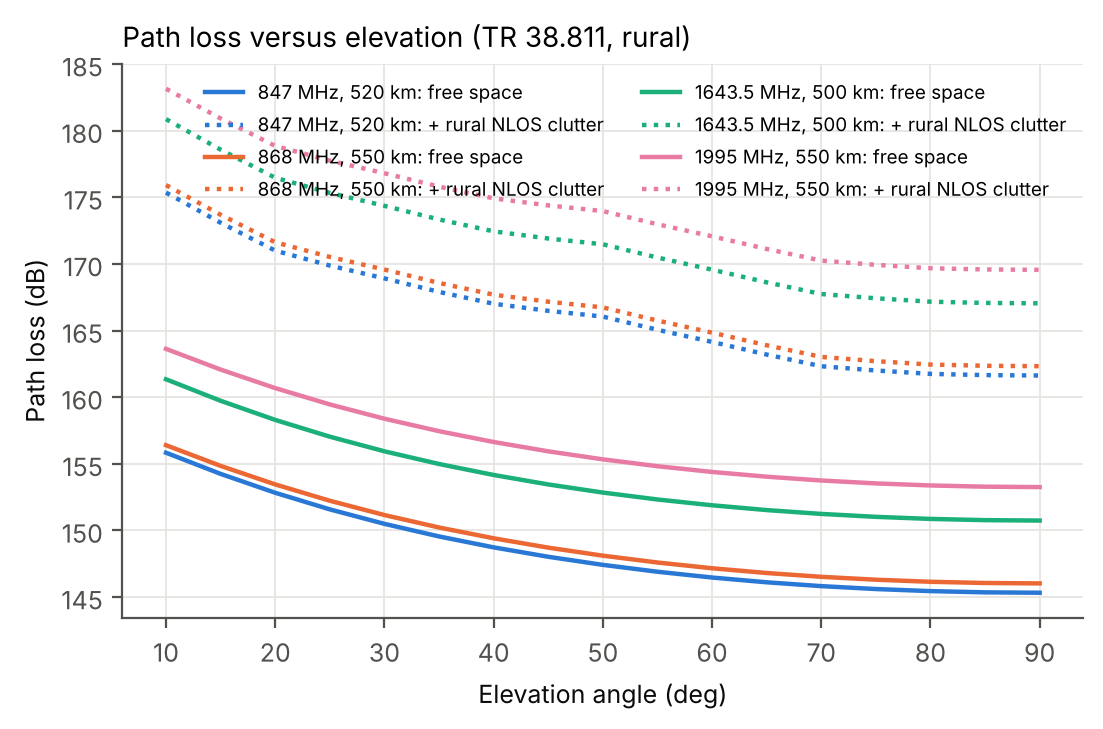

In [34]:
from IPython.display import Image
Image("out/figs/fig01_path_loss.png", width=900)

**fig02_link_margin.** Uplink margin versus elevation (LOS median).

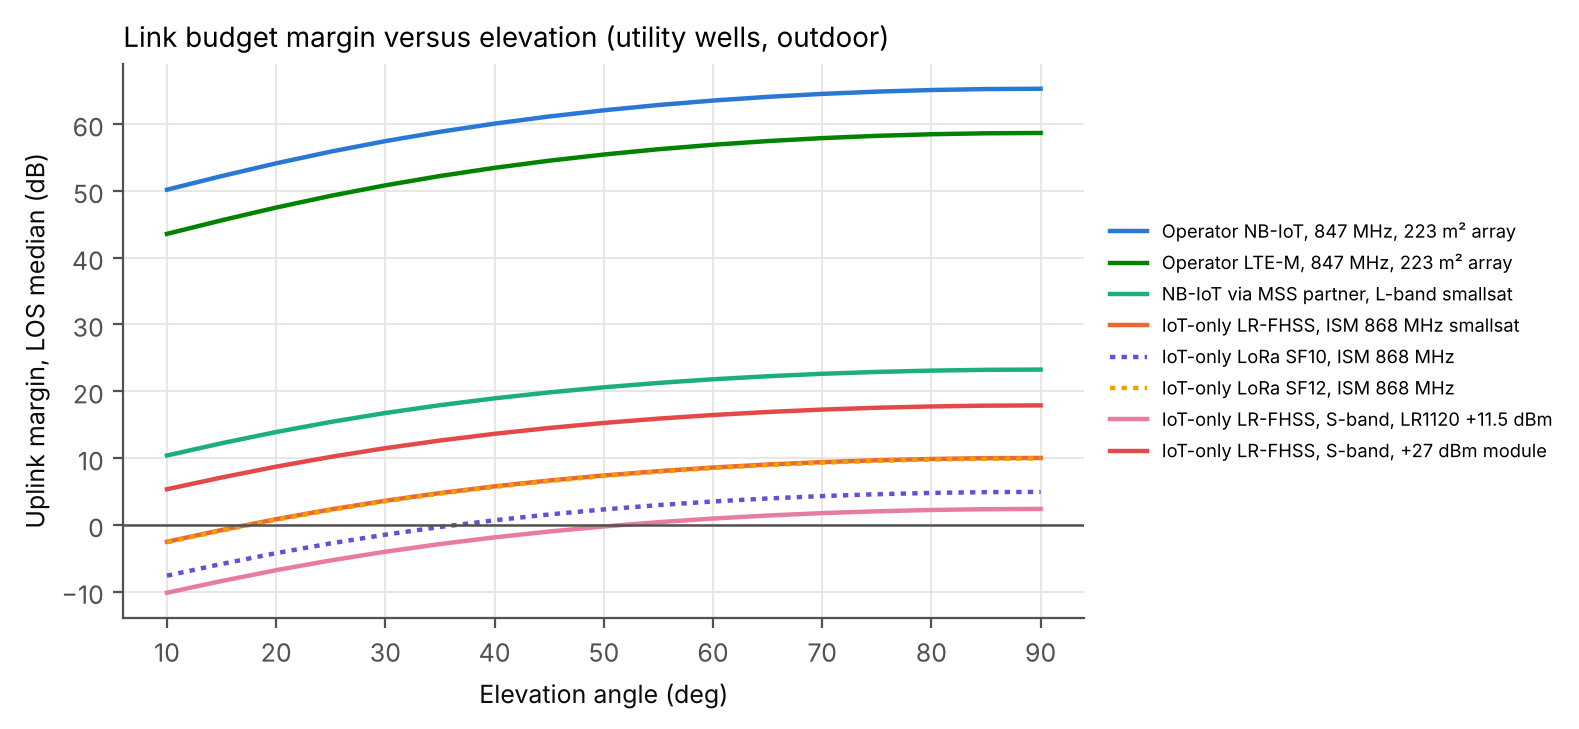

In [35]:
from IPython.display import Image
Image("out/figs/fig02_link_margin.png", width=900)

**fig03_coverage_probability.** Probability the link closes versus elevation.

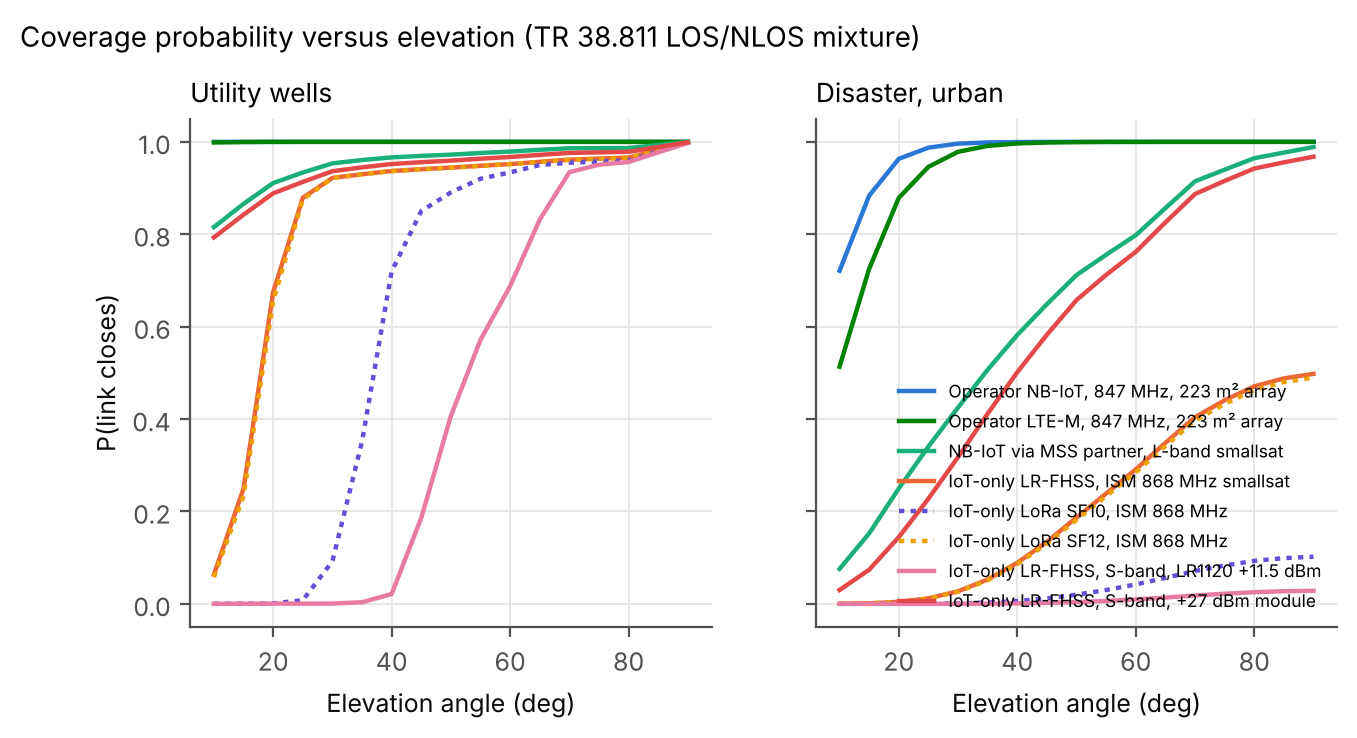

In [36]:
from IPython.display import Image
Image("out/figs/fig03_coverage_probability.png", width=900)

**fig04_cell_radius.** Cell radius and satellite service radius.

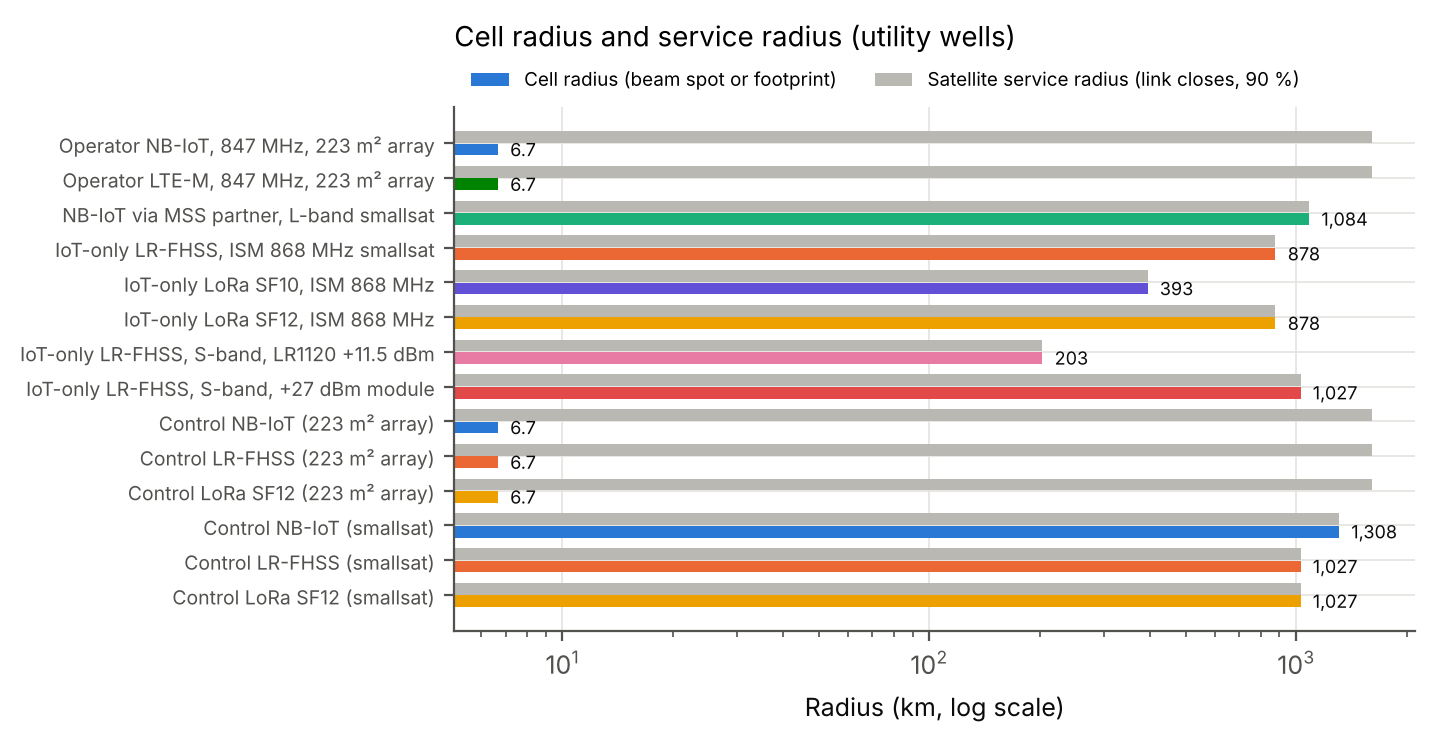

In [37]:
from IPython.display import Image
Image("out/figs/fig04_cell_radius.png", width=900)

**fig05_time_coverage.** Fraction of the day a satellite is in view and the link closes.

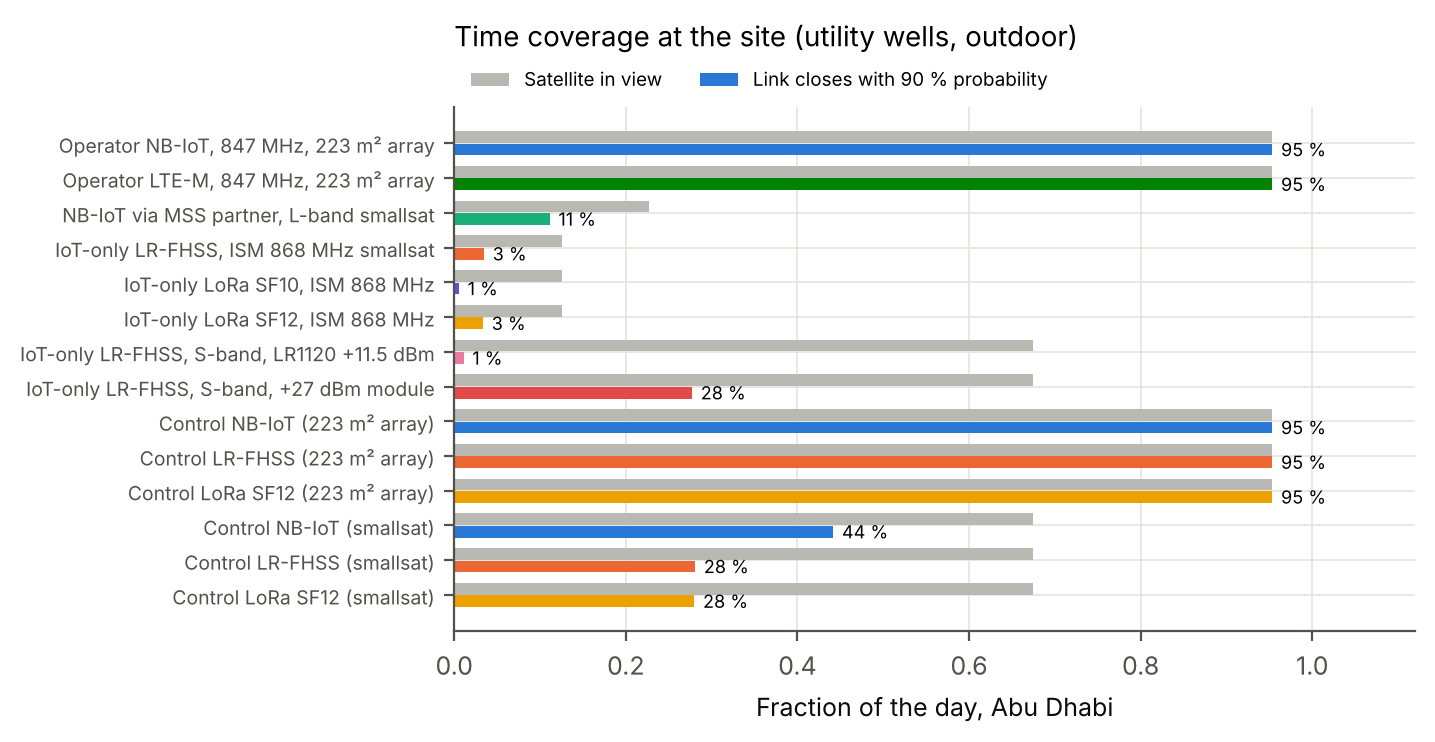

In [38]:
from IPython.display import Image
Image("out/figs/fig05_time_coverage.png", width=900)

**fig06_interference.** Noise rise from ISM devices and from co-channel terrestrial UEs.

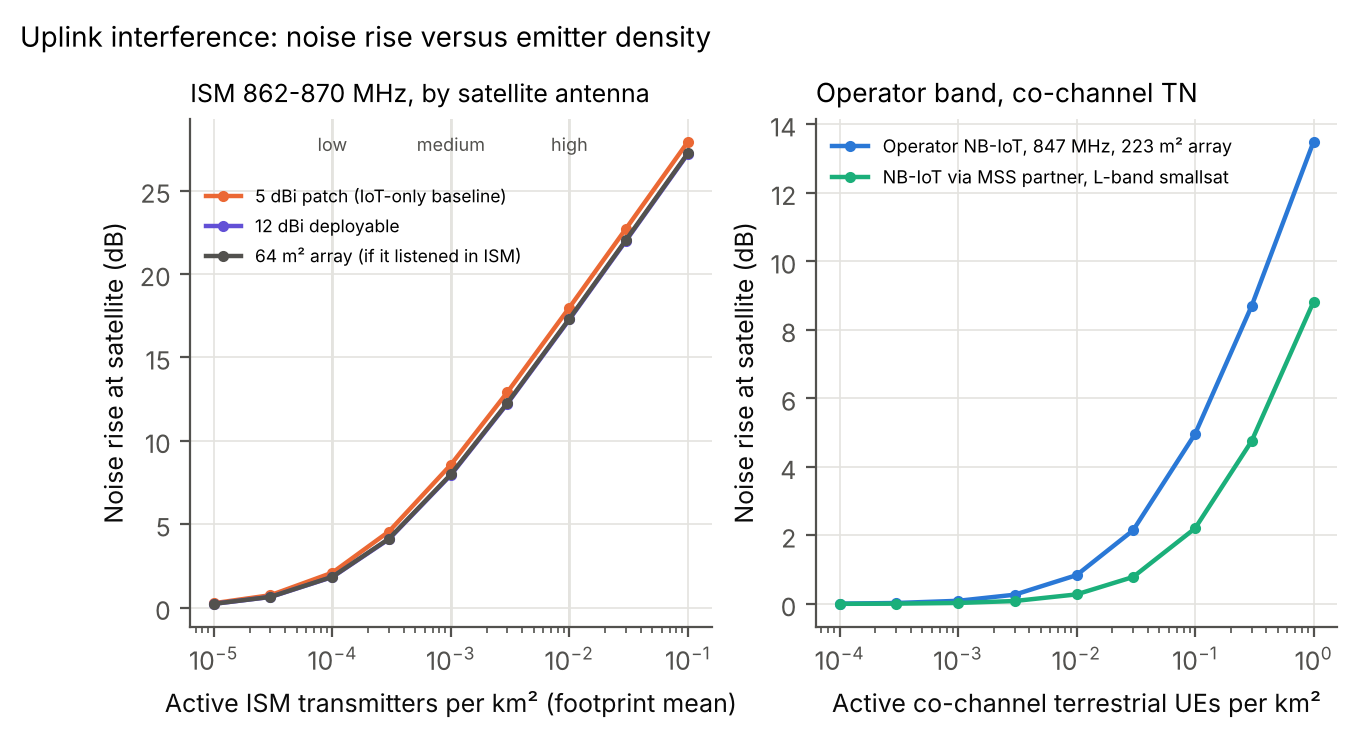

In [39]:
from IPython.display import Image
Image("out/figs/fig06_interference.png", width=900)

**fig07_throughput.** Per-device information rate versus elevation.

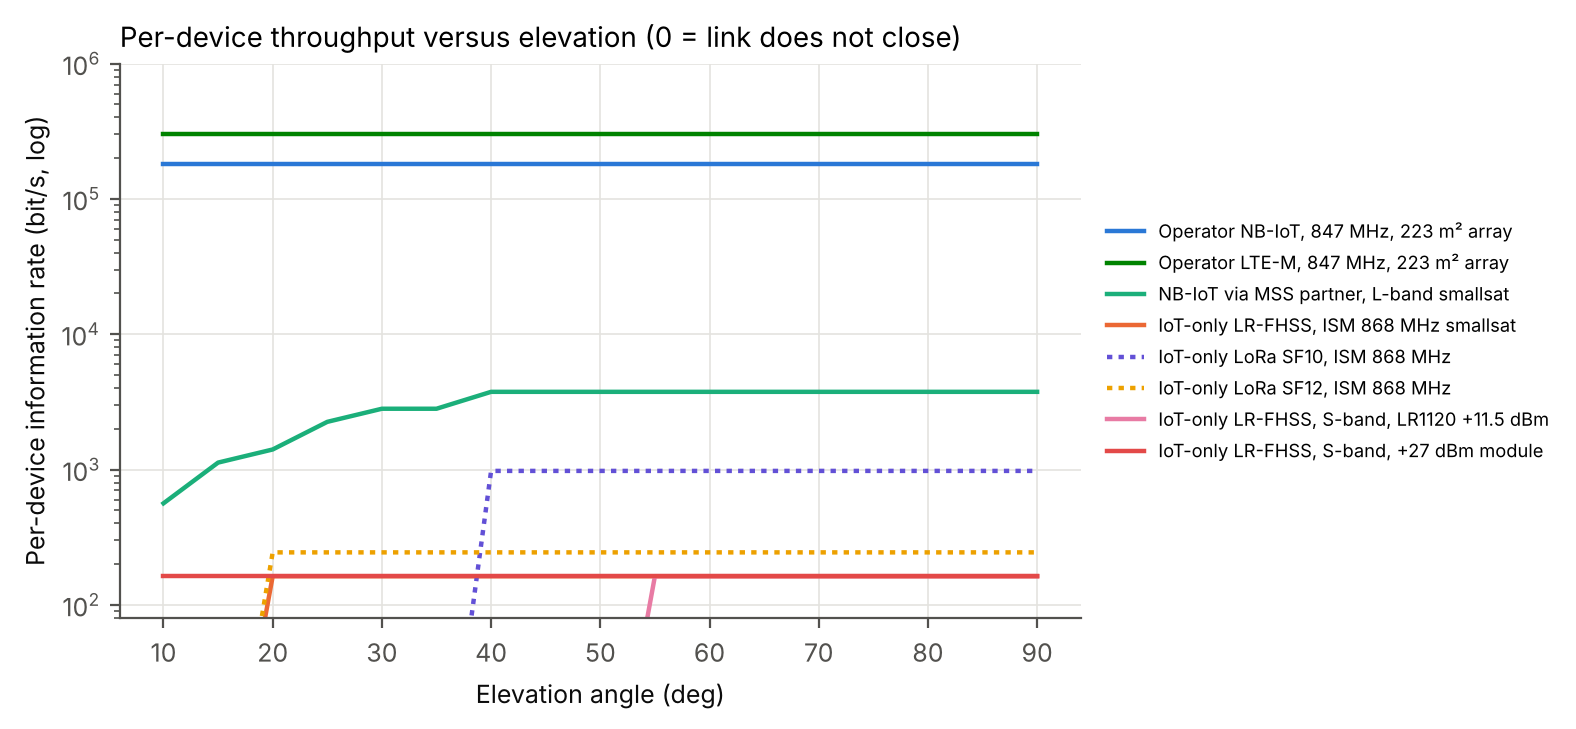

In [40]:
from IPython.display import Image
Image("out/figs/fig07_throughput.png", width=900)

**fig08_goodput.** Delivered goodput per cell versus load.

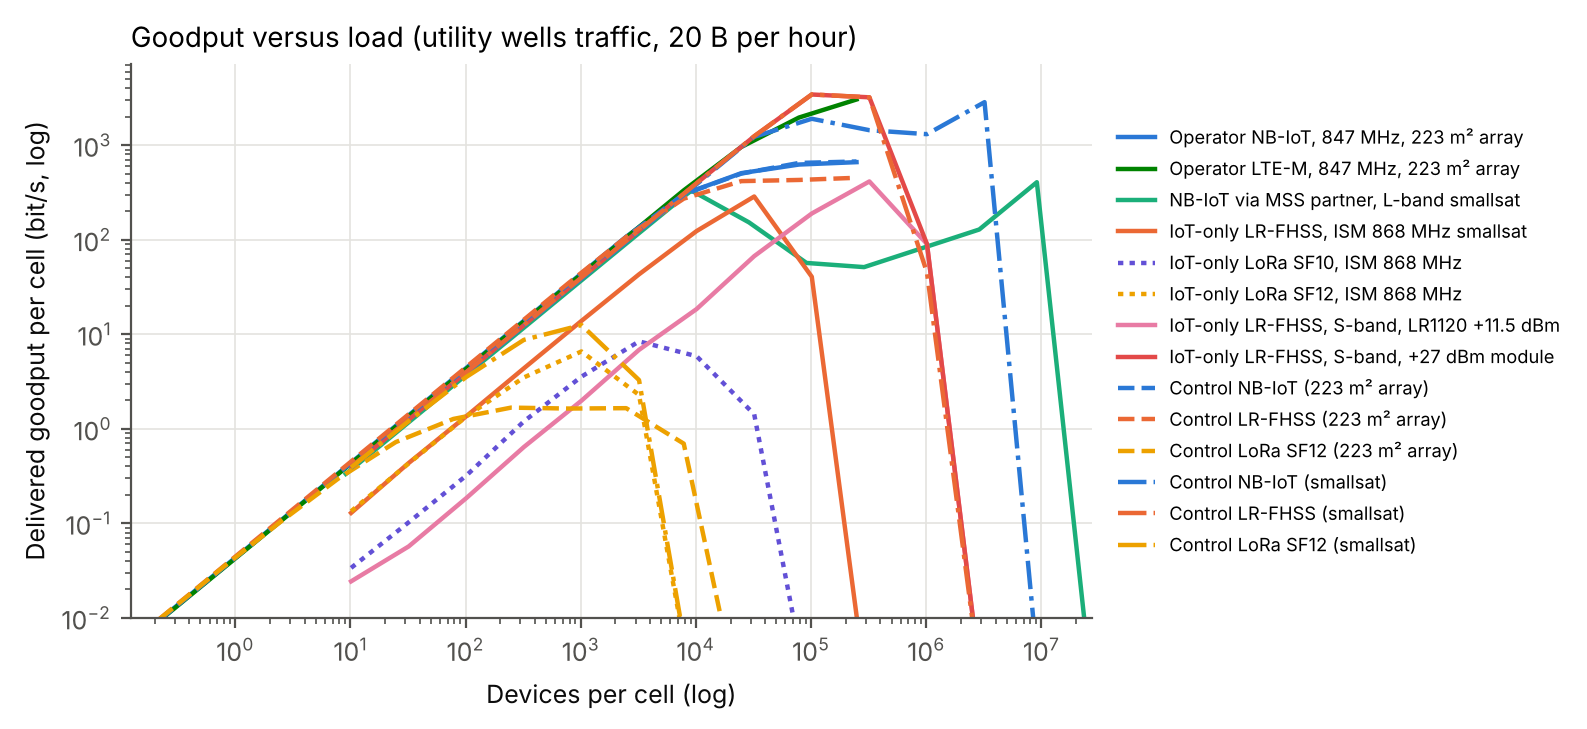

In [41]:
from IPython.display import Image
Image("out/figs/fig08_goodput.png", width=900)

**fig09_capacity.** Service capacity (mean of 10 replications, 95 % CI) and contention capacity.

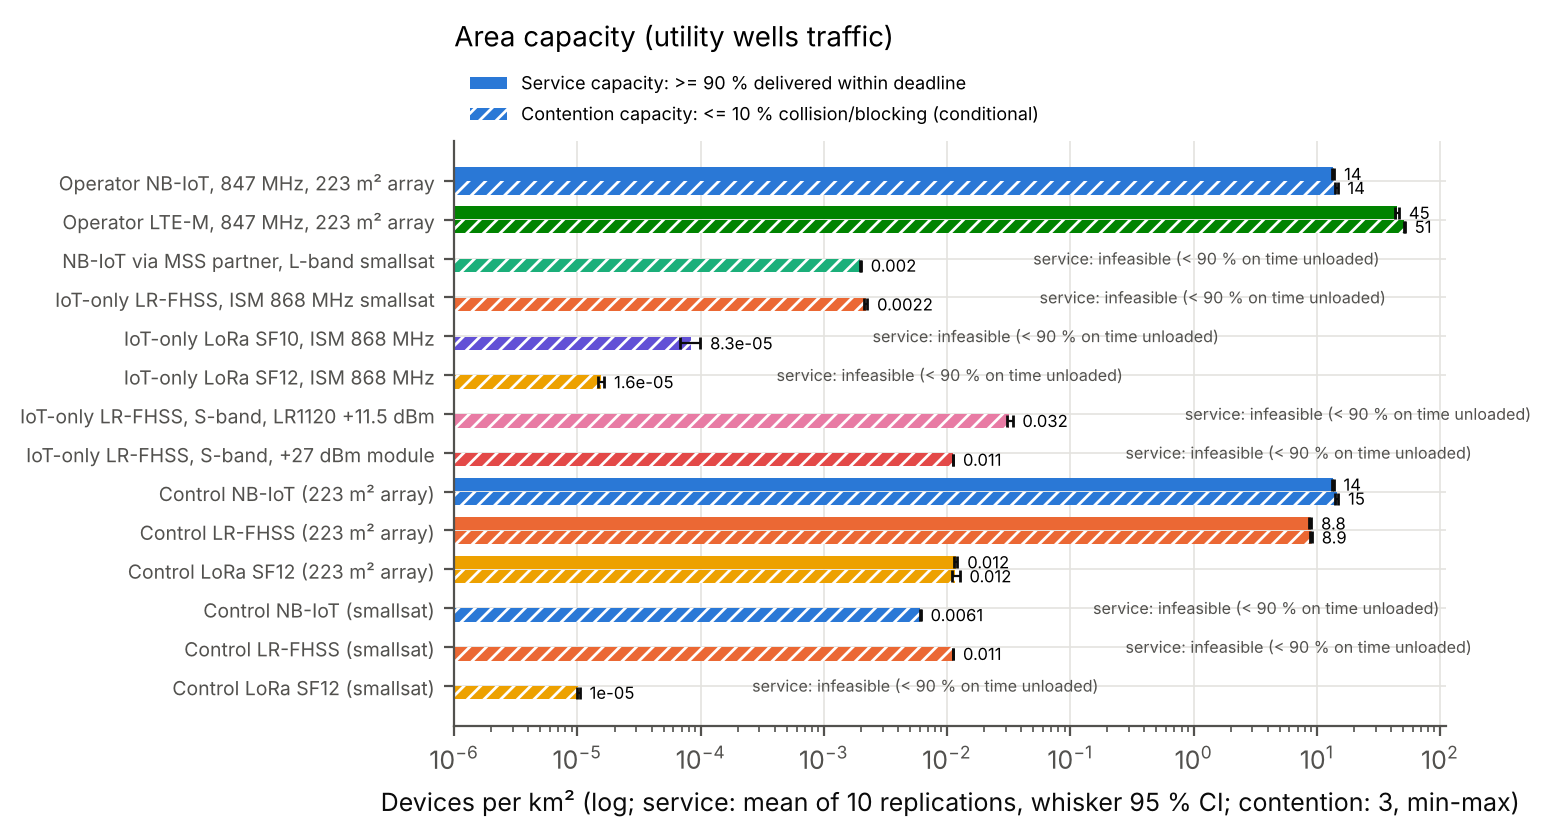

In [42]:
from IPython.display import Image
Image("out/figs/fig09_capacity.png", width=900)

**fig10_pdr_matrix.** Delivered within deadline, stack x scenario.

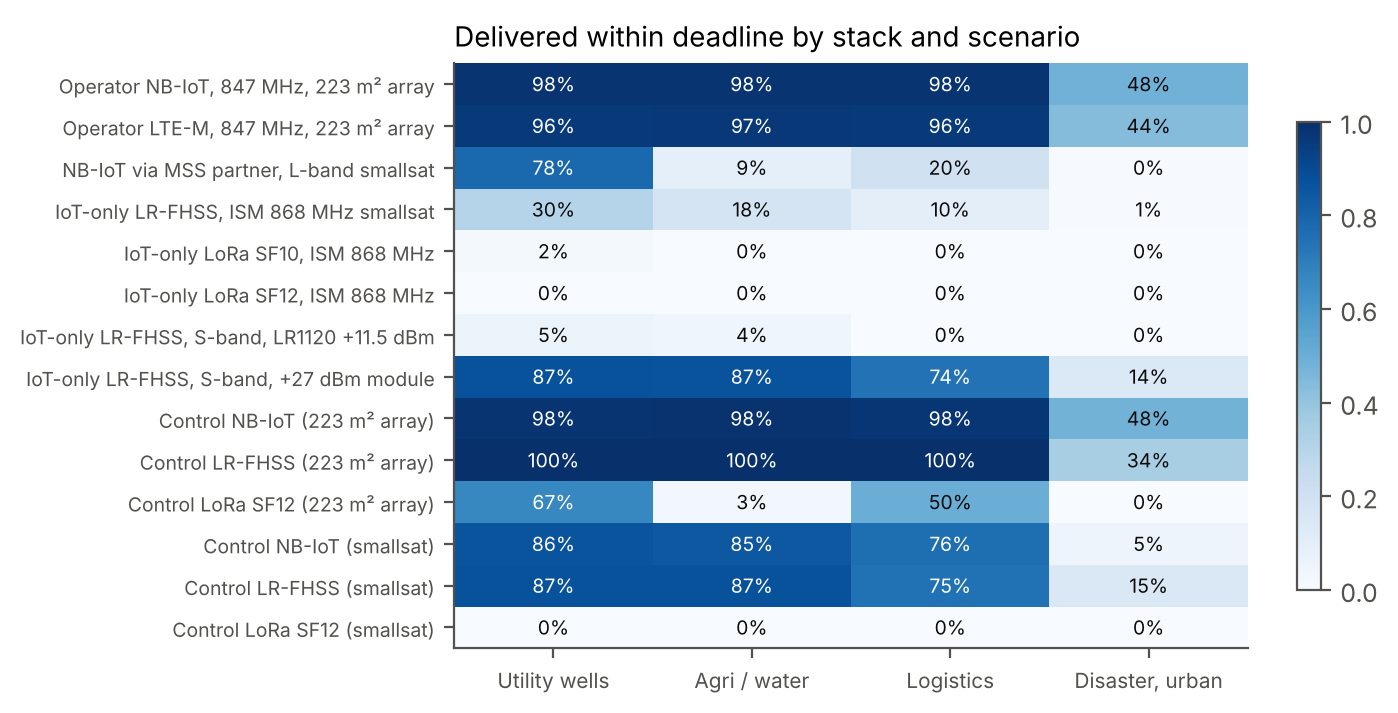

In [43]:
from IPython.display import Image
Image("out/figs/fig10_pdr_matrix.png", width=900)

**fig11_battery_matrix.** Battery life, stack x scenario.

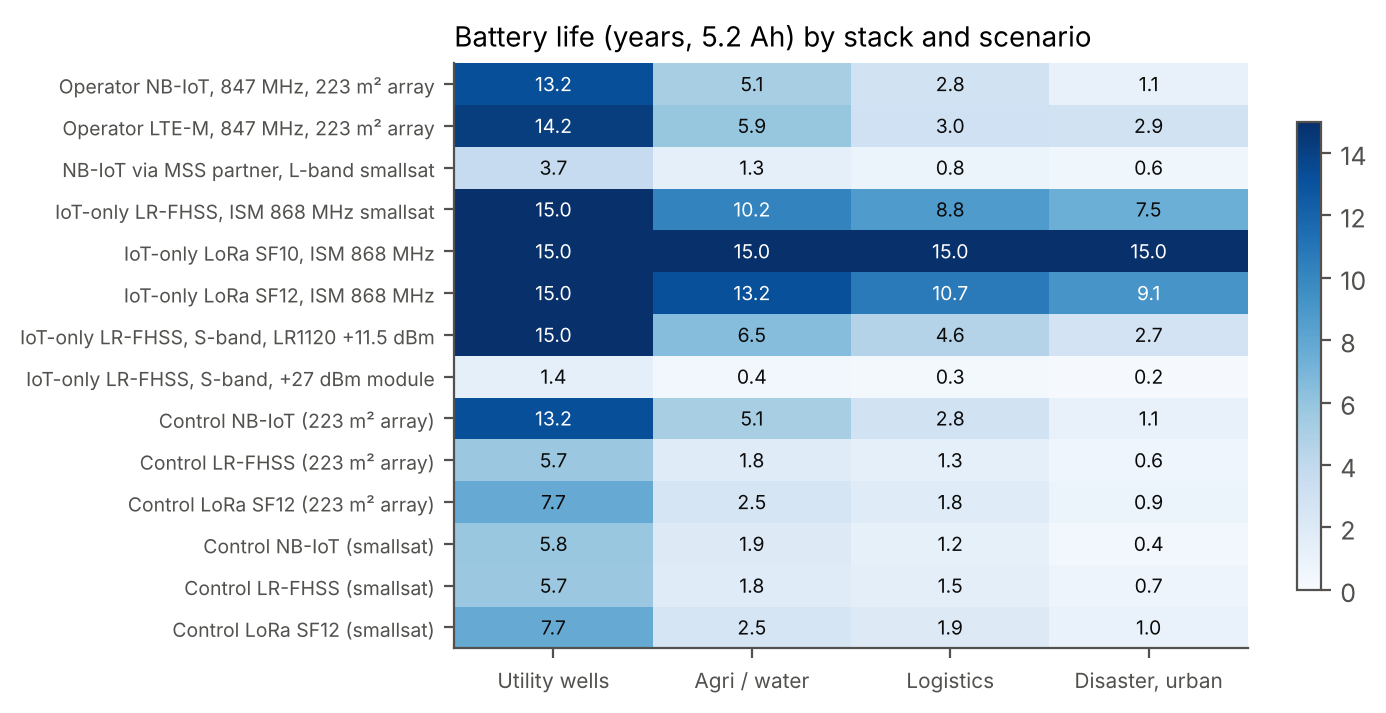

In [44]:
from IPython.display import Image
Image("out/figs/fig11_battery_matrix.png", width=900)

**fig12_latency_cdf.** Latency distribution.

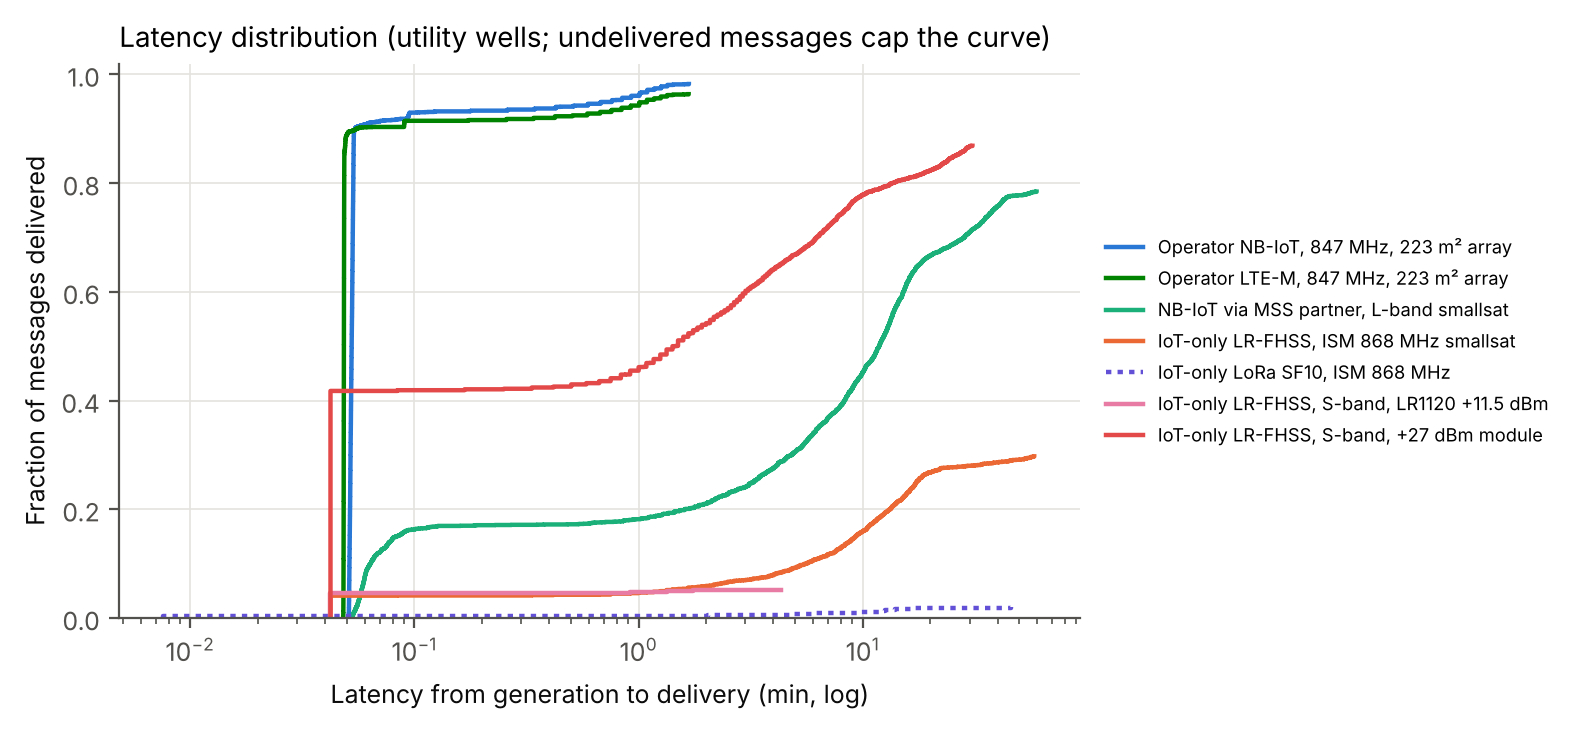

In [45]:
from IPython.display import Image
Image("out/figs/fig12_latency_cdf.png", width=900)

**fig13_control_air_interface.** Same satellite, band and power: air interface only.

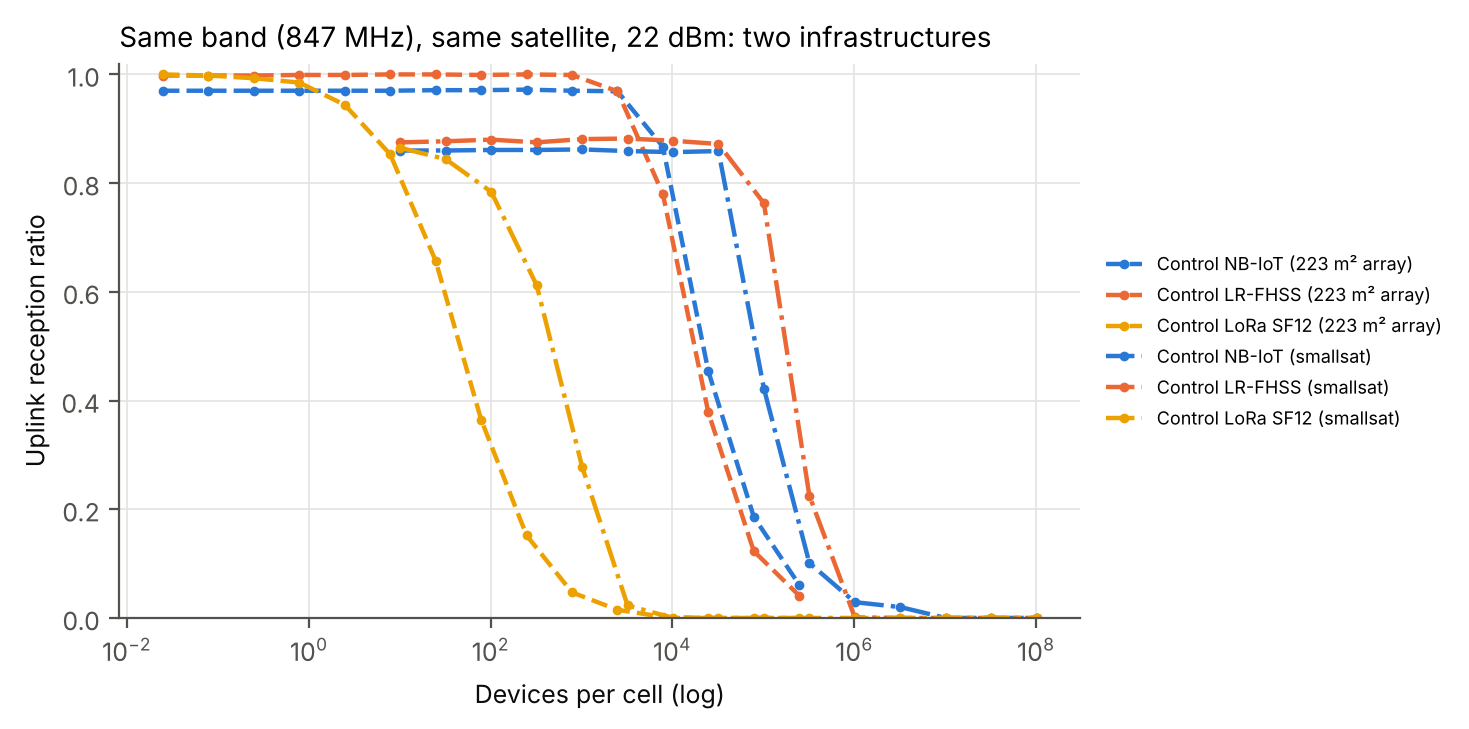

In [46]:
from IPython.display import Image
Image("out/figs/fig13_control_air_interface.png", width=900)

**fig14_sensitivity.** Sensitivity of delivery to assumptions.

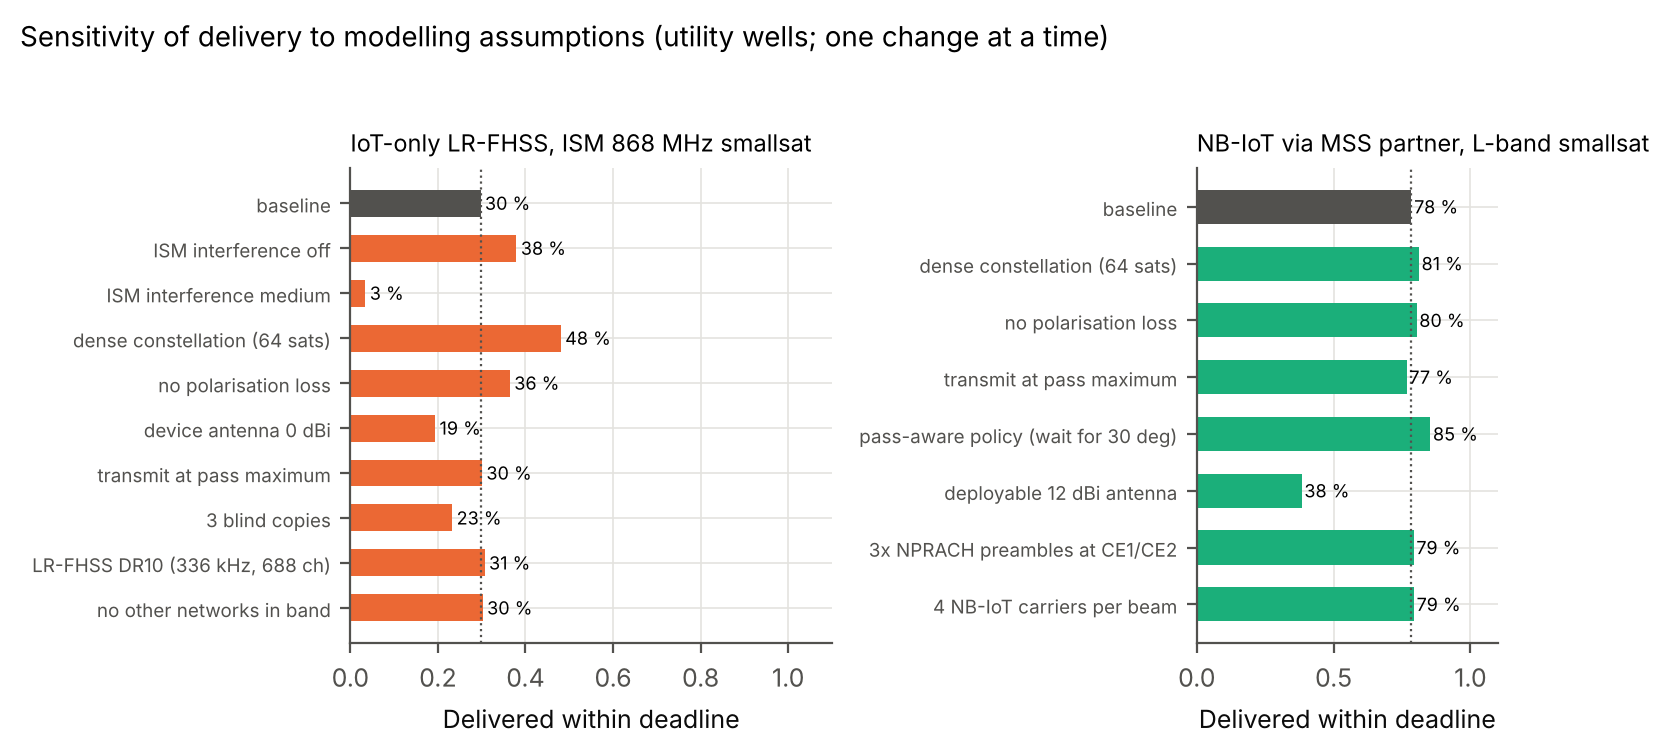

In [47]:
from IPython.display import Image
Image("out/figs/fig14_sensitivity.png", width=900)

**fig15_spectral_efficiency.** Delivered on-time messages per second per allocated MHz at service capacity.

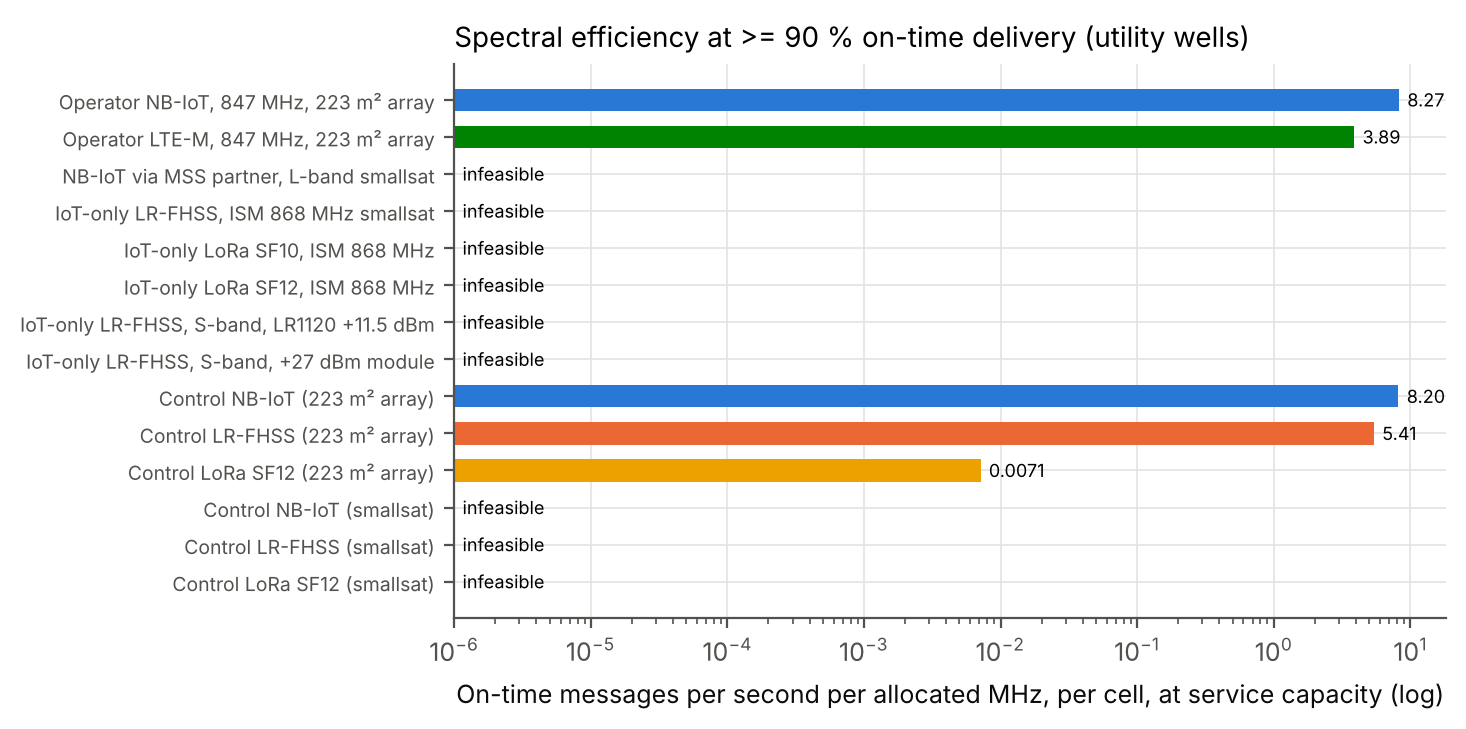

In [48]:
from IPython.display import Image
Image("out/figs/fig15_spectral_efficiency.png", width=900)

**fig16_policy_matrix.** Service capacity of the controls under both transmit policies (10 replications, 95 % CI).

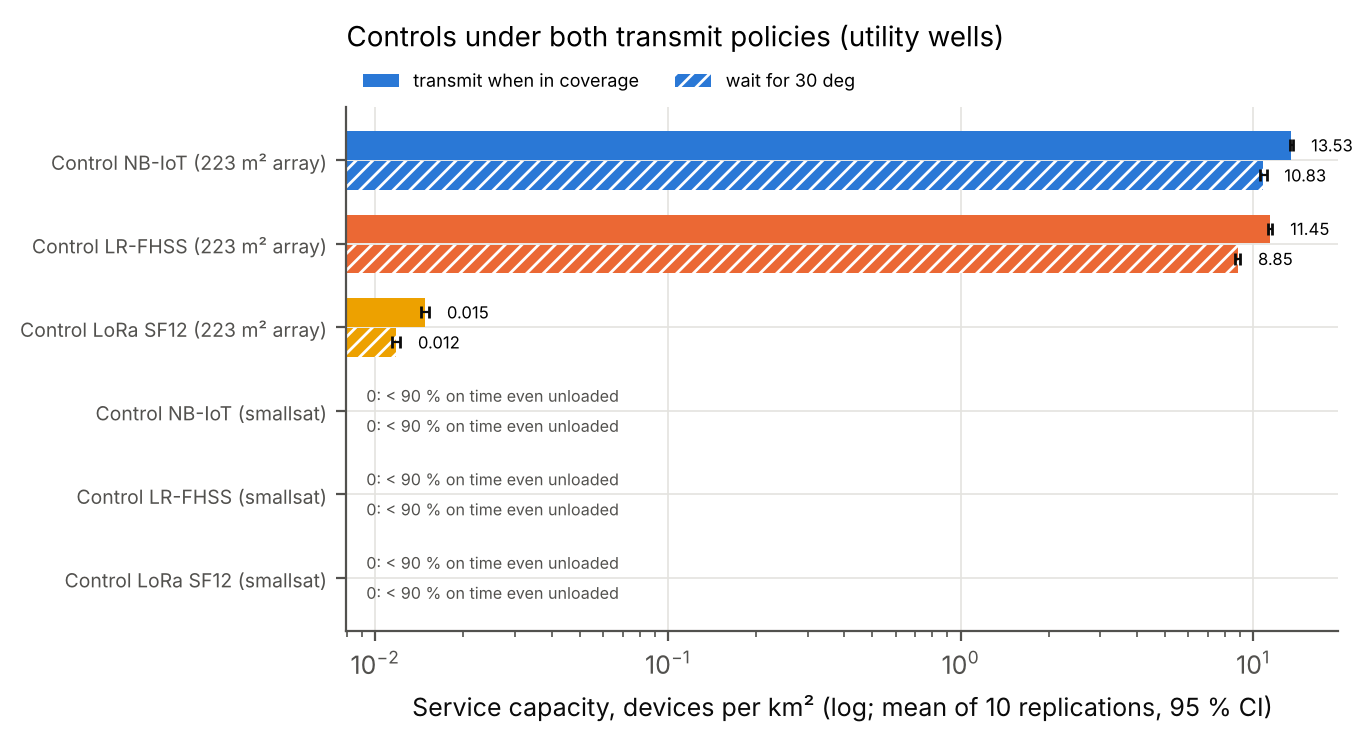

In [49]:
from IPython.display import Image
Image("out/figs/fig16_policy_matrix.png", width=900)

### 5.11 Spectral efficiency and equal-infrastructure controls

In [50]:
rows = []
for s in SM["utility_wells"]:
    r = SM["utility_wells"][s]; sv = R["capacity"]["utility_wells"][s]["service"]
    a = r.get("alloc_hz")
    rows.append(dict(stack=s, alloc_kHz=(a or 0) / 1e3, on_time=r["pdr_deadline"],
                     service_capacity_per_cell=sv.get("devices_per_cell"),
                     on_time_at_capacity=sv.get("on_time_at_capacity"),
                     on_time_msgs_per_s_per_MHz_at_capacity=(sv.get("devices_per_cell") or 0) * (sv.get("on_time_at_capacity") or 0) / 3600 / (a / 1e6) if a else None))
pd.DataFrame(rows).round(4)

,stack,alloc_kHz,on_time,service_capacity_per_cell,on_time_at_capacity,on_time_msgs_per_s_per_MHz_at_capacity
0,OP-LB-NBIOT,200.0,0.9823,6646.6519,0.8960,8.2711
1,OP-LB-LTEM,1400.0,0.9637,21842.9156,0.8980,3.8920
2,OP-MSS-NBIOT,200.0,0.7843,0.0000,NaN,0.0000
3,IO-ISM-LRFHSS,137.0,0.2973,0.0000,NaN,0.0000
4,IO-ISM-LORA-SF10,1000.0,0.0193,0.0000,NaN,0.0000
5,IO-ISM-LORA-SF12,1000.0,0.0000,0.0000,NaN,0.0000
6,IO-SBAND-LRFHSS,137.0,0.0513,0.0000,NaN,0.0000
7,IO-SBAND-LRFHSS-HP,137.0,0.8687,0.0000,NaN,0.0000
8,CTRL-NBIOT,200.0,0.9790,6586.2934,0.8961,8.1972
9,CTRL-LRFHSS,200.0,0.9983,4306.8908,0.9048,5.4123


### 5.12 Technology x transmit policy (controls) and orbital phase

In [51]:
display(pd.DataFrame(R["policy_matrix"]).round(4))
print("Seed-paired capacity ratios (NB-IoT / LR-FHSS) under matched transmit policy")
display(pd.DataFrame(R["policy_ratios"]))
print("On-time fraction by arrival window (orbital phase; overlapping windows, a sensitivity), utility wells")
display(pd.DataFrame(R["orbital_phase"]).round(3))

,stack,policy,on_time,on_time_ci95,service_per_km2,service_ci95,service_note,contention_per_km2,contention_min,contention_max
0,CTRL-NBIOT,first_visible,0.9790,"[0.9732232939764138, 0.9835515239767034]",13.5317,"[13.327791087470334, 13.735627094565066]",,14.6379,14.1053,14.9629
1,CTRL-NBIOT,elev_threshold,0.9857,"[0.9807497514722866, 0.9893413478719667]",10.8340,"[10.548826548355196, 11.119222712851423]",,11.6627,11.5860,11.8162
2,CTRL-LRFHSS,first_visible,0.9983,"[0.9961041274235806, 0.9992879065638308]",11.4485,"[11.251858464463346, 11.645084111882433]",,11.7429,11.3156,11.9565
3,CTRL-LRFHSS,elev_threshold,0.9983,"[0.9961041274235806, 0.9992879065638308]",8.8486,"[8.657702366590604, 9.039533456702157]",,8.9372,8.8311,9.1494
4,CTRL-LORA-SF12,first_visible,0.7123,"[0.6958711024360847, 0.728252459871595]",0.0148,"[0.014274900577976275, 0.015261984170534197]",,0.0145,0.0142,0.0151
5,CTRL-LORA-SF12,elev_threshold,0.6653,"[0.648245578346794, 0.6819982001533773]",0.0118,"[0.011352362502295335, 0.012148732326916498]",,0.0116,0.0110,0.0127
6,CTRL-SS-NBIOT,first_visible,0.8630,"[0.8502304518035252, 0.8748410699438266]",0.0000,None,infeasible: requirement not met even at 1 devi...,0.0061,0.0060,0.0061
7,CTRL-SS-NBIOT,elev_threshold,0.8777,"[0.865455686219546, 0.888911654588305]",0.0000,None,infeasible: requirement not met even at 1 devi...,0.0064,0.0063,0.0064
8,CTRL-SS-LRFHSS,first_visible,0.8500,"[0.8367750802639456, 0.862329692770691]",0.0000,None,infeasible: requirement not met even at 1 devi...,0.0102,0.0101,0.0104
9,CTRL-SS-LRFHSS,elev_threshold,0.8703,"[0.8578367455240655, 0.8818826857535359]",0.0000,None,infeasible: requirement not met even at 1 devi...,0.0111,0.0111,0.0112


Seed-paired capacity ratios (NB-IoT / LR-FHSS) under matched transmit policy


,a,b,policy,ratio,ratio_ci95,replications,method,note
0,CTRL-NBIOT,CTRL-LRFHSS,first_visible,1.182039,"[1.159673623518103, 1.204835880509806]",10,"seed-paired, Student-t interval on log ratio",NaN
1,CTRL-NBIOT,CTRL-LRFHSS,elev_threshold,1.224170,"[1.197422254956657, 1.2515156022464662]",10,"seed-paired, Student-t interval on log ratio",NaN
2,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,first_visible,NaN,None,0,NaN,undefined: zero capacity in at least one repli...
3,CTRL-SS-NBIOT,CTRL-SS-LRFHSS,elev_threshold,NaN,None,0,NaN,undefined: zero capacity in at least one repli...


On-time fraction by arrival window (orbital phase; overlapping windows, a sensitivity), utility wells


,6h,12h,18h
OP-LB-NBIOT,0.983,0.982,0.984
OP-LB-LTEM,0.969,0.964,0.967
OP-MSS-NBIOT,0.803,0.784,0.792
IO-ISM-LRFHSS,0.281,0.297,0.304
IO-ISM-LORA-SF10,0.017,0.019,0.022
IO-ISM-LORA-SF12,0.000,0.000,0.001
IO-SBAND-LRFHSS,0.046,0.051,0.044
IO-SBAND-LRFHSS-HP,0.872,0.869,0.869
CTRL-NBIOT,0.982,0.979,0.981
CTRL-LRFHSS,0.999,0.998,1.000


### 5.13 Exploratory chronological scheduler comparison (operator NB-IoT)
Not a validation of the engine queue: the reference runs deadline-aware FIFO or smallest-cost priority without the engine's admission, and counts scheduling completions only (PHY failures excluded). Reported as a policy comparison; matched validation is an open item. The LR-FHSS approximation check near the 200-packet switch follows.

In [52]:
rows = []
for x in R["reference_scheduler"]:
    rows.append(dict(scenario=x["scenario"], load_scale=round(x["load_scale"], 1), admission=x["admission"],
                     calibration=x["calibration"], reference_policy=x["reference_policy"], requests=x["requests"],
                     ref_served=x["reference"]["served_fraction"],
                     ref_served_device_weighted=x["reference"]["served_fraction_device_weighted"],
                     engine_served=x["engine"]["served_fraction"], ref_mean_wait_s=x["reference"]["mean_wait_s"],
                     engine_mean_wait_s=x["engine"]["mean_wait_s"], ref_utilisation=x["reference"]["utilisation"],
                     engine_rho_max=x["engine"]["rho_max"]))
display(pd.DataFrame(rows).round(4))
print("LR-FHSS element-level approximation vs enumeration near the 200-packet switch")
pd.DataFrame(R["lrfhss_branch_boundary"]).round(4)

,scenario,load_scale,admission,calibration,reference_policy,requests,ref_served,ref_served_device_weighted,engine_served,ref_mean_wait_s,engine_mean_wait_s,ref_utilisation,engine_rho_max
0,utility_wells,262.8,uniform,hardware,fifo,549646,0.9814,0.9932,1.0000,0.0003,0.0002,0.0802,0.1862
1,utility_wells,788.3,uniform,hardware,fifo,493462,0.9944,0.9990,1.0000,0.0002,0.0002,0.0773,0.1631
2,disaster_urban,1.0,uniform,hardware,fifo,613299,0.9918,0.9927,0.9969,0.0112,0.0213,0.2813,0.6925
3,disaster_urban,1.0,uniform,link_level,fifo,845793,0.7221,0.7453,0.6489,67.3431,0.5910,0.9188,2.5582
4,disaster_urban,1.0,cheapest_first,hardware,cost,613299,0.9918,0.9927,0.9969,0.0083,0.0213,0.2813,0.6925
5,disaster_urban,1.0,cheapest_first,link_level,cost,850376,0.9361,0.9415,0.9179,2.6265,0.2163,0.9092,2.5582


LR-FHSS element-level approximation vs enumeration near the 200-packet switch


,target_above_pool_db,same_grid_packets,enumeration,element_branch,difference,se
0,10.0,150,0.5400,0.5667,0.0267,0.0287
1,10.0,200,0.2317,0.2250,-0.0067,0.0242
2,10.0,250,0.0767,0.0417,-0.0350,0.0136
3,15.0,150,0.9667,0.9717,0.0050,0.0100
4,15.0,200,0.9383,0.9100,-0.0283,0.0153
5,15.0,250,0.8417,0.8450,0.0033,0.0210


### 5.13b Monte Carlo convergence of service capacity

In [53]:
pd.DataFrame({s: {c["n_mc"]: c["devices_per_km2"] for c in rows} for s, rows in R["convergence"].items()}).round(3)

,CTRL-NBIOT,CTRL-LRFHSS
1000,13.561,9.222
3000,13.141,8.831
6000,13.038,9.042


### 5.14 Change against previous versions

In [54]:
import os
for f in ("out/change_vs_v1.csv", "out/change_vs_v1_2.csv", "out/change_vs_v1_3.csv", "out/change_vs_v1_4.csv"):
    if os.path.exists(f):
        print(f); display(pd.read_csv(f))
    else:
        print(f, "not available in this runtime (previous results ship in the package)")

out/change_vs_v1.csv not available in this runtime (previous results ship in the package)
out/change_vs_v1_2.csv not available in this runtime (previous results ship in the package)
out/change_vs_v1_3.csv not available in this runtime (previous results ship in the package)
out/change_vs_v1_4.csv not available in this runtime (previous results ship in the package)


### 5.15 Parameter provenance

In [55]:
pd.DataFrame(list(R["meta"]["param_sources"].items()), columns=["parameter", "source or status"])

,parameter,source or status
0,LoRa SNR thresholds,Semtech SX126x/SX127x datasheets (SF7 -7.5 dB ...
1,LoRa time on air,Semtech AN1200.13
2,LoRaWAN MAC overhead 13 B,LoRaWAN L2 1.0.4 frame format
3,LoRa Doppler tolerance,"assumed: offset <= 25% BW, drift/symbol <= 0.5..."
4,LR-FHSS DR table,LoRaWAN RP002-1.0.4 regional parameters
5,LR-FHSS header/fragment durations,"233.472 ms / 102.4 ms (RP002, Boquet et al. 2021)"
6,LR-FHSS frame,"RP002-1.0.5: ((L+2)*8+6)/CR coded bits, 48 bit..."
7,LR-FHSS SNR threshold,"assumed: 4 dB (CR 1/3), 7 dB (CR 2/3)"
8,LR-FHSS Doppler tolerance,assumed: drift over one header <= 50% of 488 Hz
9,NB-IoT (legacy continuous model) floor 316 bit/s,only used when nbiot_model='continuous'; back-...


In [56]:
#@title Download results (JSON, CSV, figures)
import shutil
shutil.make_archive("ntnsim_results", "zip", "out")
try:
    from google.colab import files
    files.download("ntnsim_results.zip")
except ImportError:
    print("ntnsim_results.zip written")

ntnsim_results.zip written
